# Projekt 1 - model ratingowy z interpretowalnością, wyjaśnialnością i kalibracją do 4%

**Zbiór:** `zbior_13.csv` - sprawozdania finansowe 3000 spółek z o.o. i flaga `default`.

**Dwa modele:**
- **interpretowalny** - karta scoringowa: binning monotoniczny → WoE → regresja logistyczna (Lab 1),
- **black-box** - XGBoost strojony w walidacji krzyżowej (Lab 3, krok 3).

**Kolejność kroków** (Lab 3, sześć kroków Projektu 1):

| Sekcja | Krok |
|---|---|
| 1-2 | dane, jakość danych, przeciek, podział |
| 3 | EDA |
| 4-5 | cechy i model interpretowalny |
| 6 | black-box i porównanie |
| 7-9 | wyjaśnienia globalne (SHAP, ważność grup cech - 7.3.1) i lokalne, PDP / ICE / ALE, interakcje (8.4), LIME |
| 10 | wierność i stabilność wyjaśnień |
| 11 | kalibracja statystyczna i dostosowanie do 4% |
| 12 | ratingi, próg decyzyjny, firma graniczna modelu końcowego (12.3.1), porównanie decyzji, global surrogate (12.6) |
| 13 | analiza kontrfaktyczna |
| 14 | audyt podgrup, monitoring, podsumowanie |

**Konwencje:** `default = 1` to zdarzenie ryzyka, model zwraca PD = P(default = 1). **train** - uczenie modeli i wszystkich
przekształceń, **valid** - kalibracja, wybór metody kalibracji i progu, **test** - wyłącznie ocena końcowa.
Fragmenty kodu przeniesione z laboratoriów są oznaczone komentarzem `# z Lab N` (regulamin pkt 10.5).

## 0. Środowisko i parametry

In [1]:
import sys, warnings, json, itertools
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn, xgboost, shap, lime
from scipy.special import logit, expit
from scipy.stats import spearmanr, binomtest, beta as beta_dist
from sklearn.metrics import (roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
                             log_loss, brier_score_loss)
from sklearn.model_selection import train_test_split, StratifiedKFold

print("Python:", sys.version.split()[0], "| numpy:", np.__version__, "| pandas:", pd.__version__,
      "| scikit-learn:", sklearn.__version__, "| xgboost:", xgboost.__version__, "| shap:", shap.__version__,
      "| matplotlib:", matplotlib.__version__)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams["figure.figsize"] = (7, 4.5)
KOL = {"train": "#3E5C76", "valid": "#C9A227", "test": "#A3262C", "logit": "#3E5C76", "black-box": "#A3262C"}   # z Lab 3
EPS = 1e-6
RNG_SEED = 42
TARGET_PD = 0.04                    # wymóg Projektu 1: tendencja centralna PD = 4%
MARGIN, LGD = 0.10, 0.45            # ekonomia decyzji (sekcja 12)
TARGET = "default"

Python: 3.12.8 | numpy: 2.4.6 | pandas: 3.1.1 | scikit-learn: 1.9.1 | xgboost: 3.2.0 | shap: 0.51.0 | matplotlib: 3.11.2


/Users/maksymilian.tabian/Desktop/Studia/InterpretableML/projekt1/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Dane i jakość danych

### 1.1 Definicja PD i słownik danych

Wczytujemy dane firm. Zmienna `default` informuje, czy wystąpiło zdarzenie ryzyka (`1` - tak, `0` - nie).
Model ma oszacować PD, czyli prawdopodobieństwo tego zdarzenia w przyjętym horyzoncie.

Firmę oceniamy na podstawie ostatniego sprawozdania finansowego, danych rejestrowych i trzech wskaźników
branżowych `wsk_index_*`. Prowadzący potwierdził, że te wskaźniki nie zawierają informacji z przyszłości.

Sprawdzamy wielkość zbioru, udział defaultów (DR) i obszary opisane w słowniku. Brak daty oceny
i identyfikatora firmy ogranicza sposób podziału danych (1.4).

In [6]:
df = pd.read_csv("dane/zbior_13.csv")
print("Podstawowe informacje o zbiorze:")
print(f"Liczba obserwacji: {len(df):,}")
print(f"Liczba cech: {df.shape[1] - 1}")
print(f"Liczba defaultów: {df[TARGET].sum()}")
print(f"Udział defaultów (DR): {df[TARGET].mean():.2%}")

opis = pd.read_csv("dane/opis_zmiennych.csv")          # słownik z Dane_Opis_zmiennych.pdf: zmienna -> obszar
obszar = dict(zip(opis["zmienna"].str.replace("dlugu", "długu"), opis["obszar"]))       # w danych: wsk_koszt_długu_*
print("\nLiczba cech według obszaru:")
print(pd.Series([obszar.get(c, "brak w słowniku") for c in df.columns if c != TARGET]).value_counts().to_string())
print("\nCechy bez opisu w słowniku:", [c for c in df.columns if c != TARGET and c not in obszar])
print("\nPrzykładowe trzy obserwacje (wybrane kolumny):")
display(df[["pkdKod", "formaWlasnosci_Symbol", "Aktywa", TARGET]].head(3))

Podstawowe informacje o zbiorze:
Liczba obserwacji: 3,000
Liczba cech: 222
Liczba defaultów: 445
Udział defaultów (DR): 14.83%

Liczba cech według obszaru:
wskaźnik finansowy         136
pozycja bilansu             54
pozycja RZiS                22
brak w słowniku              5
rachunek przepływów          2
szczególna forma prawna      1
forma własności              1
PKD                          1

Cechy bez opisu w słowniku: ['wsk_index_aktywne', 'wsk_index_skr_zaw', 'wsk_index_nowe', 'schemat_wsk_bilans', 'schemat_wsk_rzis']

Przykładowe trzy obserwacje (wybrane kolumny):


,pkdKod,formaWlasnosci_Symbol,Aktywa,default
0,3811,214,817000.00,1
1,3821,215,40604.45,1
2,7311,215,1269563.78,1


### 1.2 Kontrola jakości danych (Data Quality)

**Braki i duplikaty.** Sprawdzamy wartości nieskończone, braki, duplikaty obserwacji i kolumny stałe.
Wartości nieskończone mogą powstać np. przy dzieleniu przez zero; traktujemy je jako braki.
Decyzje o usunięciu kolumn opierają się na opisie danych albo na zbiorze train (1.4).

In [7]:
num_all = df.drop(columns=TARGET).select_dtypes("number")
inf_kol = num_all.columns[np.isinf(num_all).any()].tolist()
print("Liczba wartości nieskończonych według kolumny:", {c: int(np.isinf(df[c]).sum()) for c in inf_kol})
df[inf_kol] = df[inf_kol].replace([np.inf, -np.inf], np.nan)        # ±inf traktujemy jak brak (wskaźnik nieokreślony)

braki = df.isna().mean().sort_values(ascending=False)
print("\nUdział braków według kolumny (po zamianie wartości nieskończonych):")
display(braki[braki > 0].to_frame("udział braków").round(3))
print("Liczba identycznych wierszy:", df.duplicated().sum())
print("Liczba identycznych wierszy bez kolumny default:", df.drop(columns=TARGET).duplicated().sum())
print("Kolumny stałe:", [c for c in df.columns if df[c].nunique(dropna=False) <= 1])
print("Udział obserwacji o zgodnych schematach bilansu i RZiS:", f"{(df['schemat_wsk_bilans'] == df['schemat_wsk_rzis']).mean():.1%}")

Liczba wartości nieskończonych według kolumny: {'wsk_kapital_do_aktywa': 13, 'wsk_plynnosc_biez_1': 920, 'wsk_struktura_kap_wlasnego_s_2': 93}

Udział braków według kolumny (po zamianie wartości nieskończonych):


,udział braków
RP_przeplywy_operacyjne,0.986
wsk_zadluzenia_gotowki_2,0.986
wsk_pokrycie_wyd_fin_gotowkowe_2,0.986
wsk_zysk_CF_operacyjny,0.986
wsk_pokrycie_zob_kr_gotowkowe_2,0.986
wsk_akt_generowania_got_2,0.986
RP_amortyzacja,0.948
wsk_plynnosc_biez_1,0.339
wsk_struktura_kap_wlasnego_s_2,0.044
wsk_kapital_do_aktywa,0.017


Liczba identycznych wierszy: 0
Liczba identycznych wierszy bez kolumny default: 0
Kolumny stałe: ['szczegolnaFormaPrawna_Symbol', 'Naleznosci_dostaw_uslug_pow12m_kapitale']
Udział obserwacji o zgodnych schematach bilansu i RZiS: 97.6%


**Możliwe powtórzenia firm.** Nie mamy identyfikatora firmy. Szukamy więc par obserwacji, które mogą dotyczyć
tej samej firmy: mają to samo PKD, formę własności i kapitał podstawowy, a ich wiek różni się o 1-6 pełnych lat
(z tolerancją 3 dni). Porównujemy liczbę takich par z wynikami po losowym przemieszaniu wieku.

In [8]:
def pary_rok_pozniej(dane):
    # pary firm z tym samym PKD, formą własności i kapitałem, których wiek różni się o 1-6 pełnych lat (±3 dni)
    pary = []
    for _, g in dane.groupby(["pkdKod", "formaWlasnosci_Symbol", "Kapital_podstawowy"]):
        for a, b in itertools.combinations(g.index, 2):
            d = abs(dane.at[a, "wsk_liczba_dni_istnienia"] - dane.at[b, "wsk_liczba_dni_istnienia"]); k = round(d / 365.25)
            if 1 <= k <= 6 and abs(d - k * 365.25) <= 3:
                pary.append((a, b))
    return pary

PARY = pary_rok_pozniej(df)
rng = np.random.default_rng(RNG_SEED)                       # poziom przypadku: wiek firm losowo przemieszany
losowe = [len(pary_rok_pozniej(df.assign(wsk_liczba_dni_istnienia=rng.permutation(df["wsk_liczba_dni_istnienia"].to_numpy()))))
          for _ in range(5)]
print(f"Liczba par potencjalnie tej samej firmy: {len(PARY)}")
print(f"Liczba takich par po przemieszaniu wieku (5 prób): średnio {np.mean(losowe):.0f}, "
      f"minimum {min(losowe)}, maksimum {max(losowe)}")
print("Średnia liczba różnych wartości wsk_index_skr_zaw na kod PKD:", round(df.groupby("pkdKod")["wsk_index_skr_zaw"].nunique().mean(), 2))

Liczba par potencjalnie tej samej firmy: 61
Liczba takich par po przemieszaniu wieku (5 prób): średnio 35, minimum 31, maksimum 38
Średnia liczba różnych wartości wsk_index_skr_zaw na kod PKD: 2.98


**Wniosek.** W danych jest więcej takich par niż po przemieszaniu wieku, więc część firm może się powtarzać.
Wskaźnik `wsk_index_skr_zaw` ma średnio około 3 różnych wartości na kod PKD, co może wskazywać na kilka okresów.

Łączymy pary kandydatów oraz ich łańcuchy w grupy. W punkcie 1.4 każda grupa trafi w całości do jednego
zbioru i jednego foldu walidacji krzyżowej. Kryterium jest przybliżone: może połączyć różne firmy albo
nie wykryć wszystkich powtórzeń.

In [9]:
grupa = pd.Series(np.arange(len(df)), index=df.index)        # union-find: wspólna grupa dla każdej pary kandydatów
def korzen(i):
    while grupa[i] != i:
        i = grupa[i]
    return i
for a, b in PARY:
    ra, rb = korzen(a), korzen(b)
    if ra != rb:
        grupa[max(ra, rb)] = min(ra, rb)
df["grupa"] = [korzen(i) for i in df.index]
rozmiar = df["grupa"].value_counts()
print(f"Liczba wszystkich grup: {len(rozmiar):,}")
print(f"Liczba grup obejmujących więcej niż jedną obserwację: {(rozmiar > 1).sum()}")
print(f"Liczba obserwacji w grupach wieloelementowych: {rozmiar[rozmiar > 1].sum()}")

Liczba wszystkich grup: 2,942
Liczba grup obejmujących więcej niż jedną obserwację: 51
Liczba obserwacji w grupach wieloelementowych: 109


/var/folders/g4/8qnj238x05q3y1zr8y4zk7000000gp/T/ipykernel_98191/1078913957.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["grupa"] = [korzen(i) for i in df.index]


### 1.3 Cechy pochodne i kategorie

Przygotowujemy trzy cechy kategoryczne:
- szczegółowy kod PKD zastępujemy szerszą sekcją PKD, według stałego słownika GUS;
- kod formy własności zapisujemy jako kategorię;
- schemat bilansu zamieniamy na wielkość jednostki: mikro, mała lub pozostałe.

Usuwamy zastąpione kolumny, stałą formę prawną oraz schemat RZiS, który jest bardzo podobny do schematu bilansu.
Na końcu pokazujemy liczbę obserwacji (`n`) i udział defaultów (`DR`) dla 10 najliczniejszych sekcji PKD.

In [10]:
SEKCJE = [("A", 1, 3), ("B", 5, 9), ("C", 10, 33), ("D", 35, 35), ("E", 36, 39), ("F", 41, 43), ("G", 45, 47),
          ("H", 49, 53), ("I", 55, 56), ("J", 58, 63), ("K", 64, 66), ("L", 68, 68), ("M", 69, 75), ("N", 77, 82),
          ("O", 84, 84), ("P", 85, 85), ("Q", 86, 88), ("R", 90, 93), ("S", 94, 96), ("T", 97, 98), ("U", 99, 99)]

def sekcja_pkd(kod):
    dzial = int(kod) // 100
    return next((s for s, a, b in SEKCJE if a <= dzial <= b), "INNE")

df = df.copy()
df["sekcja_pkd"] = df["pkdKod"].map(sekcja_pkd)
df["forma_wlasnosci"] = "F" + df["formaWlasnosci_Symbol"].astype(str)
df["wielkosc"] = df["schemat_wsk_bilans"].map({"SFJMI": "mikro", "SFJMA": "mała", "SFJIN": "pozostałe"})
df = df.drop(columns=["szczegolnaFormaPrawna_Symbol", "schemat_wsk_rzis", "schemat_wsk_bilans", "pkdKod", "formaWlasnosci_Symbol"])
print("Liczba obserwacji i udział defaultów w 10 najliczniejszych sekcjach PKD:")
display(df.groupby("sekcja_pkd")[TARGET].agg(n="size", DR="mean").sort_values("n", ascending=False).head(10).round(3))

Liczba obserwacji i udział defaultów w 10 najliczniejszych sekcjach PKD:


,n,DR
sekcja_pkd,,
G,555,0.133
M,454,0.152
C,369,0.125
F,322,0.152
L,238,0.126
J,228,0.171
N,147,0.211
H,139,0.122
K,94,0.117


### 1.4 Podział stratyfikowany train / valid / test (60 / 20 / 20) i walidacja krzyżowa

```
              ┌──────────── train 60% ────────────┐┌─ valid 20% ─┐┌─ test 20% ─┐
dane (3000) → │ uczenie modeli, binning/WoE,       ││ kalibracja,  ││ wyłącznie  │
              │ selekcja cech, tuning:             ││ wybór metody,││ ocena      │
              │ StratifiedGroupKFold(5) na train   ││ δ do 4%, próg││ końcowa    │
              └────────────────────────────────────┘└──────────────┘└────────────┘
```

- podział losowy, **stratyfikowany po `default` i grupowy** (`StratifiedGroupKFold`): dzielimy dane na 5 równych części
  z zachowaniem DR i grup z 1.2; 3 części → train, 1 → valid, 1 → test,
- **5-krotna stratyfikowana grupowa CV na train**: wybór liczby cech karty, strojenie black-boxa, stabilność metryk i wyjaśnień,
- binning i WoE karty oraz kodowanie kategorii black-boxa dopasowujemy na train; w CV dopasowujemy je ponownie
  na części treningowej każdego foldu,
- listę cech do modelowania oraz ranking IV i filtr korelacji karty wyznaczamy na całym train przed CV;
  w foldach korzystamy z tej samej listy i kolejności cech (1.5, 4.2). Wyniki CV mogą być przez to optymistyczne,
- kalibracja i próg - tylko na valid, test - tylko do raportu. Podział zapisujemy do `wyniki/podzial.csv`.

Dane nie zawierają daty oceny ani identyfikatora firmy, więc nie możemy zastosować podziału czasowego ani
grupowania według identyfikatora. Grupy wyznaczamy heurystycznie (1.2); ocena na nowych danych z kolejnego
okresu byłaby potrzebna do sprawdzenia stabilności modelu w czasie.

In [14]:
from sklearn.model_selection import StratifiedGroupKFold

czesci = [b for _, b in StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RNG_SEED).split(df, df[TARGET], groups=df["grupa"])]
zbior = pd.Series("train", index=df.index)
zbior.iloc[czesci[3]] = "valid"
zbior.iloc[czesci[4]] = "test"
zbior.rename("zbior").to_frame().assign(grupa=df["grupa"]).to_csv("wyniki/podzial.csv", index_label="wiersz")   # zapis podziału
df_train, df_valid, df_test = (df[zbior == s].copy() for s in ["train", "valid", "test"])
print("Podział obserwacji:")
for nazwa, part in [("train", df_train), ("valid", df_valid), ("test", df_test)]:
    print(f"{nazwa}: obserwacje = {len(part):,}, defaulty = {part[TARGET].sum()}, udział defaultów = {part[TARGET].mean():.2%}")
wspolne = [len(set(a["grupa"]) & set(b["grupa"])) for a, b in [(df_train, df_valid), (df_train, df_test), (df_valid, df_test)]]
print("\nLiczba grup wspólnych dla train i valid:", wspolne[0])
print("Liczba grup wspólnych dla train i test:", wspolne[1])
print("Liczba grup wspólnych dla valid i test:", wspolne[2])

Podział obserwacji:
train: obserwacje = 1,801, defaulty = 267, udział defaultów = 14.83%
valid: obserwacje = 600, defaulty = 89, udział defaultów = 14.83%
test: obserwacje = 599, defaulty = 89, udział defaultów = 14.86%

Liczba grup wspólnych dla train i valid: 0
Liczba grup wspólnych dla train i test: 0
Liczba grup wspólnych dla valid i test: 0


In [15]:
CV = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RNG_SEED)
FOLDY = list(CV.split(df_train, df_train[TARGET], groups=df_train["grupa"]))
print(f"Liczba podziałów walidacji krzyżowej na train: {len(FOLDY)}")

Liczba podziałów walidacji krzyżowej na train: 5


### 1.5 Usunięcie cech na podstawie train

Na podstawie train tworzymy listę cech do modelowania: pomijamy cechy z > 50% braków, prawie stałe
(> 99% jednej wartości, w tym braków) i zduplikowane (z identycznych kolumn zostawiamy pierwszą).
Kategorie powodów pominięcia mogą się nakładać. Nie usuwamy kolumn z `df`.

In [17]:
cat_cols = ["sekcja_pkd", "forma_wlasnosci", "wielkosc"]
kandydaci = [c for c in df.columns if c not in [TARGET, "grupa"] + cat_cols]
usun_braki = [c for c in kandydaci if df_train[c].isna().mean() > 0.5]
usun_stale = [
    c for c in kandydaci
    if df_train[c].value_counts(normalize=True, dropna=False).iloc[0] > 0.99
]
pozostale = [c for c in kandydaci if c not in usun_braki + usun_stale]
duplikaty = df_train[pozostale].T.duplicated()
usun_duplikaty = duplikaty[duplikaty].index.tolist()
num_cols = [c for c in pozostale if c not in usun_duplikaty]

print(f"Ponad 50% braków: {len(usun_braki)} cech")
print(usun_braki)
print(f"\nPonad 99% jednej wartości: {len(usun_stale)} cech")
print(usun_stale)
print(f"\nKolumny identyczne z innymi: {len(usun_duplikaty)} cech")
print(usun_duplikaty)
print(f"\nPozostałe cechy liczbowe: {len(num_cols)}")
print(f"Cechy kategoryczne: {cat_cols}")

Ponad 50% braków: 7 cech
['RP_przeplywy_operacyjne', 'RP_amortyzacja', 'wsk_akt_generowania_got_2', 'wsk_pokrycie_wyd_fin_gotowkowe_2', 'wsk_pokrycie_zob_kr_gotowkowe_2', 'wsk_zadluzenia_gotowki_2', 'wsk_zysk_CF_operacyjny']

Ponad 99% jednej wartości: 10 cech
['Wartosc_firmy', 'Naleznosci_dostaw_uslug_pow12m_powiazane', 'Naleznosci_dostaw_uslug_pow12m_kapitale', 'Pozostale_rezerwy', 'Zobowiazania_dostaw_uslug_pow12m_powiazane', 'Zobowiazania_dostaw_uslug_12m_kapitale', 'Zobowiazania_dostaw_uslug_pow12m_kapitale', 'Ujemna_wartosc_firmy', 'Naleznosci_dostaw_uslug_pow12m', 'Zobowiazania_dostaw_uslug_pow12m']

Kolumny identyczne z innymi: 8 cech
['wsk_rent_sprzedazy', 'wsk_zysk_operacyjny_zob_1', 'wsk_zadluzenie_gotowka', 'wsk_ebitda_zobowiazan_odsetki_1', 'wsk_ebitda_zobowiazan_odsetki_2', 'wsk_poziom_kosztow_operacyjnych', 'wsk_poziom_kosztow_finansowych', 'wsk_struktura_kap_wlasnego_1']

Pozostałe cechy liczbowe: 192
Cechy kategoryczne: ['sekcja_pkd', 'forma_wlasnosci', 'wielkosc']


### 1.6 Kontrola przecieku (anty-leak)

Na train sprawdzamy AUC każdej cechy liczbowej osobno. AUC pokazuje, jak dobrze cecha rozróżnia
defaulty, a kierunek `+` lub `-` wskazuje kierunek zależności. AUC > 0,85 to sygnał do sprawdzenia,
czy cecha nie zawiera informacji z przyszłości. Niższe AUC nie wyklucza przecieku.

In [18]:
rows = []                                                     # z Lab 3 (1.4)
for cecha in num_cols:
    dostepne = df_train[cecha].notna()
    auc = roc_auc_score(df_train.loc[dostepne, TARGET], df_train.loc[dostepne, cecha])
    rows.append({"cecha": cecha, "obszar": obszar.get(cecha, "-"), "AUC jednowymiarowe": max(auc, 1 - auc),
                 "kierunek": "+" if auc >= 0.5 else "-", "braki": 1 - dostepne.mean()})
tab_auc = pd.DataFrame(rows).set_index("cecha")
tab_auc = tab_auc.sort_values("AUC jednowymiarowe", ascending=False)
print("15 cech liczbowych o najwyższym AUC na train:")
display(tab_auc.head(15).round(3))
podejrzane = tab_auc.index[tab_auc["AUC jednowymiarowe"] > 0.85].tolist()
print("Cechy z AUC > 0,85:", podejrzane)

15 cech liczbowych o najwyższym AUC na train:


,obszar,AUC jednowymiarowe,kierunek,braki
cecha,,,,
wsk_index_nowe,-,0.718,+,0.0
wsk_index_skr_zaw,-,0.708,+,0.0
Kapital_wlasny,pozycja bilansu,0.658,-,0.0
podatek_dochodowy,pozycja RZiS,0.649,-,0.0
zysk_netto,pozycja RZiS,0.634,-,0.0
zysk_brutto,pozycja RZiS,0.633,-,0.0
wsk_ebitda_1,wskaźnik finansowy,0.631,-,0.0
wsk_ebitda_2,wskaźnik finansowy,0.628,-,0.0
wsk_ROA,wskaźnik finansowy,0.627,-,0.0


Cechy z AUC > 0,85: []


Żadna cecha nie przekracza progu 0,85, ale AUC to tylko sygnał - decyzję podejmujemy na podstawie opisu danych
(Lab 3). Trzy cechy wymagały wyjaśnienia:

| Cecha | Co wiemy | Ryzyko i rozstrzygnięcie |
|---|---|---|
| `wsk_index_skr_zaw`, `wsk_index_nowe`, `wsk_index_aktywne` | **jedyne cechy merytoryczne spoza słownika danych** (poza technicznym typem sprawozdania `schemat_wsk_*`); ok. 3 wartości na kod PKD - wskaźniki **branżowe dla okresu** (dynamika firm skreślonych / zawieszonych, nowych, aktywnych) | gdyby obejmowały okres po dacie oceny, zawierałyby **informację z przyszłości**; `wsk_index_*` mają najwyższe AUC jednowymiarowe ze wszystkich cech. **Prowadzący potwierdził, że cechy można stosować i nie ma w nich przecieku** |

Wszystkie pozostałe cechy pochodzą ze sprawozdania finansowego albo rejestru, więc są znane w dniu oceny.
**Decyzja:** zostawiamy trzy cechy `wsk_index_*` w zbiorze kandydatów obu modeli. Poniżej porównujemy ich wpływ na valid - jak w Zadaniu 1 z Lab 3.

In [19]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

WSK_INDEX = ["wsk_index_skr_zaw", "wsk_index_nowe", "wsk_index_aktywne"]     # wskaźniki branżowe - nie zależą od decyzji firmy

def gini_prostego_logitu(cechy):                              # z Lab 3 (Zadanie 1); logit na rangach cech (odporny na skrajne wartości)
    m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=2000))
    rangi = lambda d: d[cechy].rank(pct=True)
    m.fit(rangi(df_train), df_train[TARGET])
    return 2 * roc_auc_score(df_valid[TARGET], m.predict_proba(rangi(df_valid))[:, 1]) - 1

from sklearn.linear_model import LogisticRegression
bez = [c for c in num_cols if c not in WSK_INDEX]
print("Gini na valid dla logitu bez wskaźników branżowych i z nimi:")
display(pd.DataFrame({"Gini valid": {"bez wsk_index_*": gini_prostego_logitu(bez), "z wsk_index_*": gini_prostego_logitu(num_cols)}}).round(3))
WSK_INDEX = [c for c in WSK_INDEX if c in num_cols]               # zostają w modelach

Gini na valid dla logitu bez wskaźników branżowych i z nimi:


,Gini valid
bez wsk_index_*,0.397
z wsk_index_*,0.586


Na valid trzy wskaźniki branżowe podnoszą Gini prostego logitu z 0,397 do 0,586.
Wynik wskazuje na ich wartość predykcyjną, ale sam w sobie nie dowodzi związku przyczynowego.
Po potwierdzeniu, że wskaźniki są znane w dniu oceny, **używamy ich w obu modelach**. Ograniczenie: są wspólne dla całej
branży i okresu, więc firma nie ma na nie wpływu (w analizie kontrfaktycznej traktujemy je jako niezmienne, sekcja 13),
a po wdrożeniu trzeba je aktualizować dla bieżącego okresu.

## 2. Zmienne objaśniające - zestaw do modelowania

Łączymy cechy liczbowe i kategoryczne oraz przygotowujemy `X` (cechy) i `y` (default) dla każdego zbioru.
Zestaw cech zapisujemy do `wyniki/cechy_v1.json`.

In [21]:
FEATURES = num_cols + cat_cols
X_tr, y_tr = df_train[FEATURES], df_train[TARGET].to_numpy()
X_va, y_va = df_valid[FEATURES], df_valid[TARGET].to_numpy()
X_te, y_te = df_test[FEATURES], df_test[TARGET].to_numpy()
Y = {"train": y_tr, "valid": y_va, "test": y_te}
X = {"train": X_tr, "valid": X_va, "test": X_te}
usuniete = list(dict.fromkeys(usun_braki + usun_stale + usun_duplikaty))
with open("wyniki/cechy_v1.json", "w", encoding="utf-8") as plik:
    json.dump({"num_cols": num_cols, "cat_cols": cat_cols, "usuniete": usuniete},
              plik, ensure_ascii=False, indent=1)
print(f"Cechy liczbowe: {len(num_cols)}")
print(f"Cechy kategoryczne: {len(cat_cols)}")
print(f"Wszystkie cechy do modelowania: {len(FEATURES)}")

Cechy liczbowe: 192
Cechy kategoryczne: 3
Wszystkie cechy do modelowania: 195


## 3. EDA: rozkłady, obserwacje odstające, korelacje, zależność z targetem (train)

### 3.1 Rozkłady i obserwacje odstające

Wskaźniki finansowe mają bardzo ciężkie ogony (dzielenie przez małe mianowniki). Mierzymy skośność i udział
dostępnych wartości poza przedziałem [Q1 - 3·IQR, Q3 + 3·IQR]. Braki pomijamy w obliczeniu tego udziału.
Histogramy pokazują gęstość, nie liczbę firm; wartości poza kwantylami 2% i 98% są przycięte tylko na wykresie.

In [24]:
opisowe = df_train[num_cols].describe(percentiles=[0.01, 0.5, 0.99]).T
opisowe["skośność"] = df_train[num_cols].skew()
q1, q3 = df_train[num_cols].quantile(0.25), df_train[num_cols].quantile(0.75)
wartosci = df_train[num_cols]
odstajace = (wartosci < q1 - 3 * (q3 - q1)) | (wartosci > q3 + 3 * (q3 - q1))
opisowe["odstające (3·IQR)"] = odstajace.where(wartosci.notna()).mean()
print(f"Cechy ze skośnością |s| > 2: {(opisowe['skośność'].abs() > 2).sum()} z {len(num_cols)} | "
      f"mediana udziału obserwacji odstających: {opisowe['odstające (3·IQR)'].median():.1%}")
print("Statystyki ośmiu cech o najwyższym AUC na train:")
display(opisowe.loc[tab_auc.index[:8], ["mean", "1%", "50%", "99%", "skośność", "odstające (3·IQR)"]].round(3))

Cechy ze skośnością |s| > 2: 182 z 192 | mediana udziału obserwacji odstających: 12.7%
Statystyki ośmiu cech o najwyższym AUC na train:


,mean,1%,50%,99%,skośność,odstające (3·IQR)
wsk_index_nowe,0.278,0.100,0.257,5.840000e-01,1.232,0.002776
wsk_index_skr_zaw,0.280,0.081,0.283,4.830000e-01,1.254,0.000555
Kapital_wlasny,2320978.174,0.000,233841.170,3.123868e+07,27.012,0.091616
podatek_dochodowy,30889.528,-879.000,112.000,5.786742e+05,-7.057,0.13548
zysk_netto,107548.107,-1448857.830,0.000,2.557294e+06,-5.380,0.166019
zysk_brutto,142650.762,-1583591.760,0.000,3.097777e+06,-1.872,0.165464
wsk_ebitda_1,346036.460,-621856.560,10528.020,5.511441e+06,11.016,0.132704
wsk_ebitda_2,383950.352,-621856.560,11709.120,6.159873e+06,10.191,0.132704


**Polityka obserwacji odstających:** nie usuwamy firm - skrajne wskaźniki to często prawdziwe sygnały ryzyka
(np. ujemny kapitał własny). Model interpretowalny używa **binningu kwantylowego i WoE**, który jest odporny na
wartości skrajne (skrajne wartości trafiają do skrajnego przedziału). Drzewa w XGBoost są niezmiennicze na
monotoniczne przekształcenia i nie wymagają cappingu. Siatki PDP / ICE ograniczamy do kwantyli 2-98% z train.

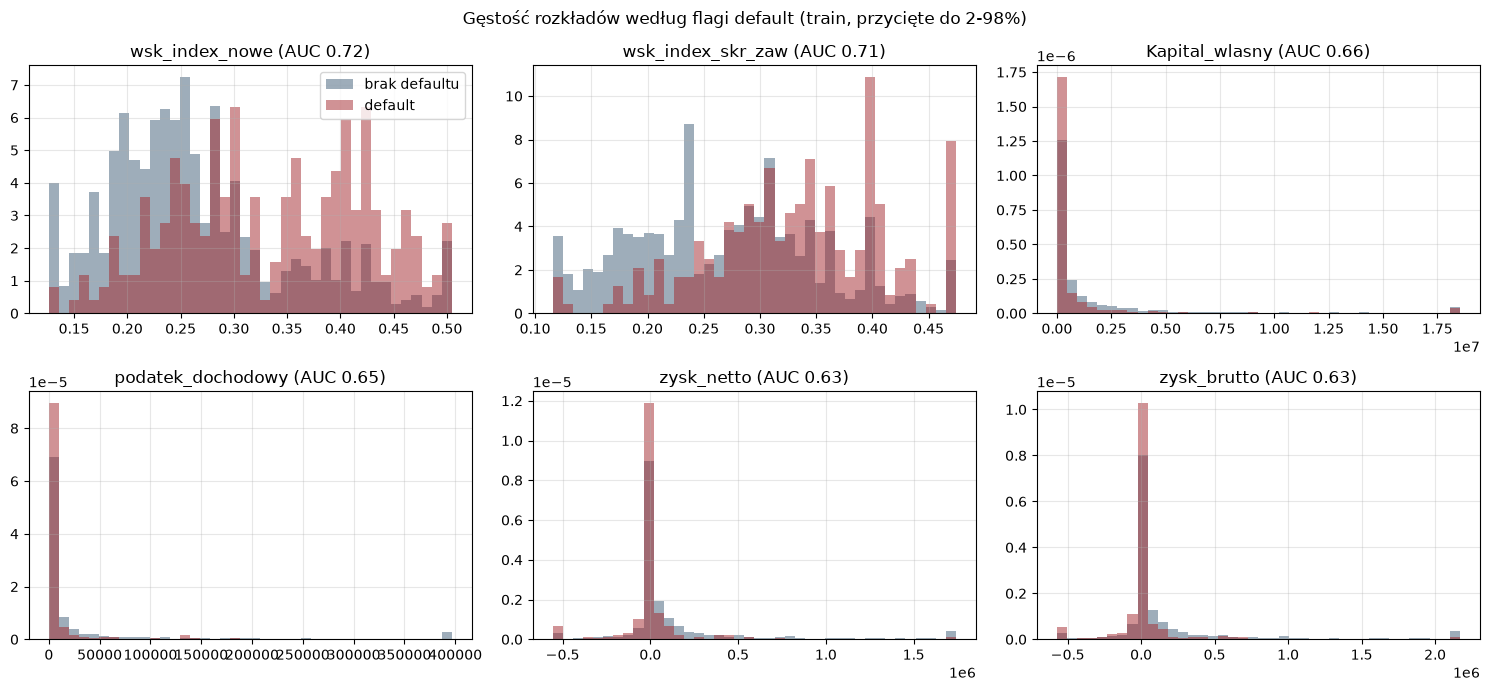

In [25]:
TOP_EDA = tab_auc.index[:6].tolist()
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.flat, TOP_EDA):
    lo, hi = df_train[c].quantile([0.02, 0.98])
    przedzialy = np.histogram_bin_edges(df_train[c].clip(lo, hi).dropna(), bins=40)
    for k, kol, lab in [(0, KOL["train"], "brak defaultu"), (1, KOL["test"], "default")]:
        ax.hist(df_train.loc[df_train[TARGET] == k, c].clip(lo, hi).dropna(), bins=przedzialy, density=True, alpha=0.5, color=kol, label=lab)
    ax.set_title(f"{c} (AUC {tab_auc.loc[c, 'AUC jednowymiarowe']:.2f})"); ax.grid(alpha=0.3)
axes[0, 0].legend(); plt.suptitle("Gęstość rozkładów według flagi default (train, przycięte do 2-98%)")
plt.tight_layout(); plt.savefig("wykresy/eda_rozklady.png", dpi=120); plt.show()

### 3.2 Zmienne kategoryczne a DR

Słupki pokazują udział defaultów (DR) w poszczególnych kategoriach na train. `n` to liczba obserwacji
w kategorii, a szara linia oznacza DR całego train. Pokazujemy do 10 najliczniejszych kategorii.
Osie pionowe wykresów mają różne skale. Wyniki małych grup należy interpretować ostrożnie.

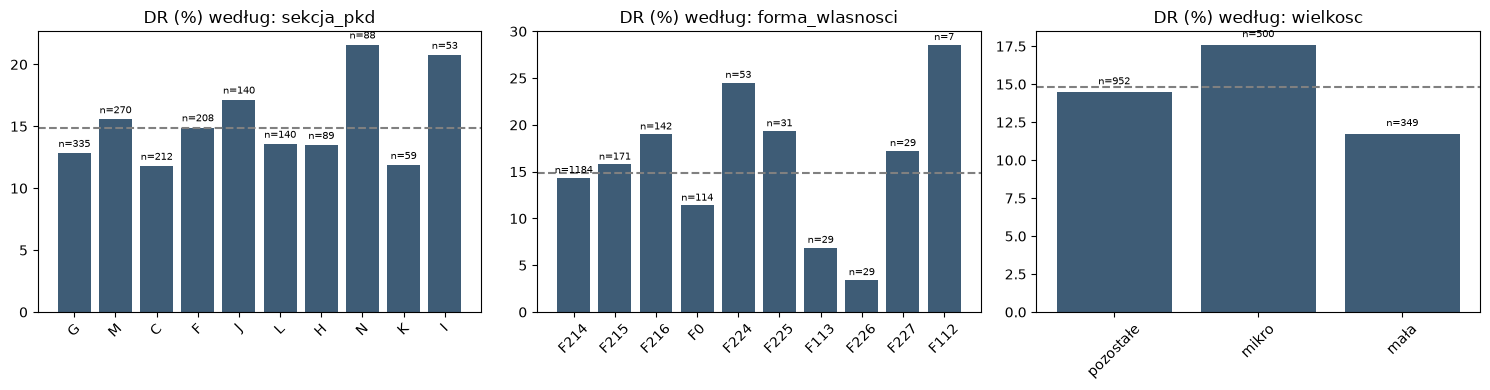

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, cat_cols):
    t = df_train.groupby(c)[TARGET].agg(n="size", DR="mean").sort_values("n", ascending=False).head(10)
    ax.bar(t.index.astype(str), 100 * t["DR"], color=KOL["logit"])
    for i, (n_, dr) in enumerate(zip(t["n"], t["DR"])):
        ax.text(i, 100 * dr + 0.5, f"n={n_}", ha="center", fontsize=7)
    ax.axhline(100 * y_tr.mean(), ls="--", color="gray"); ax.set_title(f"DR (%) według: {c}"); ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.savefig("wykresy/eda_kategorie.png", dpi=120); plt.show()

### 3.3 Korelacje

Wiele wskaźników to warianty tej samej miary (np. kilka definicji EBITDA czy zadłużenia), więc korelacje są
bardzo wysokie. To ważne dla: (a) selekcji cech do modelu interpretowalnego, (b) interpretacji SHAP i PDP
(rozdzielanie wpływu między skorelowane cechy), (c) analizy kontrfaktycznej.

Liczniki używają wartości bezwzględnej korelacji Spearmana i uwzględniają tylko pary z wyliczoną korelacją.
Wykres zachowuje znak korelacji i pokazuje 12 cech o najwyższym AUC z punktu 1.6.

Par cech z |ρ Spearmana| > 0,9: 219 | > 0,7: 937 (z 18,335 par z wyliczoną korelacją)


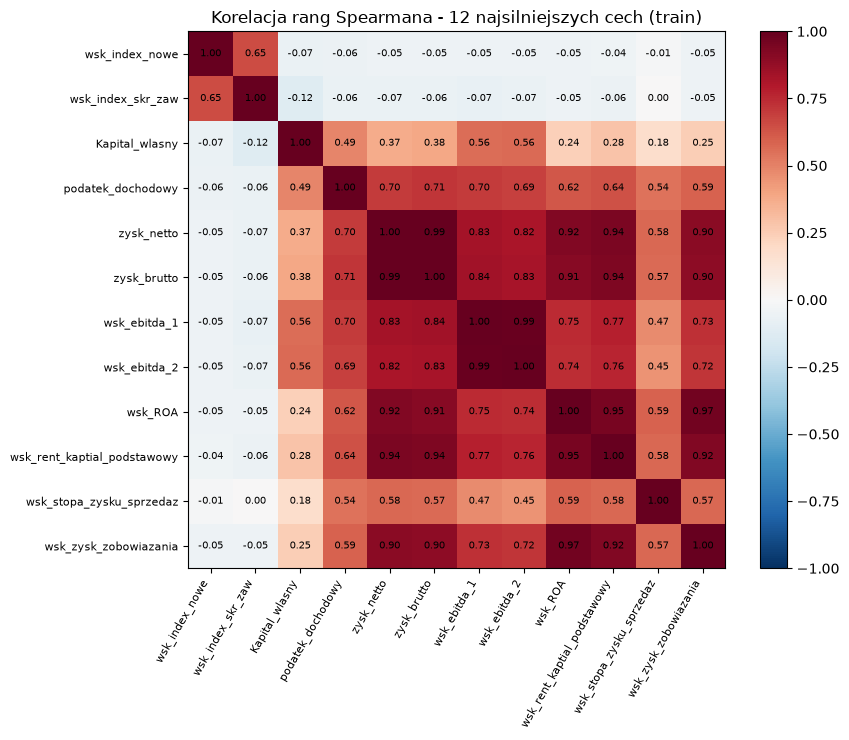

In [27]:
kor = df_train[num_cols].corr(method="spearman").abs()
gorne = kor.where(np.triu(np.ones(kor.shape, dtype=bool), k=1)).stack().dropna()
print(f"Par cech z |ρ Spearmana| > 0,9: {(gorne > 0.9).sum()} | > 0,7: {(gorne > 0.7).sum()} (z {len(gorne):,} par z wyliczoną korelacją)")
TOP_KOR = tab_auc.index[:12].tolist()
k12 = df_train[TOP_KOR].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(k12.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
for (a, b), val in np.ndenumerate(k12.to_numpy()):
    ax.text(b, a, f"{val:.2f}", ha="center", va="center", fontsize=7)
ax.set_xticks(range(len(TOP_KOR))); ax.set_xticklabels(TOP_KOR, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(TOP_KOR))); ax.set_yticklabels(TOP_KOR, fontsize=8)
ax.set_title("Korelacja rang Spearmana - 12 najsilniejszych cech (train)"); plt.colorbar(im, fraction=0.046)
plt.tight_layout(); plt.savefig("wykresy/eda_korelacje.png", dpi=120); plt.show()

## 4. Przygotowanie cech: binning monotoniczny i WoE (tylko train)

Klasa `WoEBinner` z Lab 1 przygotowuje cechy do karty scoringowej. Na train tworzy przedziały i oblicza ich WoE,
a następnie używa tych samych przedziałów do przekształcenia pozostałych zbiorów.

- **Cechy liczbowe:** przedziały kwantylowe są łączone tak, aby stopa defaultów zmieniała się monotonicznie.
  Powstaje najwyżej 5 przedziałów, z których każdy obejmuje co najmniej 5% dostępnych wartości.
- **Cechy kategoryczne:** rzadkie kategorie są łączone w `INNE`.
- **Braki liczbowe:** jeśli występują na train, tworzą osobny przedział `BRAK`, który może mieć mniej niż 5% obserwacji.

**WoE = ln(%dobrych / %złych)**; wyższe WoE oznacza niższe ryzyko względem całej próby. Wartości WoE są
wygładzane, dlatego ich monotoniczność nie jest gwarantowana mimo monotonicznej stopy defaultów.

In [28]:
from sklearn.base import BaseEstimator, TransformerMixin

class WoEBinner(BaseEstimator, TransformerMixin):
    # z Lab 1 (sekcja 7) - binning + WoE; dodany osobny przedział dla braków danych
    # Konwencja: WoE = ln(%dobrych / %złych), y = 1 oznacza złego klienta.
    def __init__(self, max_bins=5, init_bins=10, min_share=0.05, smoothing=0.5):
        self.max_bins, self.init_bins, self.min_share, self.smoothing = max_bins, init_bins, min_share, smoothing

    def _stats(self, codes, y, k):
        n = np.bincount(codes, minlength=k).astype(float)
        bad = np.bincount(codes, weights=y, minlength=k)
        return n, bad

    def _num_cuts(self, x, y):
        cuts = list(np.unique(np.quantile(x, np.linspace(0, 1, self.init_bins + 1)[1:-1])))
        rho = pd.Series(x).corr(pd.Series(y), method="spearman")
        direction = 1.0 if (not np.isfinite(rho) or rho == 0) else float(np.sign(rho))
        N = len(x)
        while cuts:
            codes = np.searchsorted(cuts, x, side="right"); k = len(cuts) + 1
            n, bad = self._stats(codes, y, k)
            br = bad / np.maximum(n, 1)
            small = np.where(n / N < self.min_share)[0]
            if len(small):
                i = small[0]
                j = i - 1 if i == k - 1 else (i if i == 0 else (i - 1 if abs(br[i] - br[i - 1]) < abs(br[i] - br[i + 1]) else i))
                cuts.pop(j); continue
            viol = np.where(np.diff(br) * direction < 0)[0]
            if len(viol):
                cuts.pop(viol[0]); continue
            if k > self.max_bins:
                cuts.pop(int(np.argmin(np.abs(np.diff(br))))); continue
            break
        return cuts

    def _table(self, codes, y, labels):
        k = len(labels); n, bad = self._stats(codes, y, k); good = n - bad; s = self.smoothing
        pg = (good + s) / (good.sum() + s * k); pb = (bad + s) / (bad.sum() + s * k)
        woe = np.log(pg / pb)
        return pd.DataFrame({"przedział": labels, "N": n.astype(int), "udział": n / n.sum(), "złe": bad.astype(int),
                             "stopa złych": bad / np.maximum(n, 1), "% dobrych": pg, "% złych": pb,
                             "WoE": woe, "IV": (pg - pb) * woe})

    def fit(self, X, y):
        X = pd.DataFrame(X); y = np.asarray(y).astype(float)
        self.cuts_, self.groups_, self.tables_, self.woe_, self.iv_, self.nan_ = {}, {}, {}, {}, {}, {}
        for c in X.columns:
            if pd.api.types.is_numeric_dtype(X[c]):
                x = X[c].to_numpy(dtype=float); ok = ~np.isnan(x)
                cuts = self._num_cuts(x[ok], y[ok]); self.cuts_[c] = cuts
                edges = [-np.inf] + cuts + [np.inf]
                labels = [f"[{edges[i]:.4g}; {edges[i+1]:.4g})" for i in range(len(edges) - 1)]
                self.nan_[c] = bool((~ok).any())                    # osobny przedział BRAK, gdy w train są braki
                if self.nan_[c]:
                    labels = labels + ["BRAK"]
                codes = np.where(ok, np.searchsorted(cuts, np.nan_to_num(x), side="right"), len(cuts) + 1)
            else:
                share = X[c].value_counts(normalize=True)
                groups = {v: (v if share[v] >= self.min_share else "INNE") for v in share.index}
                labels = sorted(set(groups.values()), key=lambda g: (g == "INNE", g))
                self.groups_[c] = (groups, labels)
                codes = X[c].map(groups).map({g: i for i, g in enumerate(labels)}).to_numpy()
            tab = self._table(codes, y, labels)
            self.tables_[c] = tab; self.woe_[c] = tab["WoE"].to_numpy(); self.iv_[c] = float(tab["IV"].sum())
        self.feature_names_in_ = np.array(X.columns)
        return self

    def codes(self, X):
        X = pd.DataFrame(X); out = {}
        for c in self.feature_names_in_:
            if c in self.cuts_:
                x = X[c].to_numpy(dtype=float); k = len(self.cuts_[c])
                kod = np.searchsorted(self.cuts_[c], np.nan_to_num(x), side="right")
                out[c] = np.where(np.isnan(x), k + 1 if self.nan_[c] else -1, kod)    # brak bez przedziału BRAK -> WoE 0
            else:
                groups, labels = self.groups_[c]; idx = {g: i for i, g in enumerate(labels)}
                out[c] = X[c].map(lambda v: idx[groups[v]] if v in groups else (idx["INNE"] if "INNE" in idx else -1)).to_numpy()
        return pd.DataFrame(out, index=X.index)

    def transform(self, X):
        cd = self.codes(X)
        return pd.DataFrame({c: np.where(cd[c] >= 0, self.woe_[c][np.clip(cd[c], 0, None)], 0.0)
                             for c in self.feature_names_in_}, index=cd.index)

    def get_feature_names_out(self, input_features=None):
        return self.feature_names_in_

### 4.1 Information Value - ranking cech (train)

Information Value (IV) ocenia, jak dobrze przedziały pojedynczej cechy rozróżniają defaulty na train.
Wyższe IV oznacza silniejsze rozróżnienie w tej próbie, ale nie gwarantuje podobnego wyniku na nowych danych.
Progi siły są orientacyjne: IV ≥ 0,5 jest sygnałem do sprawdzenia przecieku, a nie jego dowodem.

In [29]:
def sila_iv(v):                                              # z Lab 1
    return ("bezużyteczna" if v < 0.02 else "słaba" if v < 0.1 else "średnia" if v < 0.3
            else "silna" if v < 0.5 else "podejrzanie silna – sprawdź przeciek")

binner_all = WoEBinner(max_bins=5, min_share=0.05).fit(X_tr, y_tr)
iv_tab = pd.DataFrame({"cecha": list(binner_all.iv_), "IV": list(binner_all.iv_.values())}).sort_values("IV", ascending=False)
iv_tab["siła"] = iv_tab["IV"].map(sila_iv)
obszar_cech = {**obszar, **{c: "wskaźnik branżowy" for c in WSK_INDEX}, **{c: "kategoria" for c in cat_cols}}
iv_tab["obszar"] = iv_tab["cecha"].map(lambda c: obszar_cech.get(c, "brak w słowniku"))
print("Liczba cech według siły IV:")
print(iv_tab["siła"].value_counts().to_string())
print("\n20 cech o najwyższym IV na train:")
display(iv_tab.head(20).set_index("cecha").round(3))

Liczba cech według siły IV:
siła
średnia                                 80
słaba                                   74
bezużyteczna                            36
silna                                    3
podejrzanie silna – sprawdź przeciek     2

20 cech o najwyższym IV na train:


,IV,siła,obszar
cecha,,,
wsk_index_nowe,0.610,podejrzanie silna – sprawdź przeciek,wskaźnik branżowy
wsk_index_skr_zaw,0.576,podejrzanie silna – sprawdź przeciek,wskaźnik branżowy
podatek_dochodowy,0.366,silna,pozycja RZiS
Kapital_wlasny,0.322,silna,pozycja bilansu
zysk_netto,0.304,silna,pozycja RZiS
zysk_brutto,0.293,średnia,pozycja RZiS
wsk_ogolnego_zadluzenia_1,0.291,średnia,wskaźnik finansowy
wsk_ogolnego_zadluzenia_2,0.284,średnia,wskaźnik finansowy
wsk_kapital_do_aktywa,0.283,średnia,wskaźnik finansowy


### 4.2 Selekcja cech do karty scoringowej

Baseline nie może być „za bogaty” (Lab 3). Procedura na train:
1. kandydaci: IV ≥ 0,1 (co najmniej średnia siła),
2. zachłannie według IV: cechę dodajemy, jeśli |ρ Spearmana| jej WoE z każdą już wybraną < 0,6 (unikamy wariantów tej samej miary),
3. liczbę cech k wybieramy 5-krotną CV na train (AUC). Najwyższe średnie AUC uzyskujemy dla 8 cech (0,7728),
   niewiele wyższe niż dla 4 cech (0,7722). Reguła „1 błędu standardowego” wskazuje 3 cechy. Wybieramy 8,
   aby uwzględnić więcej obszarów oceny, m.in. zadłużenie i rentowność sprzedaży;
4. kontrola znaków β i VIF (5.1).

IV i filtr korelacji obliczamy przed CV na całym train. W każdym foldzie ponownie dopasowujemy binning i WoE,
ale korzystamy z wcześniej wybranej kolejności cech.

In [30]:
W_tr_all = binner_all.transform(X_tr)
kand = iv_tab.loc[iv_tab["IV"] >= 0.1, "cecha"].tolist()
wybrane_kol = []
for c in kand:
    if all(abs(spearmanr(W_tr_all[c], W_tr_all[w])[0]) < 0.6 for w in wybrane_kol):
        wybrane_kol.append(c)
print(f"Kandydaci IV ≥ 0,1: {len(kand)} | po filtrze korelacji: {len(wybrane_kol)}")
print("Cechy po filtrze korelacji, w kolejności IV:")
print(wybrane_kol)

Kandydaci IV ≥ 0,1: 85 | po filtrze korelacji: 12
Cechy po filtrze korelacji, w kolejności IV:
['wsk_index_nowe', 'podatek_dochodowy', 'Kapital_wlasny', 'wsk_ogolnego_zadluzenia_1', 'wsk_zysk_zobowiazania', 'wsk_stopa_zysku_sprzedaz', 'wsk_sytuacji_fin', 'pozostale_przychody_oper', 'wsk_rotacja_wartosci_niewaterialnych', 'wsk_ebitda_zobowiazan_odsetki_3', 'wsk_plynnosc_biez_1', 'wsk_struktury_finansowania']


Wyniki 5-krotnej CV według liczby cech:


k,2,3,4,5,6,7,8,9,10,11,12
AUC CV,0.7429,0.7548,0.7722,0.7713,0.7726,0.7720,0.7728,0.7698,0.7667,0.7666,0.7656
odch. std.,0.0486,0.0540,0.0506,0.0457,0.0462,0.0489,0.0471,0.0450,0.0459,0.0454,0.0453
błąd std.,0.0217,0.0242,0.0226,0.0204,0.0207,0.0219,0.0211,0.0201,0.0205,0.0203,0.0203


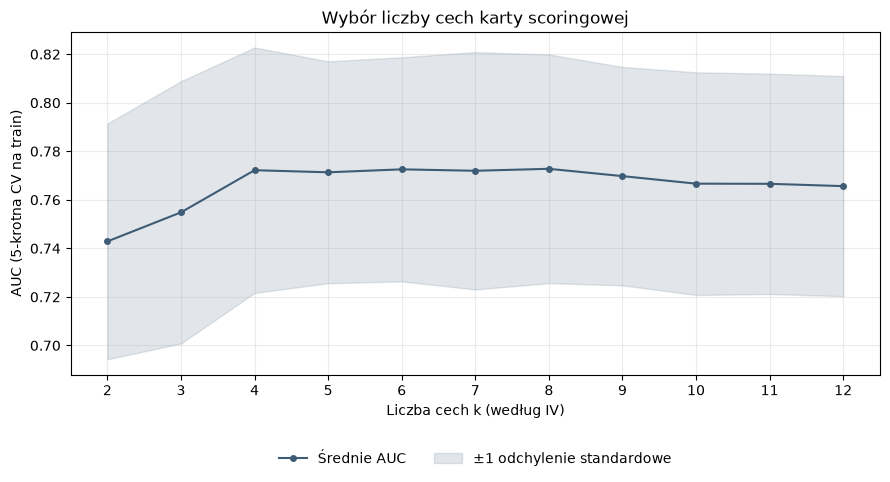

Najlepsze AUC dla k = 8; reguła 1 błędu std. dałaby k = 3; wybieramy k = 8


In [34]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

def lr_bez_kary(**kw):                                       # z Lab 1
    wersja = tuple(int(v) for v in sklearn.__version__.split(".")[:2])
    return LogisticRegression(C=np.inf, **kw) if wersja >= (1, 8) else LogisticRegression(penalty=None, **kw)

def karta(cechy):
    return Pipeline([("woe", WoEBinner(max_bins=5, min_share=0.05)), ("lr", lr_bez_kary(max_iter=5000))])

wiersze = []
for k in range(2, len(wybrane_kol) + 1):
    auc_f = []
    for a, b in FOLDY:                                         # binning dopasowany w każdym foldzie od nowa
        m = karta(wybrane_kol[:k]).fit(X_tr.iloc[a][wybrane_kol[:k]], y_tr[a])
        auc_f.append(roc_auc_score(y_tr[b], m.predict_proba(X_tr.iloc[b][wybrane_kol[:k]])[:, 1]))
    wiersze.append({"k": k, "AUC CV": np.mean(auc_f), "odch. std.": np.std(auc_f), "błąd std.": np.std(auc_f) / np.sqrt(5)})
wybor_k = pd.DataFrame(wiersze).set_index("k")
najl = wybor_k["AUC CV"].idxmax()
K_1SE = int(wybor_k.index[wybor_k["AUC CV"] >= wybor_k.loc[najl, "AUC CV"] - wybor_k.loc[najl, "błąd std."]].min())
K_CECH = int(najl)
print("Wyniki 5-krotnej CV według liczby cech:")
display(wybor_k.round(4).T)
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(wybor_k.index, wybor_k["AUC CV"], marker="o", markersize=4, color=KOL["logit"], label="Średnie AUC")
ax.fill_between(wybor_k.index, wybor_k["AUC CV"] - wybor_k["odch. std."],
                wybor_k["AUC CV"] + wybor_k["odch. std."], color=KOL["logit"], alpha=0.15,
                label="±1 odchylenie standardowe")
ax.set_xticks(wybor_k.index)
ax.set_xlabel("Liczba cech k (według IV)"); ax.set_ylabel("AUC (5-krotna CV na train)")
ax.set_title("Wybór liczby cech karty scoringowej"); ax.grid(alpha=0.25)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=False)
plt.tight_layout(); plt.show()
print(f"Najlepsze AUC dla k = {najl}; reguła 1 błędu std. dałaby k = {K_1SE}; wybieramy k = {K_CECH}")

## 5. Model interpretowalny: karta scoringowa (WoE + regresja logistyczna)

### 5.1 Estymacja i kontrola znaków

Uczymy regresję logistyczną na wybranych cechach po przekształceniu WoE.
W konwencji WoE = ln(%dobrych/%złych) oczekujemy **β < 0**: wyższe WoE powinno obniżać ryzyko defaultu.
Nie jest to jednak gwarancja w modelu wielowymiarowym. W tej procedurze usuwamy cechy z β ≥ 0 i uczymy model ponownie.

W tabeli **β** to współczynnik modelu, **VIF** pomaga ocenić współliniowość, a **p-value** opisuje istotność
współczynnika w osobno dopasowanej regresji bez kary. P-value interpretujemy ostrożnie, ponieważ cechy wybrano na tych samych danych.

In [35]:
CECHY_L = wybrane_kol[:K_CECH]
while True:
    baseline = karta(CECHY_L).fit(X_tr[CECHY_L], y_tr)
    beta_l = pd.Series(baseline.named_steps["lr"].coef_.ravel(), index=CECHY_L)
    if (beta_l < 0).all():
        break
    print(f"Usuwam {beta_l.idxmax()} (β = {beta_l.max():+.3f} ≥ 0)")
    CECHY_L = [c for c in CECHY_L if c != beta_l.idxmax()]

woe_l = baseline.named_steps["woe"]; lr_l = baseline.named_steps["lr"]
W_tr = woe_l.transform(X_tr[CECHY_L])
vif = pd.Series(np.diag(np.linalg.inv(np.corrcoef(W_tr.to_numpy(), rowvar=False))), index=CECHY_L)       # z Lab 3 (Zadanie 2)
tab_beta = pd.DataFrame({"obszar": [obszar_cech.get(c, "brak w słowniku") for c in CECHY_L], "IV": [woe_l.iv_[c] for c in CECHY_L],
                         "β": beta_l, "kontrola znaku": np.where(beta_l < 0, "OK (β < 0)", "UWAGA: β ≥ 0"), "VIF": vif,
                         "liczba przedziałów": [len(woe_l.tables_[c]) for c in CECHY_L]})
import statsmodels.api as sm
sm_l = sm.Logit(y_tr, sm.add_constant(W_tr)).fit(disp=0)                 # wykład 2: istotność β (te same WoE, bez kary)
tab_beta["p-value"] = sm_l.pvalues[CECHY_L]
print("Współczynniki i diagnostyka cech karty scoringowej:")
display(tab_beta.round(3))
print(f"Wyraz wolny: {lr_l.intercept_[0]:.3f} | liczba parametrów: {len(CECHY_L) + 1} | maks. VIF = {vif.max():.2f}")
with open("wyniki/cechy_karty.json", "w", encoding="utf-8") as plik:
    json.dump({"karta_scoringowa": CECHY_L}, plik, ensure_ascii=False, indent=1)

Współczynniki i diagnostyka cech karty scoringowej:


,obszar,IV,β,kontrola znaku,VIF,liczba przedziałów,p-value
wsk_index_nowe,wskaźnik branżowy,0.610,-0.938,OK (β < 0),1.031,5,0.000
podatek_dochodowy,pozycja RZiS,0.366,-0.512,OK (β < 0),2.189,5,0.004
Kapital_wlasny,pozycja bilansu,0.322,-0.434,OK (β < 0),1.789,5,0.009
wsk_ogolnego_zadluzenia_1,wskaźnik finansowy,0.291,-0.725,OK (β < 0),1.217,3,0.000
wsk_zysk_zobowiazania,wskaźnik finansowy,0.246,-0.147,OK (β < 0),1.760,5,0.449
wsk_stopa_zysku_sprzedaz,wskaźnik finansowy,0.220,-0.403,OK (β < 0),1.705,5,0.040
wsk_sytuacji_fin,wskaźnik finansowy,0.176,-0.185,OK (β < 0),1.265,5,0.324
pozostale_przychody_oper,pozycja RZiS,0.174,-0.248,OK (β < 0),1.484,4,0.237


Wyraz wolny: -1.751 | liczba parametrów: 9 | maks. VIF = 2.19


### 5.2 Ocena jakości: AUC, Gini, KS, PR-AUC, log-loss, Brier

Oceniamy kartę na train, valid i test, przed dostosowaniem PD do poziomu 4%. Decyzje podejmujemy na train / valid,
test tylko raportujemy. Funkcje pochodzą z Lab 3 i Lab 2.

- **n, DR, średnie PD** - liczba obserwacji, udział defaultów i średnie przewidywane prawdopodobieństwo defaultu.
- **AUC, Gini, KS, PR-AUC** - zdolność rozróżniania firm z defaultem i bez niego; wyższe wartości są lepsze.
  PR-AUC liczymy jako *average precision* (AP).
- **log-loss, Brier** - błędy przewidywanych prawdopodobieństw; niższe wartości są lepsze.
- **ECE, ACE** - różnice między średnim PD a DR w przedziałach: odpowiednio równej szerokości i wyznaczonych
  kwantylami. Niższe wartości są lepsze; powtarzające się PD mogą dać mniej przedziałów lub różne ich liczebności.
- **CITL a, slope b** - miary kalibracji: wartości idealne to odpowiednio 0 i 1.

In [36]:
from scipy.optimize import brentq

def ks(y, p):                                                 # z Lab 3
    fpr, tpr, _ = roc_curve(y, p)
    return float(np.max(tpr - fpr))

def ece(y, p, n_bins=10):                                     # z Lab 3 - przedziały równej szerokości
    edges = np.linspace(0, 1, n_bins + 1); idx = np.clip(np.digitize(p, edges[1:-1]), 0, n_bins - 1)
    return float(sum(np.mean(idx == m) * abs(y[idx == m].mean() - p[idx == m].mean()) for m in range(n_bins) if np.any(idx == m)))

def ace(y, p, n_bins=10):                                     # z Lab 3 - przedziały równoliczne
    edges = np.unique(np.quantile(p, np.linspace(0, 1, n_bins + 1)))
    if len(edges) == 1:
        return float(abs(y.mean() - p.mean()))
    idx = np.clip(np.digitize(p, edges[1:-1], right=True), 0, len(edges) - 2)
    return float(sum(np.mean(idx == m) * abs(y[idx == m].mean() - p[idx == m].mean()) for m in range(len(edges) - 1) if np.any(idx == m)))

def _z(p):
    return logit(np.clip(p, EPS, 1 - EPS))

def cox(y, p):                                                # z Lab 2 - calibration intercept (CITL, przy nachyleniu 1) i slope
    z = _z(p)
    a = brentq(lambda d: expit(z + d).mean() - y.mean(), -15, 15)
    b = LogisticRegression(C=1e6, max_iter=1000).fit(z.reshape(-1, 1), y).coef_[0, 0]
    return a, b

def metryki(y, p):                                            # z Lab 3, rozszerzone o CITL i slope z Lab 2
    y, p = np.asarray(y), np.asarray(p); auc = roc_auc_score(y, p); a, b = cox(y, p)
    return {"n": len(y), "DR": y.mean(), "średnie PD": p.mean(), "AUC": auc, "Gini": 2 * auc - 1, "KS": ks(y, p),
            "PR-AUC": average_precision_score(y, p), "log-loss": log_loss(y, np.clip(p, EPS, 1 - EPS)),
            "Brier": brier_score_loss(y, p), "ECE": ece(y, p), "ACE": ace(y, p), "CITL a": a, "slope b": b}

P = {"logit": {s: baseline.predict_proba(X[s][CECHY_L])[:, 1] for s in X}}
print("Jakość karty scoringowej przed kalibracją do 4%:")
display(pd.DataFrame({s: metryki(Y[s], P["logit"][s]) for s in X}).T.round(4))

Jakość karty scoringowej przed kalibracją do 4%:


,n,DR,średnie PD,AUC,Gini,KS,PR-AUC,log-loss,Brier,ECE,ACE,CITL a,slope b
train,1801.0,0.1483,0.1482,0.7991,0.5982,0.4614,0.4165,0.3430,0.1056,0.0198,0.0148,0.0004,0.9998
valid,600.0,0.1483,0.1346,0.7972,0.5944,0.4819,0.4577,0.3402,0.1031,0.0291,0.0341,0.1349,1.0578
test,599.0,0.1486,0.1468,0.7810,0.5620,0.4397,0.4300,0.3499,0.1050,0.0153,0.0299,0.0167,0.9456


**Wnioski:** karta z 8 cechami ma Gini 0,598 na train, 0,594 na valid i 0,562 na teście. Wyniki na valid i teście są
zbliżone do wyniku na train. Średnie PD jest bliskie DR na train i teście (CITL a ≈ 0,00-0,02), a na valid jest nieco
niższe (13,5% przy DR 14,8%, CITL a = 0,13). Nachylenie kalibracji wynosi 0,95-1,06. Dokładniej ocenimy kalibrację w punkcie 11.

### 5.3 Stopa defaultu w przedziałach cech karty

Porównujemy stopę defaultu (DR) na train i valid w przedziałach wyznaczonych na train dla każdej cechy karty.
Tytuły wykresów podają IV z train i współczynnik β modelu; wartości WoE nie są tu rysowane.

Tabela pokazuje, ile zmian DR między sąsiednimi przedziałami ma ten sam kierunek na valid co na train.
Przykładowo 4 / 4 oznacza zgodność we wszystkich czterech przejściach. Pomijamy przedział BRAK oraz przejścia,
dla których DR na train się nie zmienia lub nie można wyliczyć DR na valid. To opisowe porównanie, nie test statystyczny.

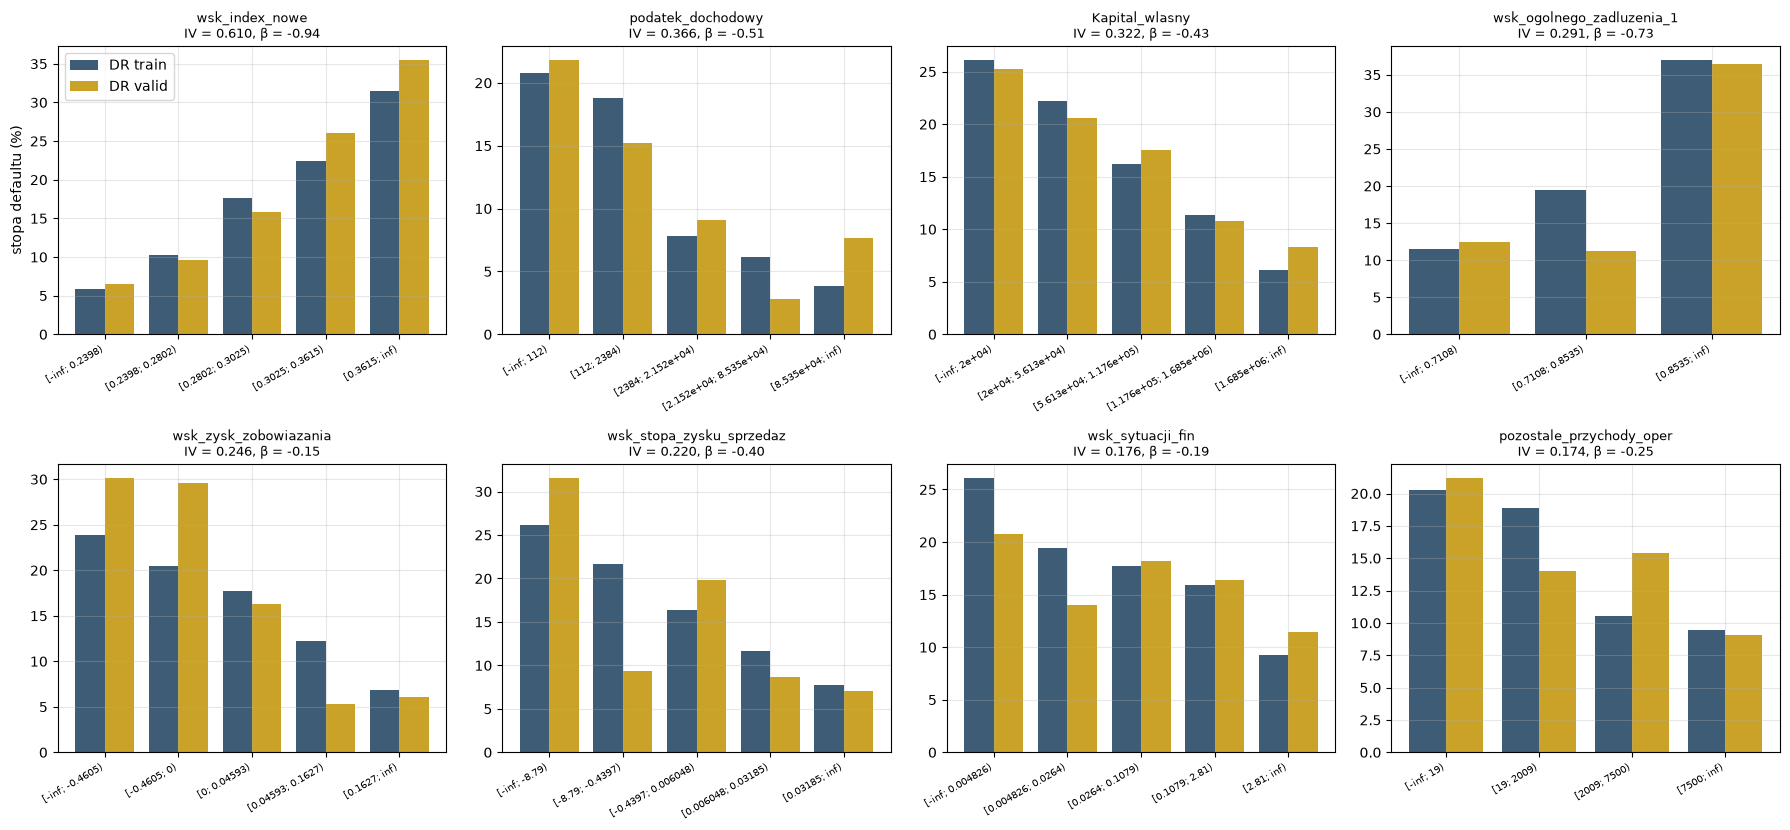

Zgodność kierunku zmian stopy defaultu na train i valid:


,przedziałów,kierunek na train,zgodnych zmian na valid
wsk_index_nowe,5,rosnący,4 / 4
podatek_dochodowy,5,malejący,3 / 4
Kapital_wlasny,5,malejący,4 / 4
wsk_ogolnego_zadluzenia_1,3,rosnący,1 / 2
wsk_zysk_zobowiazania,5,malejący,3 / 4
wsk_stopa_zysku_sprzedaz,5,malejący,3 / 4
wsk_sytuacji_fin,5,malejący,3 / 4
pozostale_przychody_oper,4,malejący,2 / 3


In [37]:
kody_va = woe_l.codes(X_va[CECHY_L])
n_kol = 4; n_wier = int(np.ceil(len(CECHY_L) / n_kol))
fig, axes = plt.subplots(n_wier, n_kol, figsize=(18, 4.2 * n_wier)); axes = np.atleast_2d(axes)
monot = {}
for ax, c in zip(axes.flat, CECHY_L):
    tab = woe_l.tables_[c].copy()
    tab["stopa złych (valid)"] = [y_va[kody_va[c].to_numpy() == i].mean() if np.any(kody_va[c].to_numpy() == i) else np.nan for i in range(len(tab))]
    x_ = np.arange(len(tab))
    ax.bar(x_ - 0.2, 100 * tab["stopa złych"], 0.4, color=KOL["train"], label="DR train")
    ax.bar(x_ + 0.2, 100 * tab["stopa złych (valid)"], 0.4, color=KOL["valid"], label="DR valid")
    ax.set_xticks(x_); ax.set_xticklabels(tab["przedział"], rotation=30, ha="right", fontsize=7)
    ax.set_title(f"{c}\nIV = {woe_l.iv_[c]:.3f}, β = {beta_l[c]:+.2f}", fontsize=9); ax.grid(alpha=0.3)
    br = tab.loc[tab["przedział"] != "BRAK"]
    kier_tr, kier_va = np.sign(np.diff(br["stopa złych"])), np.sign(np.diff(br["stopa złych (valid)"]))
    wzrost, spadek = np.any(kier_tr > 0), np.any(kier_tr < 0)
    kierunek = "niemonotoniczny" if wzrost and spadek else "rosnący" if wzrost else "malejący" if spadek else "brak kierunku"
    porownywalne = np.isfinite(kier_tr) & (kier_tr != 0) & np.isfinite(kier_va)
    n_porownan = int(porownywalne.sum())
    zgodne = int((kier_tr[porownywalne] == kier_va[porownywalne]).sum())
    monot[c] = {"przedziałów": len(br), "kierunek na train": kierunek,
                "zgodnych zmian na valid": f"{zgodne} / {n_porownan}" if n_porownan else "brak porównań"}
for ax in axes.flat[len(CECHY_L):]:
    ax.axis("off")
axes.flat[0].legend(); axes.flat[0].set_ylabel("stopa defaultu (%)")
plt.tight_layout(); plt.savefig("wykresy/karta_woe_profile.png", dpi=120); plt.show()
print("Zgodność kierunku zmian stopy defaultu na train i valid:")
display(pd.DataFrame(monot).T)

**Wnioski:** na train wyższym wartościom m.in. kapitału własnego, podatku dochodowego i rentowności sprzedaży
towarzyszy niższy DR, a wyższemu zadłużeniu i wskaźnikowi branżowemu `wsk_index_nowe` - wyższy DR. Są to obserwowane
zależności, nie dowód przyczynowości.

Na valid 23 z 29 zmian między sąsiednimi przedziałami ma ten sam kierunek co na train. Dla `wsk_index_nowe` i kapitału
własnego wszystkie cztery zmiany są zgodne (4 / 4). Wyniki w poszczególnych przedziałach mogą się wahać przy małej liczbie
defaultów: np. w dwóch ostatnich przedziałach podatku dochodowego na valid są odpowiednio 2 defaulty na 71 i 5 na 65 firm.

### 5.4 Karta punktowa (PDO) i dekompozycja wyniku

Skalowanie z Lab 1: 600 pkt przy szansach dobry:zły 50:1, PDO = 20 (co 20 pkt szanse się podwajają).
$\text{Punkty}_{ij} = \text{Factor}\cdot(-\beta_j\,\text{WoE}_{ij} - \beta_0/k) + \text{Offset}/k$. Suma punktów firmy
odpowiada logitowi modelu - to **bezpośrednia, dokładna dekompozycja wyniku na wkłady cech** (interpretacja lokalna 9.1).
Wyraz wolny $\beta_0$ i Offset rozdzielamy po równo między $k$ cech - jest to przyjęty sposób prezentacji wyniku.

Tabela pokazuje dla każdej cechy jej przedziały (atrybuty), wartości WoE i przypisane im punkty.

In [38]:
PDO, SCORE_REF, ODDS_REF = 20, 600, 50                        # z Lab 1 (sekcja 8)
factor = PDO / np.log(2)
offset = SCORE_REF - factor * np.log(ODDS_REF)
b0, betas, k_ = lr_l.intercept_[0], dict(zip(CECHY_L, lr_l.coef_.ravel())), len(CECHY_L)
wiersze = []
for c in CECHY_L:
    tab = woe_l.tables_[c]
    for lab, w in zip(tab["przedział"], tab["WoE"]):
        wiersze.append({"cecha": c, "atrybut": lab, "WoE": w, "punkty": factor * (-betas[c] * w - b0 / k_) + offset / k_})
karta_pkt = pd.DataFrame(wiersze)
karta_pkt["punkty (zaokr.)"] = karta_pkt["punkty"].round().astype(int)
print(f"Factor = {factor:.3f}, Offset = {offset:.2f}")
print("Karta punktowa: przedziały cech, WoE i punkty:")
display(karta_pkt[["cecha", "atrybut", "WoE", "punkty (zaokr.)"]].round(3))

def punkty_firmy(Xw):
    # punkty każdej cechy dla firm z Xw (wiersze) - dekompozycja wyniku karty
    W = woe_l.transform(Xw[CECHY_L])
    return pd.DataFrame({c: factor * (-betas[c] * W[c] - b0 / k_) + offset / k_ for c in CECHY_L}, index=Xw.index)

wynik_model = offset + factor * (-baseline.decision_function(X_te[CECHY_L]))
print("Suma punktów zgodna z modelem:", np.allclose(punkty_firmy(X_te).sum(axis=1), wynik_model),
      f"| wynik na teście: min {wynik_model.min():.0f}, mediana {np.median(wynik_model):.0f}, max {wynik_model.max():.0f}")

Factor = 28.854, Offset = 487.12
Karta punktowa: przedziały cech, WoE i punkty:


,cecha,atrybut,WoE,punkty (zaokr.)
0,wsk_index_nowe,[-inf; 0.2398),1.025,95
1,wsk_index_nowe,[0.2398; 0.2802),0.418,79
2,wsk_index_nowe,[0.2802; 0.3025),-0.207,62
3,wsk_index_nowe,[0.3025; 0.3615),-0.511,53
4,wsk_index_nowe,[0.3615; inf),-0.967,41
5,podatek_dochodowy,[-inf; 112),-0.404,61
6,podatek_dochodowy,[112; 2384),-0.288,63
7,podatek_dochodowy,[2384; 2.152e+04),0.713,78
8,podatek_dochodowy,[2.152e+04; 8.535e+04),0.950,81
9,podatek_dochodowy,[8.535e+04; inf),1.406,88


Suma punktów zgodna z modelem: True | wynik na teście: min 463, mediana 554, max 623


### 5.5 Stabilność modelu interpretowalnego w 5-krotnej CV (train)

W każdym foldzie dopasowujemy binning, WoE i regresję na części treningowej, a metryki liczymy na części walidacyjnej.
Porównujemy też współczynniki β między foldami.

Lista i liczba cech zostały wybrane wcześniej na całym train (4.2 i 5.1); nie wybieramy ich ponownie w foldach.
Te same foldy służyły do wyboru liczby cech w 4.2.

In [39]:
def metryki_cv(budowa, cechy):
    wiersze, bety = [], []
    for k, (a, b) in enumerate(FOLDY, start=1):
        m = budowa().fit(X_tr.iloc[a][cechy], y_tr[a])
        p = m.predict_proba(X_tr.iloc[b][cechy])[:, 1]
        w = metryki(y_tr[b], p); w["fold"] = k; wiersze.append(w)
        if "lr" in m.named_steps:
            bety.append(pd.Series(m.named_steps["lr"].coef_.ravel(), index=cechy))
    return pd.DataFrame(wiersze).set_index("fold"), (pd.DataFrame(bety) if bety else None)

cv_logit, bety_cv = metryki_cv(lambda: karta(CECHY_L), CECHY_L)
KOL_CV = ["AUC", "Gini", "KS", "PR-AUC", "log-loss", "Brier"]
print("Metryki na części walidacyjnej każdego foldu:")
display(cv_logit[KOL_CV].round(4))
print("Średnia ± odchylenie standardowe między foldami:")
for c in ["Gini", "KS", "log-loss"]:
    print(f"{c}: {cv_logit[c].mean():.3f} ± {cv_logit[c].std():.3f}")
print("Współczynniki β na całym train i w foldach:")
display(pd.DataFrame({"β (cały train)": beta_l, "β CV średnia": bety_cv.mean(), "β CV odch. std.": bety_cv.std(),
                      "znak ujemny w foldach": (bety_cv < 0).sum().astype(str) + " / 5"}).round(3))

Metryki na części walidacyjnej każdego foldu:


,AUC,Gini,KS,PR-AUC,log-loss,Brier
fold,,,,,,
1,0.7166,0.4333,0.3712,0.3225,0.3832,0.1170
2,0.8298,0.6595,0.5670,0.5138,0.3233,0.0971
3,0.8034,0.6068,0.4970,0.4245,0.3439,0.1068
4,0.7166,0.4333,0.3358,0.3374,0.3981,0.1210
5,0.7975,0.5950,0.4642,0.4180,0.3442,0.1068


Średnia ± odchylenie standardowe między foldami:
Gini: 0.546 ± 0.105
KS: 0.447 ± 0.094
log-loss: 0.359 ± 0.031
Współczynniki β na całym train i w foldach:


,β (cały train),β CV średnia,β CV odch. std.,znak ujemny w foldach
wsk_index_nowe,-0.938,-0.938,0.024,5 / 5
podatek_dochodowy,-0.512,-0.493,0.086,5 / 5
Kapital_wlasny,-0.434,-0.470,0.051,5 / 5
wsk_ogolnego_zadluzenia_1,-0.725,-0.732,0.055,5 / 5
wsk_zysk_zobowiazania,-0.147,-0.152,0.150,4 / 5
wsk_stopa_zysku_sprzedaz,-0.403,-0.433,0.117,5 / 5
wsk_sytuacji_fin,-0.185,-0.155,0.078,5 / 5
pozostale_przychody_oper,-0.248,-0.240,0.118,5 / 5


**Wnioski:** Gini w foldach waha się od 0,43 do 0,66 (średnia 0,546 ± 0,105). Każda część walidacyjna zawiera
53-54 defaulty, co może wpływać na wahania wyników. Przedziały bootstrap przedstawiamy w 6.2.

Ujemnych jest 39 z 40 współczynników β. Wyjątkiem jest `wsk_zysk_zobowiazania`, dla którego znak jest ujemny
w 4 z 5 foldów (średnia β = -0,15 ± 0,15). Najmniejszy rozrzut β ma `wsk_index_nowe` (odch. std. 0,02).
Ocenę p-value przedstawiono w 5.1.

## 6. Model black-box: XGBoost

### 6.1 Przygotowanie cech i strojenie z kontrolą przeuczenia

- 192 cechy liczbowe bez dalszych przekształceń - drzewa obsługują braki i są odporne na skrajne wartości;
- cechy kategoryczne kodujemy one-hot; poziomy występujące w mniej niż 20 obserwacjach łączymy w „infrequent”.
  W CV kategorie są wyznaczane osobno na części treningowej każdego foldu;
- sprawdzamy **40 losowych konfiguracji w 5-krotnej CV na train** i wybieramy najniższy log-loss;
- ograniczamy przeuczenie m.in. przez głębokość drzew, losowanie obserwacji i cech oraz regularyzację;
  porównujemy metryki na częściach treningowych i walidacyjnych foldów;
- nie stosujemy wag klas ani oversamplingu, więc nie jest potrzebna korekta wynikająca z ich użycia.
  Kalibrację PD sprawdzimy osobno w punkcie 11.

In [43]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBClassifier

def preprocessing_drzewa(num=None):
    return ColumnTransformer([("num", "passthrough", num_cols if num is None else num),
                              ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False), cat_cols)])

def model_black_box(num=None, **parametry):
    ustawienia = dict(n_estimators=300, learning_rate=0.05, max_depth=3, min_child_weight=5, subsample=0.8,
                      colsample_bytree=0.5, reg_lambda=5.0, gamma=0.0, tree_method="hist", eval_metric="logloss",
                      n_jobs=-1, random_state=RNG_SEED)
    ustawienia.update(parametry)
    return Pipeline([("pre", preprocessing_drzewa(num)), ("clf", XGBClassifier(**ustawienia))])

siatka_xgb = {"clf__n_estimators": [100, 200, 300, 500, 800], "clf__learning_rate": [0.01, 0.02, 0.05, 0.1],
              "clf__max_depth": [2, 3, 4, 5], "clf__min_child_weight": [1, 5, 10, 20],
              "clf__subsample": [0.6, 0.8, 1.0], "clf__colsample_bytree": [0.2, 0.35, 0.5, 0.8],
              "clf__reg_lambda": [1.0, 5.0, 10.0, 30.0], "clf__gamma": [0.0, 0.5, 2.0]}
szukaj = RandomizedSearchCV(model_black_box(), siatka_xgb, n_iter=40, scoring={"log-loss": "neg_log_loss", "AUC": "roc_auc"},
                            refit="log-loss", cv=FOLDY, random_state=RNG_SEED, return_train_score=True, n_jobs=1)
szukaj.fit(X_tr, y_tr)
wyn = pd.DataFrame(szukaj.cv_results_)
tab_tuning = pd.DataFrame({"log-loss CV": -wyn["mean_test_log-loss"], "log-loss train": -wyn["mean_train_log-loss"],
                           "AUC CV": wyn["mean_test_AUC"], "AUC CV odch. std.": wyn["std_test_AUC"], "AUC train": wyn["mean_train_AUC"]})
tab_tuning = pd.concat([wyn[[c for c in wyn if c.startswith("param_")]].rename(columns=lambda c: c.replace("param_clf__", "")), tab_tuning], axis=1)
tab_tuning["luka AUC (train - CV)"] = tab_tuning["AUC train"] - tab_tuning["AUC CV"]
print("Osiem konfiguracji z najniższym log-loss w CV:")
display(tab_tuning.sort_values("log-loss CV").head(8).round(4))
PARAM_BB = {k.replace("clf__", ""): v for k, v in szukaj.best_params_.items()}
print("Wybrane hiperparametry:", PARAM_BB)
json.dump(PARAM_BB, open("wyniki/xgboost_parametry.json", "w"), indent=1)

Osiem konfiguracji z najniższym log-loss w CV:


,subsample,reg_lambda,n_estimators,min_child_weight,max_depth,learning_rate,gamma,colsample_bytree,log-loss CV,log-loss train,AUC CV,AUC CV odch. std.,AUC train,luka AUC (train - CV)
33,0.6,5.0,800,5,5,0.01,2.0,0.50,0.3502,0.2111,0.7905,0.0369,0.9685,0.1780
8,1.0,1.0,100,10,5,0.05,2.0,0.35,0.3503,0.2283,0.7823,0.0379,0.9615,0.1792
20,0.8,1.0,200,10,5,0.02,0.5,0.50,0.3505,0.2491,0.7845,0.0407,0.9433,0.1588
9,0.8,10.0,300,20,5,0.02,2.0,0.80,0.3507,0.2903,0.7895,0.0391,0.8886,0.0991
31,0.6,5.0,500,20,5,0.02,0.0,0.20,0.3509,0.2917,0.7864,0.0393,0.8867,0.1003
26,1.0,30.0,100,20,2,0.10,0.5,0.35,0.3512,0.3007,0.7875,0.0356,0.8728,0.0854
14,0.6,30.0,300,1,4,0.05,0.0,0.20,0.3515,0.2225,0.7864,0.0367,0.9635,0.1771
30,0.8,1.0,200,1,3,0.02,0.0,0.80,0.3518,0.2469,0.7841,0.0393,0.9441,0.1600


Wybrane hiperparametry: {'subsample': 0.6, 'reg_lambda': 5.0, 'n_estimators': 800, 'min_child_weight': 5, 'max_depth': 5, 'learning_rate': 0.01, 'gamma': 2.0, 'colsample_bytree': 0.5}


**Wnioski:** wybrano 800 drzew o głębokości do 5, `learning_rate` 0,01, losowanie 60% obserwacji i 50% cech,
`min_child_weight` = 5, λ = 5 i γ = 2. Konfiguracja ma najniższy log-loss w CV (0,3502); wartości dla ośmiu
najlepszych konfiguracji są zbliżone (0,3502-0,3518).

AUC wybranej konfiguracji wynosi 0,969 na częściach treningowych i 0,791 na walidacyjnych. Różnica 0,178 wskazuje
na możliwość przeuczenia, mimo zastosowanych ograniczeń.

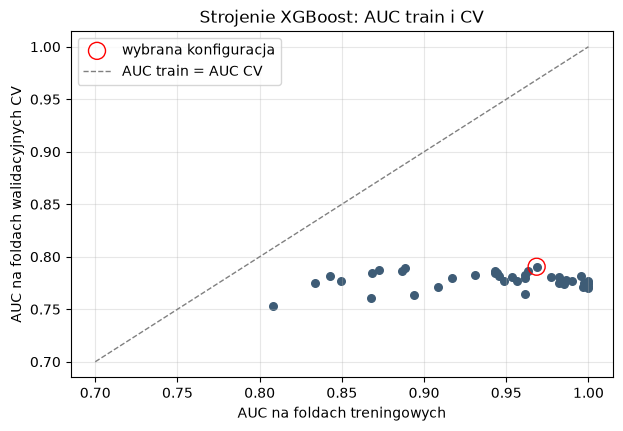

In [44]:
fig, ax = plt.subplots()
ax.scatter(tab_tuning["AUC train"], tab_tuning["AUC CV"], color="#3E5C76", s=30)
najl_i = szukaj.best_index_
ax.scatter(tab_tuning.loc[najl_i, "AUC train"], tab_tuning.loc[najl_i, "AUC CV"], s=150, facecolors="none", edgecolors="red", label="wybrana konfiguracja")
ax.plot([0.7, 1], [0.7, 1], "--", color="gray", lw=1, label="AUC train = AUC CV")
ax.set_xlabel("AUC na foldach treningowych"); ax.set_ylabel("AUC na foldach walidacyjnych CV")
ax.set_title("Strojenie XGBoost: AUC train i CV"); ax.legend(); ax.grid(alpha=0.3); plt.show()

Każdy punkt oznacza jedną konfigurację, a czerwone obramowanie wskazuje wybraną. Im dalej punkt leży poniżej linii,
tym większa różnica AUC między częściami treningowymi i walidacyjnymi foldów. Model końcowy jest dopasowany na całym train.

In [45]:
black_box = szukaj.best_estimator_
P["black-box"] = {s: black_box.predict_proba(X[s])[:, 1] for s in X}
print("Jakość modelu XGBoost przed kalibracją do 4%:")
display(pd.DataFrame({s: metryki(Y[s], P["black-box"][s]) for s in X}).T.round(4))

Jakość modelu XGBoost przed kalibracją do 4%:


,n,DR,średnie PD,AUC,Gini,KS,PR-AUC,log-loss,Brier,ECE,ACE,CITL a,slope b
train,1801.0,0.1483,0.1463,0.9679,0.9358,0.8130,0.8786,0.2109,0.0603,0.0766,0.0786,0.0202,2.6806
valid,600.0,0.1483,0.1282,0.8334,0.6667,0.5244,0.4803,0.3240,0.1000,0.0238,0.0336,0.2131,1.0440
test,599.0,0.1486,0.1414,0.7915,0.5830,0.4566,0.4576,0.3471,0.1041,0.0467,0.0402,0.0742,0.8321


### 6.2 Porównanie jakości na valid i teście

Porównujemy kartę i XGBoost przed kalibracją do 4%. Przedziały 95% wyznaczamy z 1000 próbek bootstrap,
losując obserwacje ze zwracaniem bez ponownego uczenia modeli. Przy porównaniu Gini losujemy te same obserwacje
dla obu modeli; przedział obejmujący zero oznacza, że różnica może wynikać z losowego doboru próby.

Na teście wykres ROC pokazuje TPR względem FPR, a wykres precision-recall - precision względem recall.
Linie przerywane oznaczają poziom odniesienia dla modelu losowego.

Porównanie metryk modeli na valid i teście:


,średnie PD,AUC,Gini,KS,PR-AUC,log-loss,Brier,ECE,ACE,CITL a,slope b
logit (valid),0.1346,0.7972,0.5944,0.4819,0.4577,0.3402,0.1031,0.0291,0.0341,0.1349,1.0578
black-box (valid),0.1282,0.8334,0.6667,0.5244,0.4803,0.3240,0.1000,0.0238,0.0336,0.2131,1.0440
logit (test),0.1468,0.7810,0.5620,0.4397,0.4300,0.3499,0.1050,0.0153,0.0299,0.0167,0.9456
black-box (test),0.1414,0.7915,0.5830,0.4566,0.4576,0.3471,0.1041,0.0467,0.0402,0.0742,0.8321


Przedziały bootstrap 95% dla metryk modeli na teście:


,AUC 95% CI,PR-AUC 95% CI,KS 95% CI,log-loss 95% CI
logit (test),[0.724; 0.833],[0.336; 0.552],[0.374; 0.559],[0.303; 0.401]
black-box (test),[0.737; 0.842],[0.364; 0.578],[0.382; 0.553],[0.295; 0.406]


Różnica Gini (black-box - logit) na teście: +0.0211, 95% przedział bootstrap (sparowany): [-0.0478; +0.0885]
Różnica Gini (black-box - logit) na valid:  +0.0723, 95% przedział bootstrap (sparowany): [+0.0190; +0.1200]


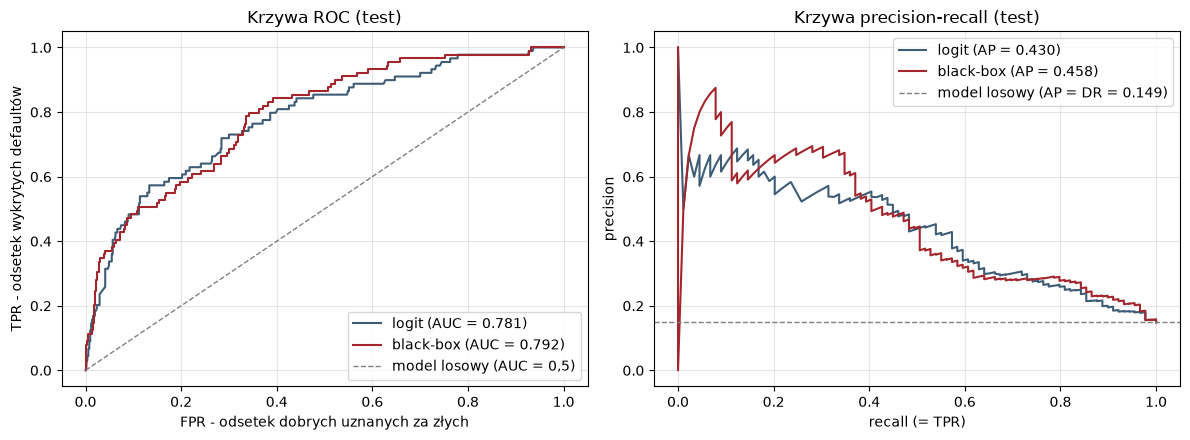

In [46]:
porownanie = pd.DataFrame({f"{m} ({s})": metryki(Y[s], P[m][s]) for s in ["valid", "test"] for m in ["logit", "black-box"]}).T
print("Porównanie metryk modeli na valid i teście:")
display(porownanie.drop(columns=["n", "DR"]).round(4))

def bootstrap_roznica_gini(y, p_a, p_b, B=1000, seed=RNG_SEED):     # z Lab 3
    rng = np.random.default_rng(seed); d = []
    for _ in range(B):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() == y[i].max():
            continue
        d.append(2 * (roc_auc_score(y[i], p_b[i]) - roc_auc_score(y[i], p_a[i])))
    roznica = 2 * (roc_auc_score(y, p_b) - roc_auc_score(y, p_a))
    return float(roznica), np.percentile(d, [2.5, 97.5])

def bootstrap_ci(y, p, B=1000, seed=RNG_SEED):                     # z Lab 3
    rng = np.random.default_rng(seed); w = {"AUC": [], "PR-AUC": [], "KS": [], "log-loss": []}
    for _ in range(B):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() == y[i].max():
            continue
        w["AUC"].append(roc_auc_score(y[i], p[i])); w["PR-AUC"].append(average_precision_score(y[i], p[i]))
        w["KS"].append(ks(y[i], p[i])); w["log-loss"].append(log_loss(y[i], np.clip(p[i], EPS, 1 - EPS)))
    return {f"{k} 95% CI": f"[{np.percentile(v, 2.5):.3f}; {np.percentile(v, 97.5):.3f}]" for k, v in w.items()}

print("Przedziały bootstrap 95% dla metryk modeli na teście:")
display(pd.DataFrame({f"{m} (test)": bootstrap_ci(y_te, P[m]["test"]) for m in ["logit", "black-box"]}).T)
roznica, (lo, hi) = bootstrap_roznica_gini(y_te, P["logit"]["test"], P["black-box"]["test"])
print(f"Różnica Gini (black-box - logit) na teście: {roznica:+.4f}, 95% przedział bootstrap (sparowany): [{lo:+.4f}; {hi:+.4f}]")
roznica_v, (lo_v, hi_v) = bootstrap_roznica_gini(y_va, P["logit"]["valid"], P["black-box"]["valid"])
print(f"Różnica Gini (black-box - logit) na valid:  {roznica_v:+.4f}, 95% przedział bootstrap (sparowany): [{lo_v:+.4f}; {hi_v:+.4f}]")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))                  # z Lab 3
for m in ["logit", "black-box"]:
    fpr, tpr, _ = roc_curve(y_te, P[m]["test"])
    axes[0].plot(fpr, tpr, color=KOL[m], label=f"{m} (AUC = {roc_auc_score(y_te, P[m]['test']):.3f})")
    prec, rec, _ = precision_recall_curve(y_te, P[m]["test"])
    axes[1].plot(rec, prec, color=KOL[m], label=f"{m} (AP = {average_precision_score(y_te, P[m]['test']):.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="gray", lw=1, label="model losowy (AUC = 0,5)")
axes[1].axhline(y_te.mean(), ls="--", color="gray", lw=1, label=f"model losowy (AP = DR = {y_te.mean():.3f})")
axes[0].set_xlabel("FPR - odsetek dobrych uznanych za złych"); axes[0].set_ylabel("TPR - odsetek wykrytych defaultów"); axes[0].set_title("Krzywa ROC (test)")
axes[1].set_xlabel("recall (= TPR)"); axes[1].set_ylabel("precision"); axes[1].set_title("Krzywa precision-recall (test)")
for ax in axes:
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("wykresy/roc_pr_test.png", dpi=120); plt.show()

**Wnioski:** black-box ma wyższy Gini: +0,072 na valid (0,667 vs 0,594) i +0,021 na teście (0,583 vs 0,562).
Na teście ma też nieco niższy log-loss (0,347 vs 0,350) i Brier (0,104 vs 0,105).

Sparowany przedział bootstrap różnicy Gini na teście obejmuje zero ([-0,048; +0,089]), a na valid nie ([+0,019; +0,120]).
Przewaga na teście jest niewielka i niepewna. Przy DR ≈ 15% poziom odniesienia PR-AUC to około 0,15;
na teście modele mają 0,43 (karta) i 0,46 (black-box).

### 6.3 Stabilność obu modeli w 5-krotnej CV (wariancja metryk)

Porównujemy metryki obu modeli na tych samych pięciu foldach train. W każdym foldzie modele są ponownie dopasowywane,
ale korzystają z wcześniej wybranych cech karty i parametrów XGBoost. Tabela pokazuje średnią, odchylenie standardowe
oraz najmniejszą i największą wartość; wykres porównuje Gini w poszczególnych foldach.

Metryki obu modeli w 5-krotnej CV na train:


,średnia,odch. std.,min,max
logit: Gini,0.5456,0.1053,0.4333,0.6595
logit: KS,0.4470,0.0940,0.3358,0.5670
logit: PR-AUC,0.4032,0.0770,0.3225,0.5138
logit: log-loss,0.3585,0.0310,0.3233,0.3981
logit: Brier,0.1097,0.0095,0.0971,0.1210
black-box: Gini,0.5810,0.0826,0.4904,0.6579
black-box: KS,0.4812,0.0693,0.4013,0.5457
black-box: PR-AUC,0.4163,0.0730,0.3332,0.5199
black-box: log-loss,0.3502,0.0263,0.3218,0.3807
black-box: Brier,0.1080,0.0085,0.0966,0.1174


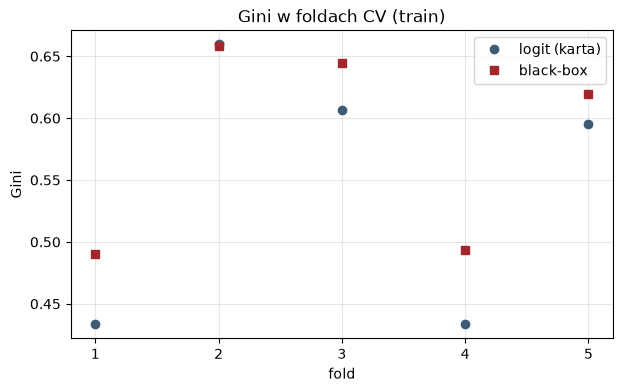

In [ ]:
cv_bb, _ = metryki_cv(lambda: model_black_box(**PARAM_BB), FEATURES)
stab = pd.DataFrame({f"{m}: {c}": {"średnia": t[c].mean(), "odch. std.": t[c].std(), "min": t[c].min(), "max": t[c].max()}
                     for m, t in [("logit", cv_logit), ("black-box", cv_bb)] for c in ["Gini", "KS", "PR-AUC", "log-loss", "Brier"]}).T
print("Metryki obu modeli w 5-krotnej CV na train:")
display(stab.round(4))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(cv_logit.index, cv_logit["Gini"], "o", color=KOL["logit"], label="logit (karta)")
ax.plot(cv_bb.index, cv_bb["Gini"], "s", color=KOL["black-box"], label="black-box")
ax.set_xticks(cv_bb.index); ax.set_xlabel("fold"); ax.set_ylabel("Gini"); ax.set_title("Gini w foldach CV (train)"); ax.legend(); ax.grid(alpha=0.3); plt.show()

**Wnioski:** w CV black-box ma średni Gini 0,581, a karta 0,546. Black-box ma wyższy Gini w 4 z 5 foldów;
odchylenie standardowe wynosi odpowiednio 0,083 i 0,105. Średni log-loss to 0,350 dla black-boxa i 0,359 dla karty.
Wyniki różnią się między foldami; niepewność różnicy Gini na valid i teście oceniono w 6.2.

### 6.4 Złożoność modeli

Porównujemy liczbę cech przed kodowaniem one-hot. Cecha XGBoost jest używana, jeśli co najmniej jedna
odpowiadająca jej kolumna została wykorzystana w podziale drzewa. Przedziały karty i liście drzew opisują różne
elementy modeli i nie są bezpośrednio porównywalnymi jednostkami.

Binning karty wymusza monotoniczną stopę defaultu na train w zwykłych przedziałach liczbowych, ale wygładzanie
nie gwarantuje monotoniczności WoE. Przedział BRAK rozpatrujemy osobno.

In [49]:
def zrodlo(nazwa):                                            # z Lab 4 (nazwy ColumnTransformer)
    if nazwa.startswith("num__"):
        return nazwa[5:]
    return next(c for c in cat_cols if nazwa.startswith(f"cat__{c}_"))

booster = black_box.named_steps["clf"].get_booster()
drzewa = booster.trees_to_dataframe()
uzyte = booster.get_score(importance_type="weight")
nazwy_kolumn = black_box.named_steps["pre"].get_feature_names_out()
cechy_uzyte = {zrodlo(nazwy_kolumn[int(n[1:])]) for n in uzyte}
zlozonosc = pd.DataFrame({
    "logit (karta)": {"liczba cech wejściowych": len(CECHY_L), "cechy faktycznie używane": len(CECHY_L),
                      "parametry / drzewa": f"{len(CECHY_L) + 1} współczynników",
                      "przedziały / liście": int(sum(len(woe_l.tables_[c]) for c in CECHY_L)),
                      "monotoniczność": "DR na train w przedziałach liczbowych"},
    "black-box (XGBoost)": {"liczba cech wejściowych": len(FEATURES), "cechy faktycznie używane": len(cechy_uzyte),
                            "parametry / drzewa": f"{drzewa['Tree'].nunique()} drzew, głębokość ≤ {PARAM_BB['max_depth']}",
                            "przedziały / liście": int((drzewa["Feature"] == "Leaf").sum()),
                            "monotoniczność": "brak ograniczeń"}})
print("Złożoność karty scoringowej i XGBoost:")
display(zlozonosc)

Złożoność karty scoringowej i XGBoost:


,logit (karta),black-box (XGBoost)
liczba cech wejściowych,8,195
cechy faktycznie używane,8,170
parametry / drzewa,9 współczynników,"800 drzew, głębokość ≤ 5"
przedziały / liście,37,7583
monotoniczność,DR na train w przedziałach liczbowych,brak ograniczeń


## 7. Wyjaśnienia globalne

**Ustawienia (Lab 4):** SHAP liczymy w **log-szansach**. Dla karty stosujemy wzór zamknięty
φ_j = β_j·(WoE_j(x) - E[WoE_j]), z całym train jako tłem.
Dla XGBoost używamy `TreeExplainer` w wariancie **`interventional`**: przekazujemy 300 firm z train,
a SHAP domyślnie wybiera z nich 100 jako tło. Wartość bazowa to średnie log-szanse na tym tle.
Oba modele wyjaśniamy podejściem interwencyjnym, ale z różnymi tłami. Wariant `tree_path_dependent`
stosujemy do wartości interakcji SHAP (8.4). Wkłady kolumn one-hot sumujemy dla każdej cechy źródłowej.

### 7.1 SHAP: wyliczenie i kontrola addytywności

In [56]:
pre_bb, clf_bb = black_box.named_steps["pre"], black_box.named_steps["clf"]
nazwy_bb = list(pre_bb.get_feature_names_out())

G_bb = np.array([[float(zrodlo(n) == f) for f in FEATURES] for n in nazwy_bb])     # z Lab 4: macierz grupowania kolumn
TLO_SHAP = pre_bb.transform(X_tr.sample(300, random_state=RNG_SEED))          # tło z train (wykład 4)
explainer = shap.TreeExplainer(clf_bb, data=TLO_SHAP, feature_perturbation="interventional", model_output="raw")
sv_te = explainer(pre_bb.transform(X_te))
PHI_BB = sv_te.values @ G_bb
BAZA_BB = float(np.ravel(sv_te.base_values)[0])
blad_bb = np.abs(BAZA_BB + PHI_BB.sum(axis=1) - _z(P["black-box"]["test"])).max()

W_tlo = woe_l.transform(X_tr[CECHY_L]).mean()
def shap_logit(Xw):
    # wzór zamknięty dla modelu liniowego w przestrzeni WoE (Lab 4, sekcja 3)
    return (woe_l.transform(Xw[CECHY_L]) - W_tlo) * lr_l.coef_.ravel()
PHI_LOG = shap_logit(X_te)
BAZA_LOG = float(lr_l.intercept_[0] + (W_tlo * lr_l.coef_.ravel()).sum())
blad_log = np.abs(BAZA_LOG + PHI_LOG.sum(axis=1) - baseline.decision_function(X_te[CECHY_L])).max()
print(f"Addytywność SHAP (maks. |baza + suma φ - f(x)| na teście): black-box {blad_bb:.1e}, karta {blad_log:.1e}")
print(f"Wartość bazowa φ₀ (log-szanse): black-box {BAZA_BB:+.3f}, karta {BAZA_LOG:+.3f} - σ(φ₀) nie musi być średnim PD (wykład 4); "
      f"średnie PD black-boxa na train: {P['black-box']['train'].mean():.1%}")

Addytywność SHAP (maks. |baza + suma φ - f(x)| na teście): black-box 5.2e-06, karta 8.9e-16
Wartość bazowa φ₀ (log-szanse): black-box -2.562, karta -2.215 - σ(φ₀) nie musi być średnim PD (wykład 4); średnie PD black-boxa na train: 14.6%


Addytywność jest spełniona z dokładnością numeryczną - suma wkładów odtwarza log-szanse każdej firmy. Wartość bazowa karty
(log-szanse przy średnim WoE) różni się od logitu średniego PD, bo funkcja logistyczna jest nieliniowa.

### 7.2 Ważność cech: SHAP i permutacja

Dwie miary: średnie |SHAP| na teście (wkład do log-szans) i **ważność permutacyjna** na valid (spadek AUC po
przemieszaniu cechy - Lab 1, Lab 3). Permutacja jest agnostyczna, więc liczymy ją dla obu modeli tą samą metodą.

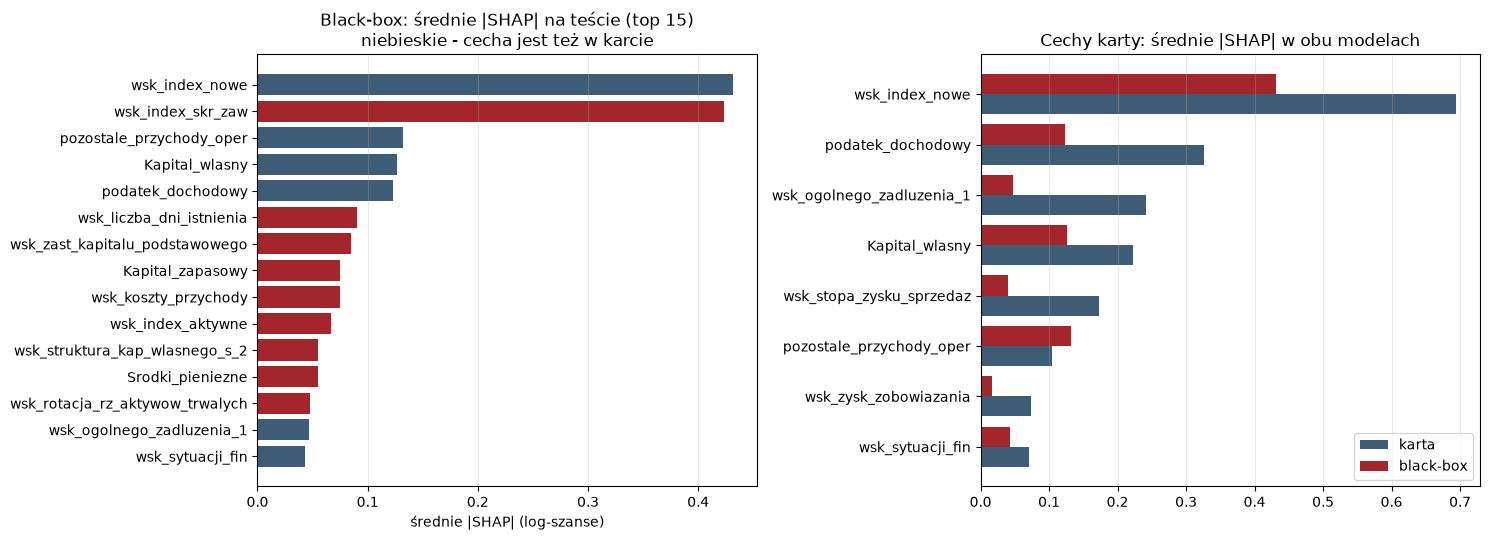

15 najważniejszych cech black-boxa według SHAP:


,|SHAP| black-box,ranga SHAP bb,permutacja bb (spadek AUC),± odch. std.,ranga perm. bb
wsk_index_nowe,0.4317,1,0.0404,0.0051,2
wsk_index_skr_zaw,0.4236,2,0.0503,0.0090,1
pozostale_przychody_oper,0.1317,3,-0.0015,0.0020,193
Kapital_wlasny,0.1266,4,-0.0004,0.0023,166
podatek_dochodowy,0.1229,5,0.0028,0.0031,6
wsk_liczba_dni_istnienia,0.0903,6,0.0038,0.0040,4
wsk_zast_kapitalu_podstawowego,0.0846,7,0.0010,0.0015,14
Kapital_zapasowy,0.0752,8,-0.0009,0.0008,182
wsk_koszty_przychody,0.0751,9,-0.0022,0.0019,195
wsk_index_aktywne,0.0670,10,0.0075,0.0032,3


Zgodność metod dla black-boxa (Spearman SHAP vs permutacja, wszystkie cechy): 0.14

Ważność cech karty w obu modelach:


,|SHAP| karta,permutacja karta,|SHAP| black-box,ranga w black-boxie (z 195)
Kapital_wlasny,0.2221,0.0050,0.1266,4
podatek_dochodowy,0.3261,0.0214,0.1229,5
pozostale_przychody_oper,0.1049,0.0019,0.1317,3
wsk_index_nowe,0.6944,0.1298,0.4317,1
wsk_ogolnego_zadluzenia_1,0.2417,0.0262,0.0469,14
wsk_stopa_zysku_sprzedaz,0.1725,0.0051,0.0396,17
wsk_sytuacji_fin,0.0713,-0.0007,0.0429,15
wsk_zysk_zobowiazania,0.0738,0.0031,0.0169,63


In [57]:
from sklearn.inspection import permutation_importance

waz_shap_bb = pd.Series(np.abs(PHI_BB).mean(axis=0), index=FEATURES).sort_values(ascending=False)
waz_shap_log = np.abs(PHI_LOG).mean().sort_values(ascending=False)
perm_bb = permutation_importance(black_box, X_va, y_va, scoring="roc_auc", n_repeats=5, random_state=RNG_SEED)   # z Lab 6 (2.1)
perm_log = permutation_importance(baseline, X_va[CECHY_L], y_va, scoring="roc_auc", n_repeats=20, random_state=RNG_SEED)
waz_perm_bb = pd.Series(perm_bb.importances_mean, index=FEATURES)
waz_perm_log = pd.Series(perm_log.importances_mean, index=CECHY_L)

TOP_BB = waz_shap_bb.index[:15].tolist()
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
t = waz_shap_bb[TOP_BB][::-1]
axes[0].barh(t.index, t.values, color=[KOL["logit"] if c in CECHY_L else KOL["black-box"] for c in t.index])
axes[0].set_title("Black-box: średnie |SHAP| na teście (top 15)\nniebieskie - cecha jest też w karcie"); axes[0].set_xlabel("średnie |SHAP| (log-szanse)")
t2 = pd.DataFrame({"karta: |SHAP|": waz_shap_log, "black-box: |SHAP| tej cechy": waz_shap_bb[CECHY_L]}).sort_values("karta: |SHAP|")
yy = np.arange(len(t2))
axes[1].barh(yy - 0.2, t2["karta: |SHAP|"], 0.4, color=KOL["logit"], label="karta")
axes[1].barh(yy + 0.2, t2["black-box: |SHAP| tej cechy"], 0.4, color=KOL["black-box"], label="black-box")
axes[1].set_yticks(yy); axes[1].set_yticklabels(t2.index); axes[1].legend(); axes[1].set_title("Cechy karty: średnie |SHAP| w obu modelach")
for ax in axes:
    ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.savefig("wykresy/shap_waznosc.png", dpi=120); plt.show()

ranking = pd.DataFrame({"|SHAP| black-box": waz_shap_bb, "ranga SHAP bb": waz_shap_bb.rank(ascending=False).astype(int),
                        "permutacja bb (spadek AUC)": waz_perm_bb, "± odch. std.": pd.Series(perm_bb.importances_std, index=FEATURES), "ranga perm. bb": waz_perm_bb.rank(ascending=False).astype(int)})
print("15 najważniejszych cech black-boxa według SHAP:")
display(ranking.sort_values("|SHAP| black-box", ascending=False).head(15).round(4))
print(f"Zgodność metod dla black-boxa (Spearman SHAP vs permutacja, wszystkie cechy): {spearmanr(waz_shap_bb, waz_perm_bb[waz_shap_bb.index])[0]:.2f}")
print("\nWażność cech karty w obu modelach:")
display(pd.DataFrame({"|SHAP| karta": waz_shap_log, "permutacja karta": waz_perm_log, "|SHAP| black-box": waz_shap_bb[CECHY_L],
                      f"ranga w black-boxie (z {len(FEATURES)})": waz_shap_bb.rank(ascending=False)[CECHY_L].astype(int)}).round(4))

**Wnioski:**
- Dwie najważniejsze cechy black-boxa według SHAP to wskaźniki branżowe `wsk_index_nowe` i `wsk_index_skr_zaw`
  (średnie |SHAP| 0,432 i 0,424). Zajmują też dwa pierwsze miejsca według permutacji. Kolejne trzy cechy według SHAP
  (`pozostale_przychody_oper`, `Kapital_wlasny`, `podatek_dochodowy`) są w karcie.
- W karcie największy średni |SHAP| ma `wsk_index_nowe`: ok. 36% sumy |SHAP| cech karty.
  `wsk_index_skr_zaw` nie wszedł do karty po filtrze korelacji WoE w 4.2.
- Zgodność rankingów SHAP i permutacji dla wszystkich cech black-boxa jest niska (ρ = 0,14). Metody mierzą różne
  aspekty ważności, a wpływ permutacji pojedynczej cechy może być niewielki, gdy model korzysta z innych skorelowanych cech.
  Na wynik wpływa też dobór próby. W karcie obie miary wskazują `wsk_index_nowe` jako najważniejszą cechę.

### 7.3 Spójność wyjaśnień black-boxa z kartą

Black-box otrzymuje 192 cechy liczbowe i 3 kategoryczne, a karta korzysta z 8 cech. Porównanie pojedynczych cech
może być niepełne, gdy model korzysta z kilku skorelowanych wskaźników. Dla każdej cechy karty tworzymy grupę
cech liczbowych black-boxa o |ρ Spearmana| ≥ 0,7 na train. Jeśli cecha pasuje do kilku grup, trafia do pierwszej
w kolejności cech karty. Pozostałe cechy, w tym kategorie, tworzą osobną grupę.

W tabeli sumujemy średnie |SHAP| cech w grupie. To suma ważności pojedynczych cech, a nie osobno obliczony SHAP grupy.

In [58]:
kor_tr = df_train[num_cols].corr(method="spearman")
temat, GRUPY_TEMAT = {}, {}
przypisane = set()
for c in CECHY_L:
    grupa_c = [f for f in num_cols if abs(kor_tr.loc[c, f]) >= 0.7 and f not in przypisane]
    przypisane |= set(grupa_c); GRUPY_TEMAT[c] = grupa_c
    temat[c] = {"cech w grupie": len(grupa_c), "suma |SHAP| grupy (black-box)": waz_shap_bb[grupa_c].sum(),
                "|SHAP| w karcie": waz_shap_log[c]}
reszta = [f for f in FEATURES if f not in przypisane]
GRUPY_TEMAT["pozostałe cechy"] = [f for f in reszta if f in num_cols]
temat["pozostałe cechy"] = {"cech w grupie": len(reszta), "suma |SHAP| grupy (black-box)": waz_shap_bb[reszta].sum(), "|SHAP| w karcie": 0.0}
tab_temat = pd.DataFrame(temat).T
tab_temat["udział w black-boxie"] = tab_temat["suma |SHAP| grupy (black-box)"] / tab_temat["suma |SHAP| grupy (black-box)"].sum()
tab_temat["udział w karcie"] = tab_temat["|SHAP| w karcie"] / tab_temat["|SHAP| w karcie"].sum()
display(tab_temat.round(3))
rho_temat = spearmanr(tab_temat.loc[CECHY_L, "suma |SHAP| grupy (black-box)"], tab_temat.loc[CECHY_L, "|SHAP| w karcie"])[0]
print(f"Korelacja rang ważności grup tematycznych (karta vs black-box): {rho_temat:.2f}")

,cech w grupie,suma |SHAP| grupy (black-box),|SHAP| w karcie,udział w black-boxie,udział w karcie
wsk_index_nowe,1.0,0.432,0.694,0.110,0.364
podatek_dochodowy,2.0,0.135,0.326,0.034,0.171
Kapital_wlasny,8.0,0.306,0.222,0.078,0.116
wsk_ogolnego_zadluzenia_1,17.0,0.325,0.242,0.083,0.127
wsk_zysk_zobowiazania,30.0,0.306,0.074,0.078,0.039
wsk_stopa_zysku_sprzedaz,2.0,0.115,0.173,0.029,0.090
wsk_sytuacji_fin,1.0,0.043,0.071,0.011,0.037
pozostale_przychody_oper,2.0,0.160,0.105,0.041,0.055
pozostałe cechy,132.0,2.115,0.000,0.537,0.000


Korelacja rang ważności grup tematycznych (karta vs black-box): 0.62


**Wnioski:** korelacja rang ważności ośmiu grup przypisanych do cech karty wynosi 0,62. W karcie największe udziały
w sumie średnich |SHAP| mają `wsk_index_nowe` (36,4%) i podatek (17,1%). W black-boxie grupa `wsk_index_nowe`
stanowi 11,0%, grupa zadłużenia 8,3%, a kapitału własnego 7,8%.

Na „pozostałe cechy” przypada 53,7% sumy średnich |SHAP| black-boxa. Należy do nich m.in. drugi wskaźnik
branżowy `wsk_index_skr_zaw`, którego korelacja z `wsk_index_nowe` nie przekracza przyjętego progu. Porównanie
pokazuje różnice w rozkładzie ważności, ale nie rozstrzyga, co powoduje różnicę jakości modeli.

#### 7.3.1 Ważność grup skorelowanych cech: permutacja grupowa i drop-column (Lab 6)

Ważność permutacyjna pojedynczej cechy może być niewielka, gdy ma ona skorelowane odpowiedniki (7.2). Dlatego, jak w Lab 6
(Zadanie 1), mierzymy ważność **grup cech liczbowych** z 7.3 dwiema metodami:
- **permutacja grupowa** - wszystkie cechy grupy mieszamy tą samą permutacją wierszy (valid, 5 powtórzeń) - *czy model z grupy korzysta?*,
- **drop-column grupy** - black-box uczony od nowa bez całej grupy, z tymi samymi hiperparametrami - *czy informację grupy da się zastąpić?*

Wyniki porównujemy z sumą ważności permutacyjnych pojedynczych cech. Grupa „pozostałe cechy” obejmuje tu 129 cech
liczbowych; w tabeli 7.3 obejmuje także 3 cechy kategoryczne. Kategorie pozostają w modelu przy drop-column.
Nie liczymy MDI, ponieważ może premiować cechy ciągłe o wielu punktach podziału (Lab 6, 2.2).

In [59]:
AUC_VA_BB = roc_auc_score(y_va, P["black-box"]["valid"])

def perm_grupy(grupa, n_rep=5, seed=RNG_SEED):                # z Lab 6 (Zadanie 1): ta sama permutacja dla całej grupy
    rng = np.random.default_rng(seed); auc = []
    for _ in range(n_rep):
        Xp = X_va.copy()
        Xp[grupa] = X_va[grupa].to_numpy()[rng.permutation(len(X_va))]
        auc.append(roc_auc_score(y_va, black_box.predict_proba(Xp)[:, 1]))
    return AUC_VA_BB - np.mean(auc), np.std(auc)

def drop_column(usun):                                        # z Lab 6 (2.3): model uczony od nowa bez cech
    ce = [f for f in num_cols if f not in usun]
    m = model_black_box(num=ce, **PARAM_BB).fit(X_tr, y_tr)
    return AUC_VA_BB - roc_auc_score(y_va, m.predict_proba(X_va)[:, 1])

wiersze = {}
for g, cechy_g in GRUPY_TEMAT.items():
    sr, sd = perm_grupy(cechy_g)
    wiersze[g] = {"cech": len(cechy_g), "permutacja grupy (spadek AUC)": sr, "± odch. std.": sd,
                  "suma permutacji pojedynczych": waz_perm_bb[cechy_g].sum(), "drop-column grupy (spadek AUC)": drop_column(cechy_g),
                  "suma |SHAP| grupy": waz_shap_bb[cechy_g].sum()}
TAB_GRUPY = pd.DataFrame(wiersze).T.sort_values("permutacja grupy (spadek AUC)", ascending=False)
display(TAB_GRUPY.round(4))
print(f"AUC black-boxa na valid: {AUC_VA_BB:.4f} | Spearman rang grup: permutacja vs SHAP = "
      f"{spearmanr(TAB_GRUPY['permutacja grupy (spadek AUC)'], TAB_GRUPY['suma |SHAP| grupy'])[0]:.2f}, "
      f"permutacja vs drop-column = {spearmanr(TAB_GRUPY['permutacja grupy (spadek AUC)'], TAB_GRUPY['drop-column grupy (spadek AUC)'])[0]:.2f}")

,cech,permutacja grupy (spadek AUC),± odch. std.,suma permutacji pojedynczych,drop-column grupy (spadek AUC),suma |SHAP| grupy
pozostałe cechy,129.0,0.0802,0.0121,0.0609,0.0264,2.0749
wsk_index_nowe,1.0,0.0502,0.0118,0.0404,0.0086,0.4317
wsk_ogolnego_zadluzenia_1,17.0,0.0218,0.0025,0.0022,0.0001,0.3253
podatek_dochodowy,2.0,0.0050,0.0027,0.0027,-0.0020,0.1354
wsk_zysk_zobowiazania,30.0,0.0049,0.0038,0.0027,0.0029,0.3056
wsk_sytuacji_fin,1.0,0.0024,0.0014,0.0018,-0.0026,0.0429
Kapital_wlasny,8.0,0.0022,0.0040,0.0024,-0.0023,0.3058
wsk_stopa_zysku_sprzedaz,2.0,0.0006,0.0023,-0.0033,-0.0033,0.1146
pozostale_przychody_oper,2.0,-0.0018,0.0026,-0.0016,-0.0027,0.1596


AUC black-boxa na valid: 0.8334 | Spearman rang grup: permutacja vs SHAP = 0.70, permutacja vs drop-column = 0.92


**Wnioski:**
- Największy spadek AUC po permutacji dotyczy „pozostałych cech” (0,0802), `wsk_index_nowe` (0,0502)
  i grupy zadłużenia (0,0218). Korelacja rang permutacji grupowej i sumy |SHAP| wynosi 0,70.
- Dla 17 cech grupy zadłużenia suma ważności pojedynczych cech wynosi 0,0022, a ważność całej grupy 0,0218.
  Pokazuje to, że pojedyncza i grupowa permutacja mogą dawać różny obraz znaczenia skorelowanych cech.
- Po ponownym uczeniu bez grupy spadek AUC wynosi 0,0264 dla „pozostałych cech”, 0,0086 dla `wsk_index_nowe`
  i 0,0001 dla zadłużenia. Mała zmiana sugeruje, że inne cechy mogą częściowo zastąpić usuniętą informację,
  ale wynik dotyczy tego uczenia i tej próby valid. Korelacja rang permutacji i drop-column wynosi 0,92.

### 7.4 Beeswarm i wykresy zależności SHAP

Na wykresie beeswarm kolor oznacza rangę percentylową wartości cechy na teście. Na wykresach zależności oś X
pokazuje wartości cech przycięte do 2.–98. percentyla train, aby ograniczyć wpływ skrajnych wartości.
Punkty pokazują wkład SHAP black-boxa dla firm z testu, a schodki - wkład karty, jeśli cecha do niej należy.

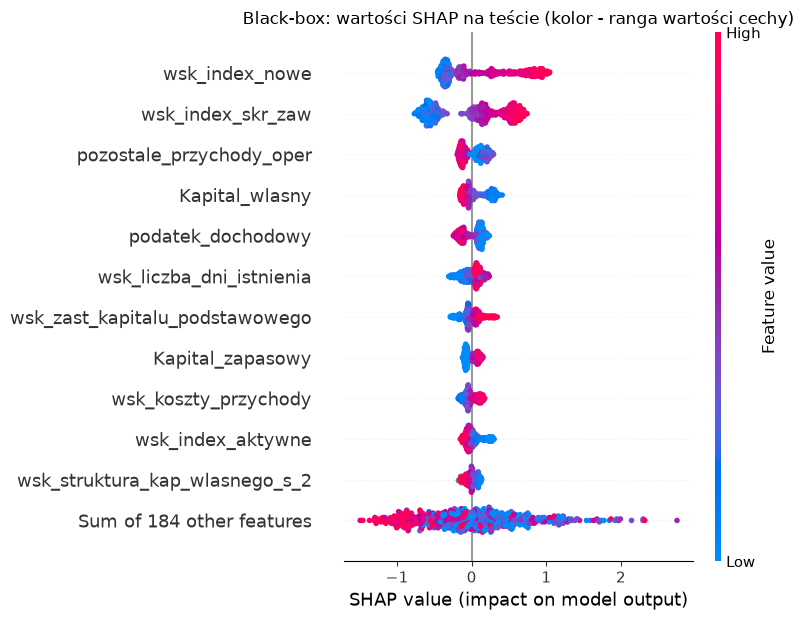

In [60]:
kolor_dane = X_te[num_cols].rank(pct=True).reindex(columns=FEATURES)
E_bb = shap.Explanation(values=PHI_BB, base_values=np.full(len(PHI_BB), BAZA_BB),
                        data=kolor_dane.to_numpy(dtype=float), feature_names=FEATURES)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    shap.plots.beeswarm(E_bb, max_display=12, show=False)
plt.title("Black-box: wartości SHAP na teście (kolor - ranga wartości cechy)"); plt.tight_layout()
plt.savefig("wykresy/shap_beeswarm.png", dpi=120, bbox_inches="tight"); plt.show()

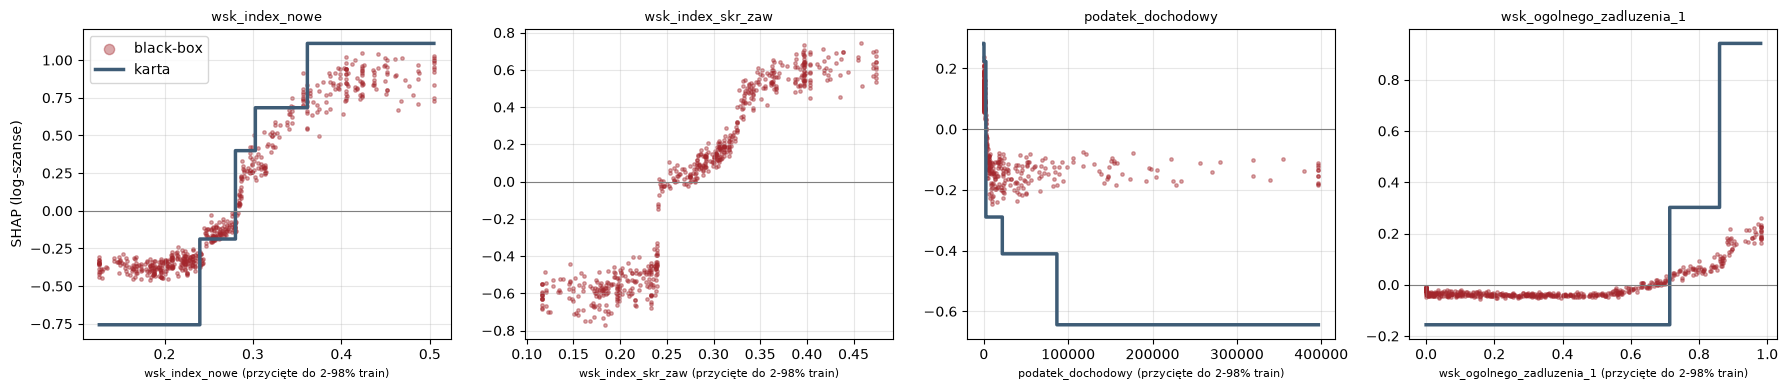

In [61]:
CECHY_DEP = [c for c in TOP_BB if c in num_cols][:2] + [c for c in waz_shap_log.index if c not in TOP_BB[:2]][:2]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, CECHY_DEP):
    j = FEATURES.index(c); xv = X_te[c].to_numpy()
    lo, hi = np.nanpercentile(X_tr[c], [2, 98])
    ax.scatter(np.clip(xv, lo, hi), PHI_BB[:, j], s=6, alpha=0.4, color=KOL["black-box"], label="black-box")
    if c in CECHY_L:
        o = np.argsort(xv)
        ax.step(np.clip(xv[o], lo, hi), PHI_LOG[c].to_numpy()[o], color=KOL["logit"], lw=2.5, where="post", label="karta")
    ax.axhline(0, color="gray", lw=0.8); ax.set_title(c, fontsize=9); ax.set_xlabel(f"{c} (przycięte do 2-98% train)", fontsize=8); ax.grid(alpha=0.3)
axes[0].set_ylabel("SHAP (log-szanse)"); axes[0].legend(markerscale=3)
plt.tight_layout(); plt.savefig("wykresy/shap_zaleznosc.png", dpi=120); plt.show()

**Wnioski:** na teście wyższym wartościom `wsk_index_nowe` i `wsk_index_skr_zaw` odpowiadają większe wkłady SHAP
black-boxa. Dla `wsk_index_nowe` podobny kierunek widać w karcie; `wsk_index_skr_zaw` nie należy do karty.
Dodatni podatek zwykle wiąże się z ujemnym wkładem w obu modelach, a przy wyższym zadłużeniu wkład rośnie.
Dla podatku i zadłużenia wielkości wkładów różnią się między modelami. Wykresy opisują zachowanie modeli,
nie dowodzą związku przyczynowego.

## 8. Kształt zależności: PDP, ICE, ALE (Lab 5)

Krzywe przedstawiają **log-szanse** lub ich zmianę dla firm z testu (`XS`). Siatki PDP i ICE wyznaczamy
z kwantyli 2–98% train. W 8.2 porównujemy PDP i ALE na granicach przedziałów ALE wyznaczonych z testu.
Ograniczenie zakresu pojedynczej cechy nie wyklucza nietypowych kombinacji skorelowanych cech.
Funkcje `pdp`, `ice`, `ale`, `pdp_wysrodkowane` pochodzą z Lab 5. Dla cech, których nie ma w karcie,
krzywa karty jest płaska.

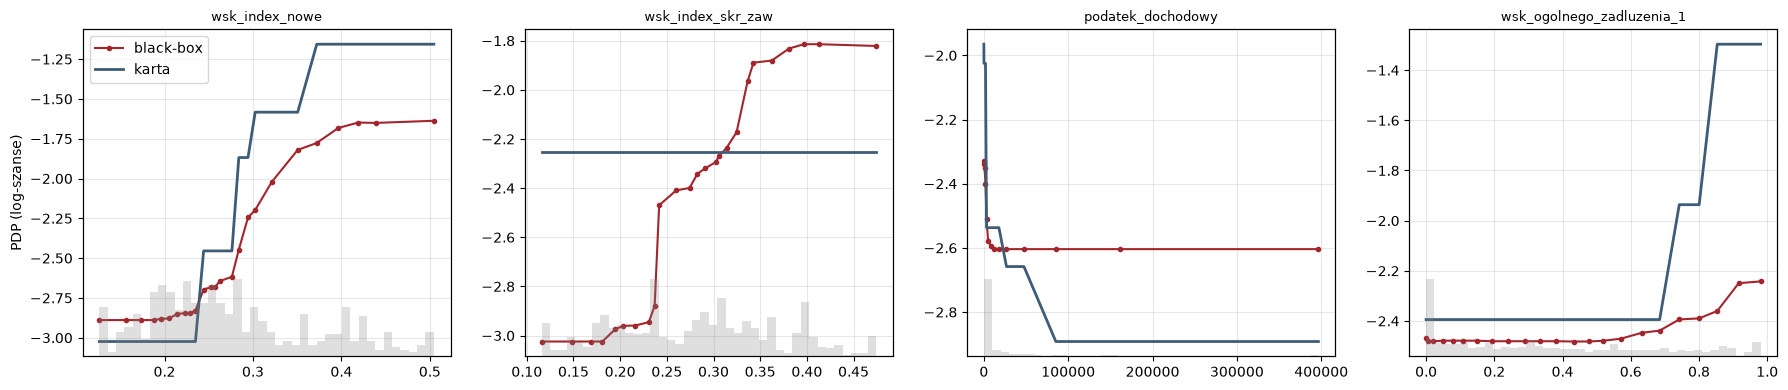

In [62]:
def log_szanse(model, cechy=None):                            # z Lab 4
    return lambda Xw: _z(model.predict_proba(Xw if cechy is None else Xw[cechy])[:, 1])

f_bb, f_lg = log_szanse(black_box), log_szanse(baseline, CECHY_L)
XS = X_te.reset_index(drop=True)

def siatka_kwantyli(cecha, n=25, lo=0.02, hi=0.98):          # z Lab 5
    return np.unique(np.quantile(X_tr[cecha].dropna(), np.linspace(lo, hi, n)))

def pdp(f, X, cecha, siatka):                                 # z Lab 5
    """PDP z definicji: wartość z siatki podstawiamy wszystkim firmom i uśredniamy prognozę."""
    wynik = []
    for v in siatka:
        Xv = X.copy(); Xv[cecha] = v
        wynik.append(np.mean(f(Xv)))
    return np.array(wynik)

def ice(f, X, cecha, siatka):                                 # z Lab 5
    """Macierz ICE (firmy × siatka): prognoza każdej firmy dla każdej wartości cechy."""
    duze = pd.concat([X.assign(**{cecha: v}) for v in siatka], ignore_index=True)
    return np.asarray(f(duze)).reshape(len(siatka), len(X)).T

def ale(f, X, cecha, K=20):                                   # z Lab 5
    """ALE pierwszego rzędu z definicji."""
    x = X[cecha].to_numpy(dtype=float); ok = ~np.isnan(x)
    granice = np.unique(np.quantile(x[ok], np.linspace(0, 1, K + 1)))
    k = np.clip(np.searchsorted(granice, x[ok], side="left") - 1, 0, len(granice) - 2)
    Xd, Xg = X.loc[ok].copy(), X.loc[ok].copy()
    Xd[cecha], Xg[cecha] = granice[k], granice[k + 1]
    roznice = f(Xg) - f(Xd)
    n_k = np.bincount(k, minlength=len(granice) - 1)
    efekt = np.bincount(k, weights=roznice, minlength=len(granice) - 1) / np.maximum(n_k, 1)
    a = np.concatenate([[0.0], np.cumsum(efekt)])
    a -= np.sum((a[:-1] + a[1:]) / 2 * n_k) / n_k.sum()
    return granice, a, n_k

def pdp_wysrodkowane(f, X, cecha, siatka):                    # z Lab 5
    p = pdp(f, X, cecha, siatka)
    return p - np.interp(X[cecha].dropna(), siatka, p).mean()

CECHY_PDP = CECHY_DEP
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, CECHY_PDP):
    s = siatka_kwantyli(c)
    ax.plot(s, pdp(f_bb, XS, c, s), "o-", ms=3, color=KOL["black-box"], label="black-box")
    ax.plot(s, pdp(f_lg, XS, c, s), "-", lw=2, color=KOL["logit"], label="karta")
    ax2 = ax.twinx(); ax2.hist(XS[c].dropna().clip(s.min(), s.max()), bins=40, color="gray", alpha=0.25)
    ax2.set_yticks([]); ax2.set_ylim(0, ax2.get_ylim()[1] * 4)
    ax.set_title(c, fontsize=9); ax.grid(alpha=0.3)
axes[0].set_ylabel("PDP (log-szanse)"); axes[0].legend()
plt.tight_layout(); plt.savefig("wykresy/pdp.png", dpi=120); plt.show()

**Wnioski:** PDP black-boxa i karty mają zgodne kierunki dla wszystkich czterech cech. Dla wskaźników branżowych black-box ma wyraźny
próg ok. 0,24-0,25 i nasycenie powyżej ok. 0,35-0,4 (efekt ok. 1 log-szansy); karta ma podobne schodki dla `wsk_index_nowe`, a dla
`wsk_index_skr_zaw`, którego nie zawiera, krzywą płaską. Dla podatku black-box reaguje tylko na przejście przez zero, karta - schodkowo
do ok. 85 tys. zł. Dla zadłużenia oba modele pokazują próg ok. 0,7-0,85 (bliskie zera kapitały własne), ale w black-boxie efekt tej
jednej cechy jest mały, bo rozkłada się na skorelowane wskaźniki zadłużenia.

### 8.1 ICE i c-ICE - czy wszystkie firmy reagują tak samo?

ICE pokazuje prognozę dla każdej firmy przy różnych wartościach cechy, a c-ICE - jej zmianę względem
pierwszej wartości siatki. Na wykresach pokazujemy 300 firm; czarne linie i wyniki liczymy dla całego testu.

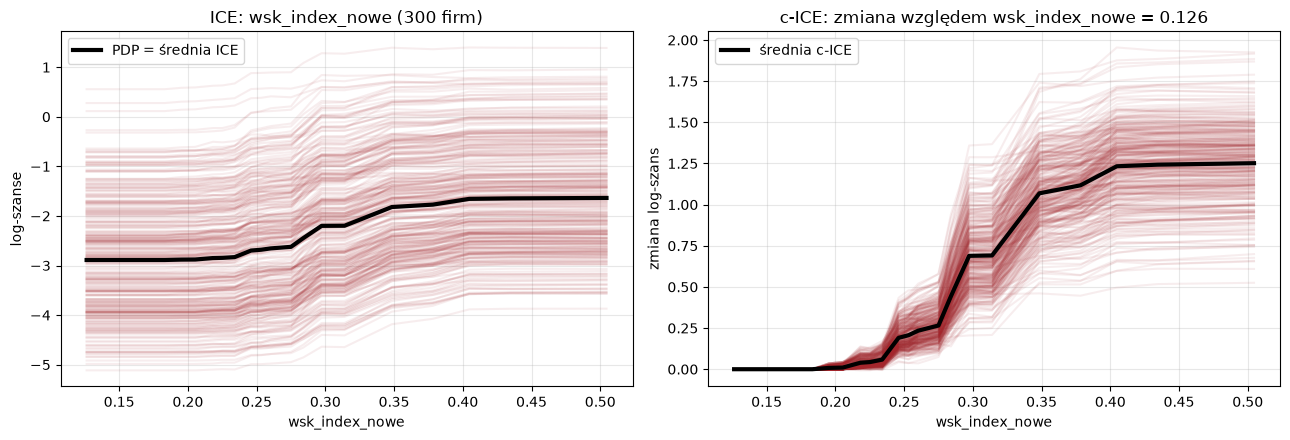

Zmiana wsk_index_nowe z 0.126 do 0.505: średnio +1.252 log-szans; 10% firm: < +0.920, 10% firm: > +1.560
   wielkość = mikro    : średni efekt +1.235 (n = 174)
   wielkość = mała     : średni efekt +1.167 (n = 100)
   wielkość = pozostałe: średni efekt +1.287 (n = 325)


In [63]:
c_ice = CECHY_PDP[0]
S_ICE = siatka_kwantyli(c_ice, n=20)
ICE_M = ice(f_bb, XS, c_ice, S_ICE)
C_ICE = ICE_M - ICE_M[:, [0]]                                 # c-ICE: punkt odniesienia = najniższa wartość z siatki
pokaz = np.random.default_rng(RNG_SEED).choice(len(XS), 300, replace=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(S_ICE, ICE_M[pokaz].T, color=KOL["black-box"], alpha=0.08); axes[0].plot(S_ICE, ICE_M.mean(axis=0), color="black", lw=3, label="PDP = średnia ICE")
axes[0].set_title(f"ICE: {c_ice} (300 firm)"); axes[0].set_ylabel("log-szanse")
axes[1].plot(S_ICE, C_ICE[pokaz].T, color=KOL["black-box"], alpha=0.08); axes[1].plot(S_ICE, C_ICE.mean(axis=0), color="black", lw=3, label="średnia c-ICE")
axes[1].set_title(f"c-ICE: zmiana względem {c_ice} = {S_ICE[0]:.3g}"); axes[1].set_ylabel("zmiana log-szans")
for ax in axes:
    ax.set_xlabel(c_ice); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("wykresy/ice.png", dpi=120); plt.show()
EFEKT = C_ICE[:, -1]
print(f"Zmiana {c_ice} z {S_ICE[0]:.3g} do {S_ICE[-1]:.3g}: średnio {EFEKT.mean():+.3f} log-szans; "
      f"10% firm: < {np.percentile(EFEKT, 10):+.3f}, 10% firm: > {np.percentile(EFEKT, 90):+.3f}")
for nazwa, maska in [("mikro", XS["wielkosc"] == "mikro"), ("mała", XS["wielkosc"] == "mała"), ("pozostałe", XS["wielkosc"] == "pozostałe")]:
    print(f"   wielkość = {nazwa:9s}: średni efekt {EFEKT[maska.to_numpy()].mean():+.3f} (n = {maska.sum()})")

**Wnioski:** zmiana `wsk_index_nowe` z 0,126 do 0,505 daje średnio +1,252 log-szans. Dziesiąty i dziewięćdziesiąty
percentyl efektu to +0,920 i +1,560. Średnie efekty wynoszą +1,235 dla firm mikro, +1,167 dla małych i +1,287
dla pozostałych. Reakcje poszczególnych firm są zróżnicowane. Wynik opisuje zachowanie modelu po podstawieniu
wartości cechy, a nie dowodzi związku przyczynowego.

### 8.2 PDP a ALE przy skorelowanych cechach

PDP podstawia wartość cechy wszystkim firmom, także gdy powstają nietypowe kombinacje skorelowanych cech (3.3).
ALE liczy efekty lokalnie, w przedziałach cechy. Porównujemy wyśrodkowane krzywe na teście; tabela pokazuje
maksymalną różnicę między nimi oraz jej stosunek do zakresu ALE.

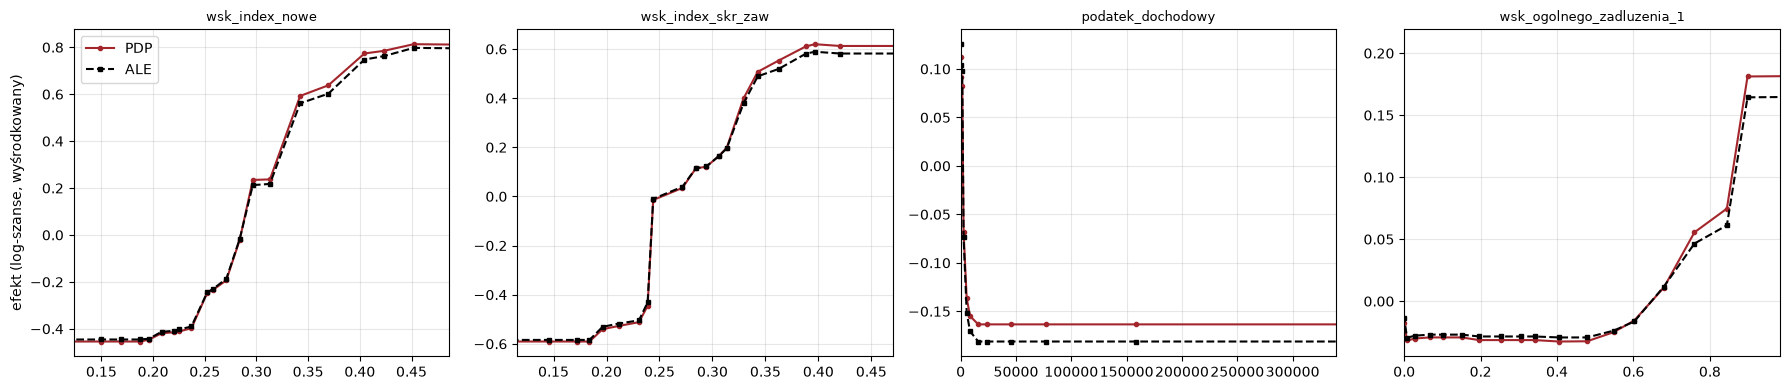

,zakres ALE,maks. |PDP - ALE|,min. liczność przedziału ALE,maks. |ρ| z inną cechą,różnica / zakres
wsk_index_nowe,1.243,0.036,25.0,0.653,0.029
wsk_index_skr_zaw,1.173,0.034,25.0,0.653,0.029
podatek_dochodowy,0.307,0.018,28.0,0.714,0.058
wsk_ogolnego_zadluzenia_1,0.194,0.017,20.0,0.996,0.087


In [64]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4)); roznice = {}
for ax, c in zip(axes, CECHY_PDP):
    gr, a, n_k = ale(f_bb, XS, c, K=20)                      # wykład 5: K = 20-50
    p = pdp_wysrodkowane(f_bb, XS, c, gr)
    ax.plot(gr, p, "o-", ms=3, color=KOL["black-box"], label="PDP"); ax.plot(gr, a, "s--", ms=3, color="black", label="ALE")
    ax.set_xlim(np.nanpercentile(XS[c], [2, 98])); ax.set_title(c, fontsize=9); ax.grid(alpha=0.3)
    w = (gr >= np.nanpercentile(XS[c], 2)) & (gr <= np.nanpercentile(XS[c], 98))
    roznice[c] = {"zakres ALE": np.ptp(a[w]), "maks. |PDP - ALE|": np.abs(p - a)[w].max(),
                  "min. liczność przedziału ALE": int(n_k.min()), "maks. |ρ| z inną cechą": kor_tr.loc[c].drop(c).abs().max() if c in kor_tr else np.nan}
axes[0].set_ylabel("efekt (log-szanse, wyśrodkowany)"); axes[0].legend()
plt.tight_layout(); plt.savefig("wykresy/pdp_ale.png", dpi=120); plt.show()
display(pd.DataFrame(roznice).T.assign(**{"różnica / zakres": lambda t: t["maks. |PDP - ALE|"] / t["zakres ALE"]}).round(3))

**Wnioski:** dla czterech badanych cech maksymalna różnica PDP - ALE wynosi odpowiednio 2,9%, 2,9%, 5,8%
i 8,7% zakresu ALE. Krzywe są zbliżone, także dla zadłużenia, mimo jego silnej korelacji z innym wskaźnikiem
(|ρ| = 0,996). ALE liczymy przy K = 20; najmniejszy przedział zawiera od 20 do 28 firm, zależnie od cechy.
Nie oszacowano niepewności krzywych.

### 8.3 Monotoniczność względem intuicji ekonomicznej

Dla większości cech kierunek ustalamy na podstawie wiedzy ekonomicznej lub EDA. Dla pozostałych przyjmujemy
znak korelacji Spearmana z defaultem na train; dotyczy to tu wieku firmy. Tabela z Lab 5 pokazuje, jaka część
sumy zmian PDP black-boxa na siatce idzie w kierunku przeciwnym do oczekiwanego. To nie jest odsetek firm.
Kolumna „cecha w karcie” informuje tylko o obecności cechy, nie o zgodności kierunków obu modeli.

In [ ]:
EKONOMIA = {"podatek_dochodowy": -1, "Kapital_wlasny": -1, "wsk_ogolnego_zadluzenia_1": +1, "wsk_zysk_zobowiazania": -1,
              "wsk_stopa_zysku_sprzedaz": -1, "wsk_sytuacji_fin": -1, "pozostale_przychody_oper": -1, "wsk_index_skr_zaw": +1, "wsk_index_nowe": +1}   # kierunki z ekonomii / EDA (3.1)

def oczekiwany_kierunek(c):
    if c in EKONOMIA:
        return EKONOMIA[c]
    rho = spearmanr(df_train[c], df_train[TARGET], nan_policy="omit")[0]
    if not np.isfinite(rho) or rho == 0:
        raise ValueError(f"Nie można wyznaczyć kierunku dla {c}: korelacja z defaultem jest zerowa lub nieokreślona")
    return int(np.sign(rho))

OCZEKIWANY = {c: oczekiwany_kierunek(c)
              for c in CECHY_L + [c for c in TOP_BB[:6] if c not in CECHY_L and c in num_cols]}

def naruszenia(f, kierunki):                                  # z Lab 5
    w = {}
    for c, kier in kierunki.items():
        s = siatka_kwantyli(c)
        d = np.diff(ice(f, XS, c, s).mean(axis=0)) * kier
        w[c] = {"oczekiwany kierunek": "+" if kier > 0 else "-", "zmienność PDP": np.abs(d).sum(),
                "suma naruszeń": float(np.abs(d[d < 0].sum())), "maks. naruszenie": float(np.abs(min(d.min(), 0.0)))}
    t = pd.DataFrame.from_dict(w, orient="index")
    t["udział naruszeń"] = t["suma naruszeń"] / t["zmienność PDP"]
    return t

tab_mono = naruszenia(f_bb, OCZEKIWANY)
tab_mono["cecha w karcie"] = [("tak" if c in CECHY_L else "-") for c in tab_mono.index]
print("Naruszenia monotoniczności PDP black-boxa na teście:")
display(tab_mono.round(3))

Naruszenia monotoniczności PDP black-boxa na teście:


,oczekiwany kierunek,zmienność PDP,suma naruszeń,maks. naruszenie,udział naruszeń,cecha w karcie
wsk_index_nowe,+,1.258,0.003,0.002,0.003,tak
podatek_dochodowy,-,0.276,0.000,0.000,0.000,tak
Kapital_wlasny,-,0.426,0.005,0.005,0.011,tak
wsk_ogolnego_zadluzenia_1,+,0.259,0.017,0.014,0.067,tak
wsk_zysk_zobowiazania,-,0.043,0.000,0.000,0.000,tak
wsk_stopa_zysku_sprzedaz,-,0.163,0.004,0.003,0.022,tak
wsk_sytuacji_fin,-,0.175,0.043,0.015,0.246,tak
pozostale_przychody_oper,-,0.485,0.134,0.099,0.276,tak
wsk_index_skr_zaw,+,1.217,0.007,0.007,0.006,-
wsk_liczba_dni_istnienia,-,0.346,0.286,0.086,0.826,-


**Wnioski:** dla podatku i `wsk_zysk_zobowiazania` nie ma naruszeń na badanej siatce. Udział naruszeń
wynosi 0,3% dla `wsk_index_nowe`, 0,6% dla `wsk_index_skr_zaw` i 6,7% dla zadłużenia.
Większe udziały dotyczą `wsk_sytuacji_fin` (24,6%), `pozostale_przychody_oper` (27,6%) i wieku firmy (82,6%).
Oczekiwany kierunek dla wieku wynika z korelacji na train, a nie z góry przyjętej reguły ekonomicznej.
XGBoost nie ma ograniczeń monotonicznych. Binning karty wymusza monotoniczność stopy defaultu na train
w zwykłych przedziałach liczbowych, ale nie gwarantuje monotonicznego WoE.

### 8.4 Interakcje: kandydaci z SHAP, weryfikacja statystyką H (Lab 4, Lab 6)

Rozrzut c-ICE (8.1) i wykresów zależności SHAP (7.4) może wskazywać na interakcje. Na podstawie wartości
interakcji SHAP (`tree_path_dependent`, Lab 4) dla 300 firm z testu wybieramy cztery pary o największej
średniej sile interakcji. Dodajemy parę kontrolną o najmniejszej interakcji SHAP wśród 10 ważnych cech liczbowych.

Dla każdej pary liczymy statystykę H Friedmana i RMS (Lab 6) w log-szansach, na dwóch losowaniach po 150 firm
z testu. Losowania mogą się nakładać; wypisujemy liczbę wspólnych firm. H mierzy wielkość odstępstwa od sumy
efektów pojedynczych względem zmienności wspólnej PDP, a RMS - bezwzględną wielkość odstępstwa w log-szansach.
Gdy wspólna PDP się nie zmienia, H jest nieokreślone.

In [ ]:
def h_statistic(f, X, j, k):                                  # z Lab 6 (3)
    """H Friedmana dla pary (j, k): wycentrowane funkcje częściowej zależności liczone w punktach próby X."""
    n, Xr = len(X), X.reset_index(drop=True)
    duza = pd.concat([Xr] * n, ignore_index=True)
    def czesciowa(cechy):
        B = duza.copy()
        for c in cechy:
            B[c] = np.repeat(Xr[c].to_numpy(), n)
        v = np.asarray(f(B)).reshape(n, n).mean(axis=1)
        return v - v.mean()
    pjk, pj, pk = czesciowa([j, k]), czesciowa([j]), czesciowa([k])
    reszta = pjk - pj - pk
    rms = float(np.sqrt(np.mean(reszta ** 2)))
    mianownik = np.sum(pjk ** 2)
    if np.ptp(pjk) == 0 or mianownik == 0:
        print(f"H nieokreślone dla {j} × {k}: wspólna PDP się nie zmienia.")
        return np.nan, rms
    return float(np.sqrt(np.sum(reszta ** 2) / mianownik)), rms

idx_int = np.random.default_rng(RNG_SEED).choice(len(X_te), 300, replace=False)        # z Lab 4: interakcje SHAP
IV = np.einsum("nij,ia,jb->nab", shap.TreeExplainer(clf_bb).shap_interaction_values(pre_bb.transform(X_te.iloc[idx_int])), G_bb, G_bb, optimize=True)
SILA_INT = pd.DataFrame(2 * np.abs(IV).mean(axis=0), index=FEATURES, columns=FEATURES)
gorne_int = SILA_INT.where(np.triu(np.ones(SILA_INT.shape, dtype=bool), k=1)).stack().sort_values(ascending=False)
PARY_H = list(gorne_int.index[:4])
top10 = [c for c in TOP_BB if c in num_cols][:10]
kontrolna = min(itertools.combinations(top10, 2), key=lambda p: SILA_INT.loc[p[0], p[1]])
PARY_H.append(kontrolna)

PROBY_H = {s: X_te.sample(150, random_state=s) for s in [1, 2]}
print(f"Liczba wspólnych firm w losowaniach H: {len(PROBY_H[1].index.intersection(PROBY_H[2].index))}")
wiersze = []
for a, b in PARY_H:
    w = {"para": f"{a} × {b}", "rodzaj": "kontrolna" if (a, b) == kontrolna else "kandydat z SHAP",
         "siła interakcji SHAP": SILA_INT.loc[a, b]}
    for s in [1, 2]:
        h, rms = h_statistic(f_bb, PROBY_H[s], a, b)
        w[f"H (próba {s})"], w[f"RMS (próba {s})"] = h, rms
    wiersze.append(w)
TAB_H = pd.DataFrame(wiersze).set_index("para")
print("Interakcje SHAP i statystyka H dla wybranych par:")
display(TAB_H.round(3))

Liczba wspólnych firm w losowaniach H: 39
Interakcje SHAP i statystyka H dla wybranych par:


,rodzaj,siła interakcji SHAP,H (próba 1),RMS (próba 1),H (próba 2),RMS (próba 2)
para,,,,,,
wsk_index_nowe × wsk_liczba_dni_istnienia,kandydat z SHAP,0.028,0.061,0.033,0.060,0.030
wsk_index_nowe × podatek_dochodowy,kandydat z SHAP,0.026,0.055,0.030,0.063,0.031
wsk_index_nowe × wsk_sytuacji_fin,kandydat z SHAP,0.026,0.050,0.026,0.053,0.026
wsk_index_skr_zaw × pozostale_przychody_oper,kandydat z SHAP,0.023,0.044,0.023,0.043,0.022
podatek_dochodowy × Kapital_zapasowy,kontrolna,0.000,0.004,0.000,0.003,0.000


**Wnioski:**
- Najsilniejsza para według SHAP to `wsk_index_nowe × wsk_liczba_dni_istnienia` (0,028). Dla niej H wynosi
  0,061 i 0,060, a RMS 0,033 i 0,030 log-szans w dwóch losowaniach.
- Dla czterech wybranych par H wynosi 0,043–0,063, a RMS 0,022–0,033. Dla pary kontrolnej
  `podatek_dochodowy × Kapital_zapasowy` H wynosi 0,004 i 0,003, a RMS po zaokrągleniu 0,000.
- Wyniki obu losowań są zbliżone, ale obejmują 39 wspólnych firm. Opisują badane pary i próby; nie dowodzą,
  że wszystkie interakcje w modelu są słabe ani że metoda nie wskazuje fałszywych interakcji.

## 9. Wyjaśnienia lokalne: studia przypadków

Wybieramy cztery firmy z testu na podstawie **surowych PD**, przed kalibracją do 4%:
1. najwyższe PD black-boxa;
2. PD black-boxa najbliższe teoretycznemu progowi p* = MARGIN / (MARGIN + LGD) ≈ 18,2% (12.3);
3. PD black-boxa najbliższe medianie na całym teście;
4. największa różnica rang PD karty i black-boxa.

Wybór firmy granicznej na podstawie surowego PD nie musi odpowiadać decyzji po kalibracji do 4%.
Numer wiersza w tabeli to pozycja w zbiorze testowym, liczona od zera.

Dla każdej firmy pokazujemy wykres SHAP black-boxa, sześć największych wkładów SHAP i punkty karty.
SHAP opisuje wkład do log-szans względem wartości bazowej, a `e^φ` jest mnożnikiem szans, nie PD.
„Utracone vs maksimum” to różnica punktów względem najlepszego przedziału danej cechy. LIME omawiamy w 9.1.

Wybrane firmy na teście (surowe PD; próg p* = 0.18182, czyli 18.182%):


,wiersz testu,PD black-box,PD karta,punkty karty,default (fakt)
przypadek,,,,,
najwyższe PD,102,0.80340,0.68165,465.2,0
graniczna (PD ≈ p*),365,0.18153,0.17937,531.0,0
firma o medianowym PD,449,0.07232,0.09142,553.4,0
niezgodność modeli,3,0.22531,0.03404,583.7,1



=== najwyższe PD: wiersz 102, PD black-box 80.3%, PD karta 68.2%, default = 0 ===


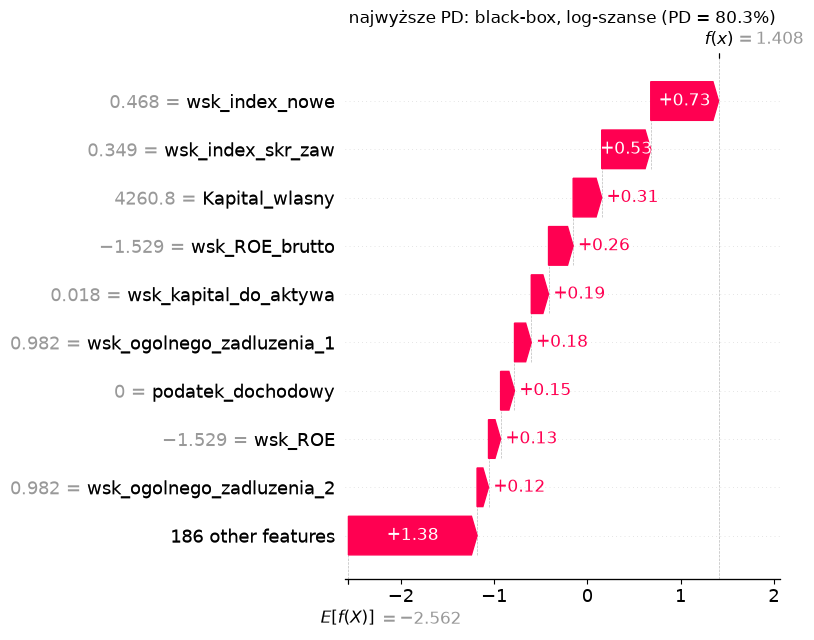

Sześć największych wkładów SHAP black-boxa:


,wartość,SHAP,mnożnik szans e^φ,kierunek
wsk_index_nowe,0.467532,0.727,2.07,podnosi ryzyko
wsk_index_skr_zaw,0.349068,0.526,1.69,podnosi ryzyko
Kapital_wlasny,4260.800000,0.306,1.36,podnosi ryzyko
wsk_ROE_brutto,-1.529365,0.264,1.30,podnosi ryzyko
wsk_kapital_do_aktywa,0.018305,0.185,1.20,podnosi ryzyko
wsk_ogolnego_zadluzenia_1,0.981695,0.180,1.20,podnosi ryzyko


Punkty karty i różnica względem maksimum dla każdej cechy:


,wartość,punkty,utracone vs maksimum,SHAP karty
wsk_index_nowe,0.467532,41.1,53.9,1.111
wsk_ogolnego_zadluzenia_1,0.981695,41.8,31.7,0.942
podatek_dochodowy,0.0,61.2,26.7,0.282
Kapital_wlasny,4260.8,58.4,21.0,0.356
wsk_stopa_zysku_sprzedaz,-0.019691,65.9,9.7,0.078
pozostale_przychody_oper,0.0,64.5,6.3,0.109
wsk_zysk_zobowiazania,-0.028517,65.5,5.3,0.072
wsk_sytuacji_fin,0.542254,66.8,3.3,0.027



=== graniczna (PD ≈ p*): wiersz 365, PD black-box 18.2%, PD karta 17.9%, default = 0 ===


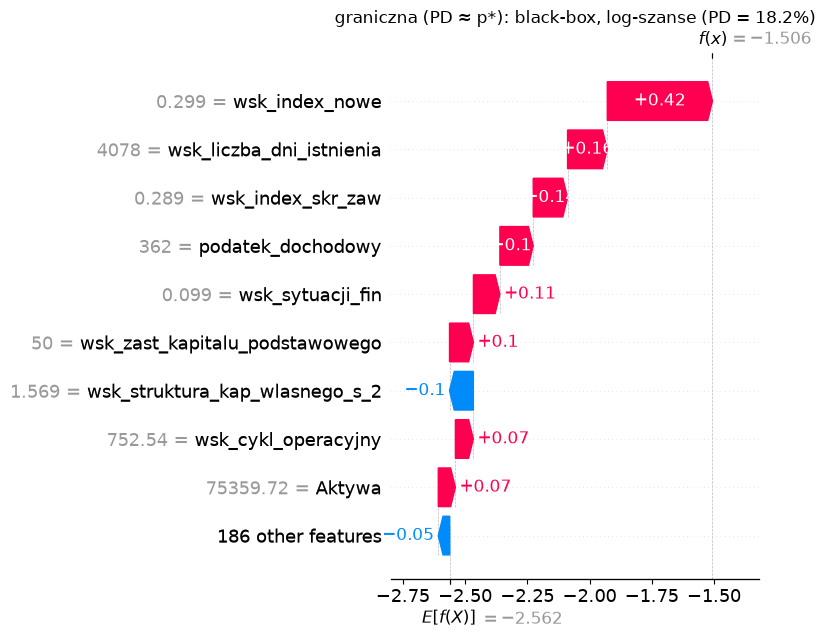

Sześć największych wkładów SHAP black-boxa:


,wartość,SHAP,mnożnik szans e^φ,kierunek
wsk_index_nowe,0.298858,0.423,1.53,podnosi ryzyko
wsk_liczba_dni_istnienia,4078.000000,0.160,1.17,podnosi ryzyko
wsk_index_skr_zaw,0.288732,0.138,1.15,podnosi ryzyko
podatek_dochodowy,362.000000,0.134,1.14,podnosi ryzyko
wsk_sytuacji_fin,0.099198,0.106,1.11,podnosi ryzyko
wsk_zast_kapitalu_podstawowego,50.000000,0.096,1.10,podnosi ryzyko


Punkty karty i różnica względem maksimum dla każdej cechy:


,wartość,punkty,utracone vs maksimum,SHAP karty
wsk_index_nowe,0.298858,61.6,33.3,0.399
podatek_dochodowy,362.0,63.0,25.0,0.223
Kapital_wlasny,68458.52,65.8,13.6,0.099
pozostale_przychody_oper,0.0,64.5,6.3,0.109
wsk_stopa_zysku_sprzedaz,0.022045,70.3,5.3,-0.074
wsk_zysk_zobowiazania,0.015147,66.3,4.5,0.044
wsk_sytuacji_fin,0.099198,66.1,4.0,0.051
wsk_ogolnego_zadluzenia_1,0.091577,73.5,0.0,-0.156



=== firma o medianowym PD: wiersz 449, PD black-box 7.2%, PD karta 9.1%, default = 0 ===


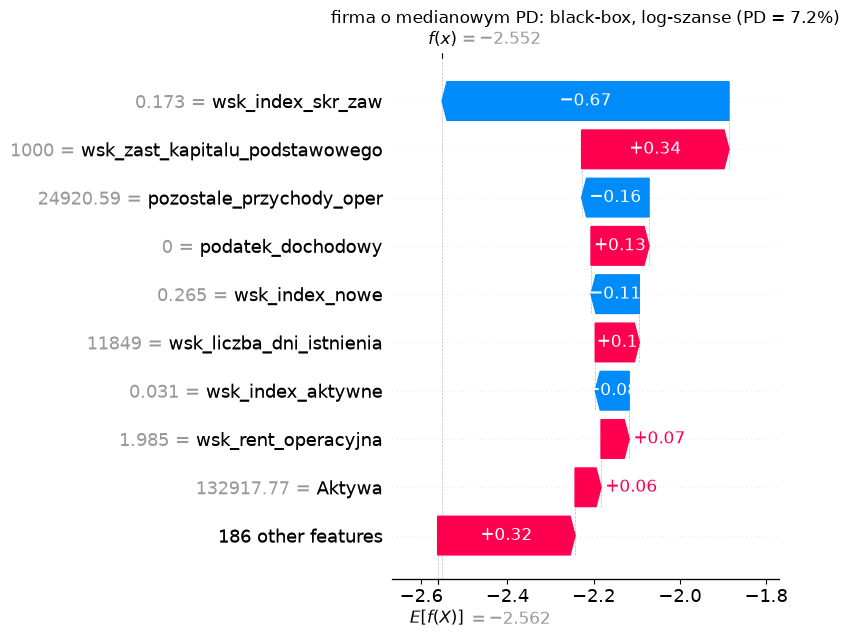

Sześć największych wkładów SHAP black-boxa:


,wartość,SHAP,mnożnik szans e^φ,kierunek
wsk_index_skr_zaw,0.173228,-0.666,0.51,obniża ryzyko
wsk_zast_kapitalu_podstawowego,1000.000000,0.342,1.41,podnosi ryzyko
pozostale_przychody_oper,24920.590000,-0.156,0.86,obniża ryzyko
podatek_dochodowy,0.000000,0.135,1.14,podnosi ryzyko
wsk_index_nowe,0.264516,-0.112,0.89,obniża ryzyko
wsk_liczba_dni_istnienia,11849.000000,0.102,1.11,podnosi ryzyko


Punkty karty i różnica względem maksimum dla każdej cechy:


,wartość,punkty,utracone vs maksimum,SHAP karty
podatek_dochodowy,0.0,61.2,26.7,0.282
wsk_index_nowe,0.264516,78.5,16.4,-0.187
wsk_stopa_zysku_sprzedaz,-0.141376,65.9,9.7,0.078
Kapital_wlasny,120885.11,71.0,8.4,-0.082
wsk_zysk_zobowiazania,0.0,66.3,4.5,0.044
wsk_sytuacji_fin,0.100464,66.1,4.0,0.051
wsk_ogolnego_zadluzenia_1,0.090527,73.5,0.0,-0.156
pozostale_przychody_oper,24920.59,70.9,0.0,-0.111



=== niezgodność modeli: wiersz 3, PD black-box 22.5%, PD karta 3.4%, default = 1 ===


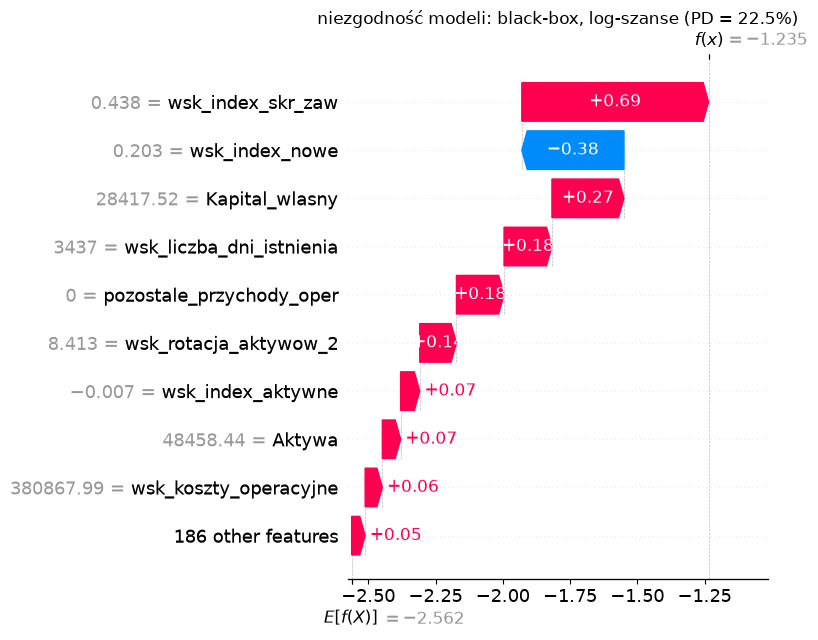

Sześć największych wkładów SHAP black-boxa:


,wartość,SHAP,mnożnik szans e^φ,kierunek
wsk_index_skr_zaw,0.438181,0.694,2.00,podnosi ryzyko
wsk_index_nowe,0.202669,-0.380,0.68,obniża ryzyko
Kapital_wlasny,28417.520000,0.268,1.31,podnosi ryzyko
wsk_liczba_dni_istnienia,3437.000000,0.178,1.19,podnosi ryzyko
pozostale_przychody_oper,0.000000,0.177,1.19,podnosi ryzyko
wsk_rotacja_aktywow_2,8.413057,0.136,1.15,podnosi ryzyko


Punkty karty i różnica względem maksimum dla każdej cechy:


,wartość,punkty,utracone vs maksimum,SHAP karty
Kapital_wlasny,28417.52,61.0,18.4,0.264
podatek_dochodowy,2413.0,77.7,10.2,-0.289
pozostale_przychody_oper,0.0,64.5,6.3,0.109
wsk_zysk_zobowiazania,0.0,66.3,4.5,0.044
wsk_index_nowe,0.202669,94.9,0.0,-0.757
wsk_ogolnego_zadluzenia_1,0.150557,73.5,0.0,-0.156
wsk_stopa_zysku_sprzedaz,0.065776,75.6,0.0,-0.259
wsk_sytuacji_fin,74.73162,70.0,0.0,-0.087


In [72]:
p_star = MARGIN / (MARGIN + LGD)
pd_bb_te, pd_lg_te = P["black-box"]["test"], P["logit"]["test"]
rangi_bb, rangi_lg = pd.Series(pd_bb_te).rank(pct=True), pd.Series(pd_lg_te).rank(pct=True)
PRZYPADKI = {"najwyższe PD": int(np.argmax(pd_bb_te)),
             "graniczna (PD ≈ p*)": int(np.argmin(np.abs(pd_bb_te - p_star))),
             "firma o medianowym PD": int(np.argmin(np.abs(pd_bb_te - np.median(pd_bb_te)))),
             "niezgodność modeli": int((rangi_bb - rangi_lg).abs().idxmax())}
print(f"Wybrane firmy na teście (surowe PD; próg p* = {p_star:.5f}, czyli {p_star:.3%}):")
display(pd.DataFrame([{"przypadek": nazwa, "wiersz testu": i, "PD black-box": pd_bb_te[i], "PD karta": pd_lg_te[i],
                       "punkty karty": wynik_model[i], "default (fakt)": y_te[i]} for nazwa, i in PRZYPADKI.items()])
        .set_index("przypadek").round({"PD black-box": 5, "PD karta": 5, "punkty karty": 1}))

def powody(i, n=10):
    s = pd.Series(PHI_BB[i], index=FEATURES)
    s = s.reindex(s.abs().sort_values(ascending=False).index)[:n]
    return pd.DataFrame({"wartość": [XS.loc[i, c] for c in s.index], "SHAP": s.round(3).to_numpy(),
                         "mnożnik szans e^φ": np.exp(s).round(2).to_numpy(),
                         "kierunek": np.where(s > 0, "podnosi ryzyko", "obniża ryzyko")}, index=s.index)

def punkty_vs_max(i):
    pk = punkty_firmy(X_te.iloc[[i]]).iloc[0]
    maks = karta_pkt.groupby("cecha")["punkty"].max()
    return pd.DataFrame({"wartość": X_te.iloc[i][CECHY_L], "punkty": pk.round(1), "utracone vs maksimum": (maks[CECHY_L] - pk).round(1),
                         "SHAP karty": PHI_LOG.iloc[i].round(3)}).sort_values("utracone vs maksimum", ascending=False)

for nazwa, i in PRZYPADKI.items():
    print(f"\n=== {nazwa}: wiersz {i}, PD black-box {pd_bb_te[i]:.1%}, PD karta {pd_lg_te[i]:.1%}, default = {y_te[i]} ===")
    shap.plots.waterfall(shap.Explanation(values=PHI_BB[i], base_values=BAZA_BB, data=XS.iloc[i].to_numpy(dtype=object),
                                          feature_names=FEATURES), max_display=10, show=False)
    plt.title(f"{nazwa}: black-box, log-szanse (PD = {pd_bb_te[i]:.1%})"); plt.tight_layout()
    plt.savefig(f"wykresy/waterfall_{list(PRZYPADKI).index(nazwa) + 1}.png", dpi=110, bbox_inches="tight"); plt.show()
    print("Sześć największych wkładów SHAP black-boxa:")
    display(powody(i, 6))
    print("Punkty karty i różnica względem maksimum dla każdej cechy:")
    display(punkty_vs_max(i))

**Wnioski z przypadków:**
- **Najwyższe PD:** black-box 80,3%, karta 68,2%, 465,2 pkt; default nie wystąpił. Największe dodatnie wkłady
  SHAP black-boxa mają `wsk_index_nowe` (+0,727) i `wsk_index_skr_zaw` (+0,526).
- **Graniczna:** surowe PD black-boxa 18,153% jest nieco poniżej p* = 18,182%; karta wskazuje 17,9%,
  a default nie wystąpił. Największy wkład SHAP ma `wsk_index_nowe` (+0,423).
- **Firma o medianowym PD:** black-box wskazuje 7,2%, karta 9,1%; default nie wystąpił. `wsk_index_skr_zaw`
  obniża wynik względem tła (SHAP −0,666), a `wsk_zast_kapitalu_podstawowego` go podnosi (+0,342).
- **Niezgodność modeli:** black-box wskazuje 22,5%, karta 3,4%; default wystąpił. W black-boxie
  `wsk_index_skr_zaw` ma dodatni wkład (+0,694), a `wsk_index_nowe` ujemny (−0,380).
  Jeden przypadek nie rozstrzyga, który model jest ogólnie lepszy.

### 9.1 LIME (kilka obserwacji)

`LimeTabularExplainer` przybliża surowe PD black-boxa lokalnym modelem liniowym, z próbkowaniem wokół firmy
i bez dyskretyzacji. Cechy liczbowe są standaryzowane. Braki uzupełniamy medianą z train, a wartości przycinamy
do 1–99 percentyla train. Dlatego firma po przygotowaniu danych może różnić się od oryginalnej.

Wykres pokazuje współczynniki modelu LIME oraz jego lokalne R². Porównujemy PD oryginalnej firmy, PD po
przygotowaniu dla LIME i przewidywanie lokalnego modelu. R² dotyczy wygenerowanego sąsiedztwa firmy.
LIME wyjaśnia PD przed dostosowaniem do 4% (11.4).

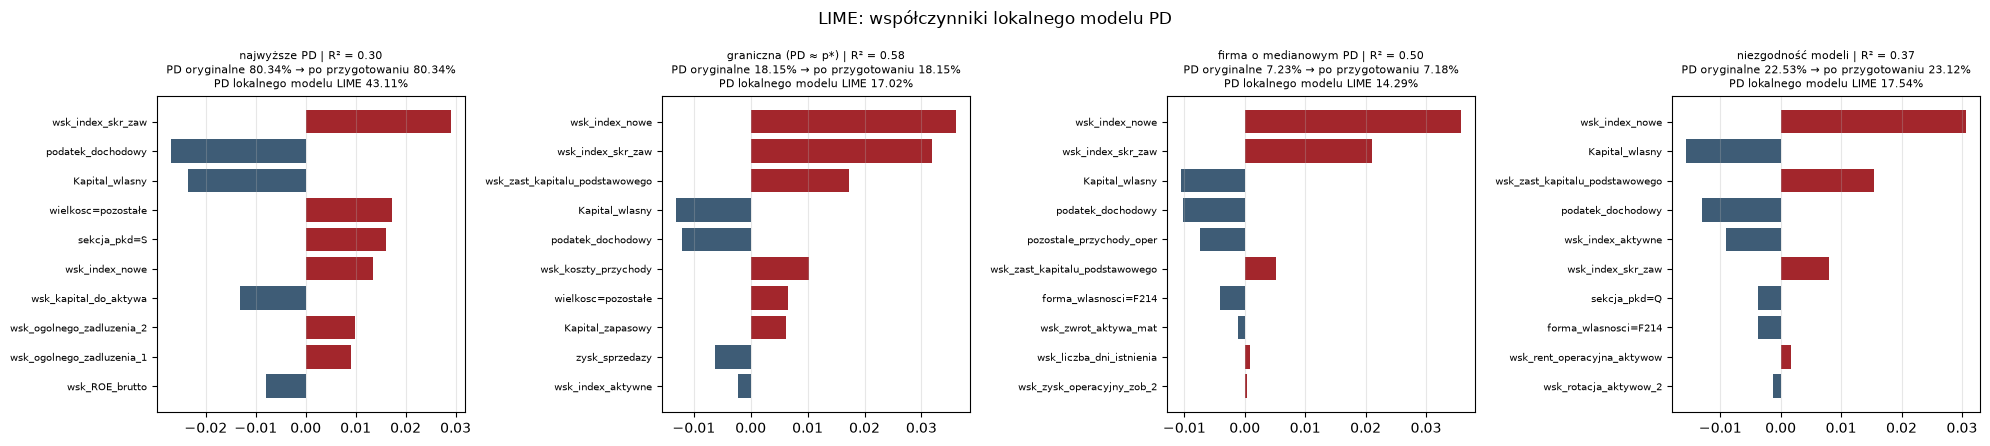

In [ ]:
from lime.lime_tabular import LimeTabularExplainer

granice_lime = X_tr[num_cols].quantile([0.01, 0.99])
mediany_lime = X_tr[num_cols].median()
kat_wartosci = {c: sorted(X_tr[c].unique()) for c in cat_cols}

def do_lime(Xw):
    # DataFrame -> macierz LIME: braki = mediana, przycięcie 1-99%, kategorie jako kody całkowite
    A = Xw[num_cols].fillna(mediany_lime).clip(granice_lime.loc[0.01], granice_lime.loc[0.99], axis=1)
    B = pd.DataFrame({c: Xw[c].map({v: k for k, v in enumerate(kat_wartosci[c])}).fillna(0) for c in cat_cols}, index=Xw.index)
    return pd.concat([A, B], axis=1)[FEATURES].to_numpy(dtype=float)

def z_lime(M):
    # macierz LIME -> DataFrame dla black-boxa
    D = pd.DataFrame(M, columns=FEATURES)
    for c in cat_cols:
        D[c] = [kat_wartosci[c][int(round(v))] for v in D[c]]
    return D

def f_lime(M):
    return black_box.predict_proba(z_lime(M))

L_TR, L_TE = do_lime(X_tr), do_lime(X_te)
idx_kat = [FEATURES.index(c) for c in cat_cols]

def lime_explainer(seed, kernel_width=None):
    return LimeTabularExplainer(L_TR, feature_names=FEATURES, categorical_features=idx_kat,
                                categorical_names={FEATURES.index(c): kat_wartosci[c] for c in cat_cols}, class_names=["brak", "default"],
                                discretize_continuous=False, sample_around_instance=True, kernel_width=kernel_width, random_state=seed)

def lime_wyjasnij(i, seed=RNG_SEED, num_samples=5000, kernel_width=None, num_features=10):   # z Lab 6 (5), zmienione ustawienia - opis wyżej
    return lime_explainer(seed, kernel_width).explain_instance(L_TE[i], f_lime, num_features=num_features, num_samples=num_samples)

LIME = {}
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (nazwa, i) in zip(axes, PRZYPADKI.items()):
    e = lime_wyjasnij(i); LIME[nazwa] = e
    lst = sorted(e.as_list(), key=lambda t: abs(t[1]))
    ax.barh([a for a, _ in lst], [b for _, b in lst], color=[KOL["test"] if b > 0 else KOL["train"] for _, b in lst])
    ax.set_title(f"{nazwa} | R² = {e.score:.2f}\nPD oryginalne {pd_bb_te[i]:.2%} → po przygotowaniu {f_lime(L_TE[[i]])[0, 1]:.2%}"
                 f"\nPD lokalnego modelu LIME {e.local_pred[0]:.2%}", fontsize=8)
    ax.tick_params(axis="y", labelsize=7); ax.grid(axis="x", alpha=0.3)
plt.suptitle("LIME: współczynniki lokalnego modelu PD"); plt.tight_layout(); plt.savefig("wykresy/lime_przypadki.png", dpi=110); plt.show()

**Wnioski 9.1:** lokalne R² wynosi od 0,30 do 0,58. Dla firmy z najwyższym PD model wskazuje 80,3%,
a przybliżenie LIME 43,1%. W przypadku niezgodności modeli PD black-boxa zmienia się z 22,5% do 23,1%
po przygotowaniu danych dla LIME. Interpretując wyjaśnienia, trzeba uwzględnić te różnice.

### 9.2 Zgodność wyjaśnień lokalnych: SHAP, LIME i karta

Porównujemy zbiory pięciu najważniejszych cech SHAP i LIME za pomocą indeksu Jaccarda. Tabela pokazuje też
trzy najważniejsze cechy każdej metody oraz trzy największe różnice punktów karty względem maksimum.
SHAP opisuje wkłady względem tła, a LIME - współczynniki lokalnego modelu; ich znaki i wartości nie oznaczają
tego samego. Punkty karty również mają inną interpretację.

In [ ]:
def top_k(seria, k=5):
    return set(seria.abs().sort_values(ascending=False).index[:k])

wiersze = []
for nazwa, i in PRZYPADKI.items():
    s_shap = pd.Series(PHI_BB[i], index=FEATURES)
    s_lime = pd.Series({FEATURES[j]: w for j, w in LIME[nazwa].local_exp[1]})
    wspolne = top_k(s_shap, 10) & set(s_lime.index)
    wiersze.append({"przypadek": nazwa, "Jaccard top-5 SHAP vs LIME": len(top_k(s_shap) & top_k(s_lime)) / len(top_k(s_shap) | top_k(s_lime)),
                    "wspólne cechy (top-10 SHAP ∩ LIME)": len(wspolne),
                    "top-3 SHAP": ", ".join(s_shap.abs().sort_values(ascending=False).index[:3]),
                    "top-3 LIME": ", ".join(s_lime.abs().sort_values(ascending=False).index[:3]),
                    "top-3 karta (utracone pkt)": ", ".join(punkty_vs_max(i).index[:3])})
print("Porównanie najważniejszych cech SHAP, LIME i karty:")
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(wiersze).set_index("przypadek").round(3))

Porównanie najważniejszych cech SHAP, LIME i karty:


,Jaccard top-5 SHAP vs LIME,wspólne cechy (top-10 SHAP ∩ LIME),top-3 SHAP,top-3 LIME,top-3 karta (utracone pkt)
przypadek,,,,,
najwyższe PD,0.250,8,"wsk_index_nowe, wsk_index_skr_zaw, Kapital_wlasny","wsk_index_skr_zaw, podatek_dochodowy, Kapital_wlasny","wsk_index_nowe, wsk_ogolnego_zadluzenia_1, podatek_dochodowy"
graniczna (PD ≈ p*),0.429,4,"wsk_index_nowe, wsk_liczba_dni_istnienia, wsk_index_skr_zaw","wsk_index_nowe, wsk_index_skr_zaw, wsk_zast_kapitalu_podstawowego","wsk_index_nowe, podatek_dochodowy, Kapital_wlasny"
firma o medianowym PD,0.667,6,"wsk_index_skr_zaw, wsk_zast_kapitalu_podstawowego, pozostale_przychody_oper","wsk_index_nowe, wsk_index_skr_zaw, Kapital_wlasny","podatek_dochodowy, wsk_index_nowe, wsk_stopa_zysku_sprzedaz"
niezgodność modeli,0.250,5,"wsk_index_skr_zaw, wsk_index_nowe, Kapital_wlasny","wsk_index_nowe, Kapital_wlasny, wsk_zast_kapitalu_podstawowego","Kapital_wlasny, podatek_dochodowy, pozostale_przychody_oper"


**Wnioski:** Jaccard top-5 SHAP i LIME wynosi 0,25 dla firmy z najwyższym PD, 0,43 dla granicznej,
0,67 dla firmy o medianowym PD i 0,25 dla przypadku niezgodności modeli. Rankingi częściowo się pokrywają,
ale metody wyjaśniają model w różny sposób. Przygotowanie danych dla LIME także może zmienić ocenianą firmę.
Wierność i stabilność wyjaśnień sprawdzamy w sekcji 10.

### 9.3 „What-if”: jak zmienia się PD przy zmianie jednej cechy

Dla firmy granicznej zmieniamy kolejno cztery najważniejsze cechy liczbowe według SHAP na wartości z siatki
kwantyli train, pozostawiając pozostałe bez zmian. Pokazujemy surowe PD black-boxa, próg p* oraz rzeczywistą
wartość cechy i PD firmy. Oś podatku ma skalę symlog, liniową w zakresie ±1000.

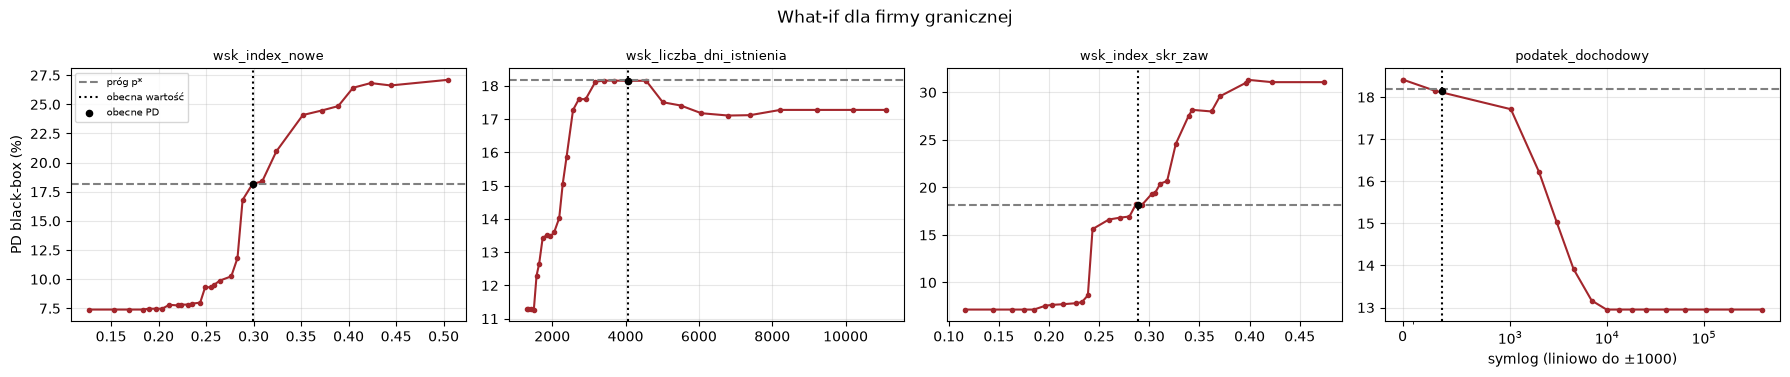

In [ ]:
i_gr = PRZYPADKI["graniczna (PD ≈ p*)"]
cechy_wi = [c for c in powody(i_gr, 10).index if c in num_cols][:4]
pd_biezace = black_box.predict_proba(XS.iloc[[i_gr]])[0, 1]
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, c in zip(axes, cechy_wi):
    s = siatka_kwantyli(c, n=30)
    p_wi = black_box.predict_proba(pd.concat([XS.iloc[[i_gr]].assign(**{c: v}) for v in s]))[:, 1]
    ax.plot(s, 100 * p_wi, "o-", ms=3, color=KOL["black-box"])
    ax.axhline(100 * p_star, ls="--", color="gray", label="próg p*")
    ax.axvline(XS.loc[i_gr, c], ls=":", color="black", label="obecna wartość")
    ax.scatter(XS.loc[i_gr, c], 100 * pd_biezace, color="black", s=20, zorder=3, label="obecne PD")
    if c == "podatek_dochodowy":
        ax.set_xscale("symlog", linthresh=1000)
        ax.set_xticks([v for v in ax.get_xticks() if v == 0 or abs(v) >= 1000])
        ax.set_xlabel("symlog (liniowo do ±1000)")
    ax.set_title(c, fontsize=9); ax.grid(alpha=0.3)
axes[0].set_ylabel("PD black-box (%)"); axes[0].legend(fontsize=7)
plt.suptitle("What-if dla firmy granicznej"); plt.tight_layout(); plt.savefig("wykresy/what_if.png", dpi=110); plt.show()

**Wnioski:** obecne surowe PD firmy wynosi 18,15%. Na badanych siatkach PD zmienia się od 7,4% do 27,1%
dla `wsk_index_nowe`, od 7,2% do 31,3% dla `wsk_index_skr_zaw`, od 11,3% do 18,2% dla wieku firmy
i od 13,0% do 18,4% dla podatku. To reakcje modelu na osobną zmianę każdej cechy, a nie prognoza skutków
rzeczywistej decyzji: powiązane wskaźniki mogą zmieniać się jednocześnie (sekcja 13).

## 10. Wierność i stabilność wyjaśnień

### 10.1 Wierność SHAP

Suma wartości SHAP i bazy odtwarza log-szanse modelu (7.1). Dodatkowo sprawdzamy, jak zmienia się wynik po zastąpieniu
k najważniejszych cech według |SHAP|. Dla 100 losowych firm porównujemy średnią bezwzględną zmianę log-szans
z wynikiem po zastąpieniu k losowych cech. Używamy mediany train dla cech liczbowych i dominanty dla kategorii;
nie jest to ta sama próba tła, której użyto do obliczenia SHAP.

In [84]:
mediany_bb = X_tr[num_cols].median()
def usun_cechy(i, cechy):
    x = XS.iloc[[i]].copy()
    for c in cechy:
        x[c] = mediany_bb[c] if c in num_cols else X_tr[c].mode()[0]
    return f_bb(x)[0]

rng_u = np.random.default_rng(RNG_SEED)
proba_u = rng_u.choice(len(XS), 100, replace=False)
wiersze = []
for k in [1, 3, 5, 10]:
    d_shap, d_los = [], []
    for i in proba_u:
        f0 = f_bb(XS.iloc[[i]])[0]
        top = pd.Series(np.abs(PHI_BB[i]), index=FEATURES).sort_values(ascending=False).index[:k]
        d_shap.append(abs(usun_cechy(i, top) - f0))
        d_los.append(abs(usun_cechy(i, rng_u.choice(FEATURES, k, replace=False)) - f0))
    wiersze.append({"k usuniętych cech": k, "średnia |zmiana log-szans|: top-k SHAP": np.mean(d_shap),
                    "średnia |zmiana log-szans|: k losowych": np.mean(d_los)})
print("Średnia bezwzględna zmiana log-szans po zastąpieniu cech:")
display(pd.DataFrame(wiersze).set_index("k usuniętych cech").round(3))

Średnia bezwzględna zmiana log-szans po zastąpieniu cech:


,średnia |zmiana log-szans|: top-k SHAP,średnia |zmiana log-szans|: k losowych
k usuniętych cech,,
1,0.648,0.020
3,0.854,0.077
5,0.909,0.109
10,0.993,0.119


**Wnioski:** dla jednej cechy średnia zmiana log-szans wynosi 0,648 według rankingu SHAP i 0,020 dla losowej cechy;
dla 10 cech odpowiednio 0,993 i 0,119. Na tej próbie zastąpienie cech wskazanych przez SHAP silniej zmienia wynik modelu.
Test opisuje reakcję na wybrany sposób zastąpienia cech, ale sam nie dowodzi pełnej wierności wyjaśnienia.

### 10.2 Wierność LIME: lokalne R² i błąd aproksymacji

Dla 20 losowych firm porównujemy PD black-boxa z prognozą lokalnego modelu LIME w nowym, wygenerowanym otoczeniu.
Cechy liczbowe losujemy wokół firmy, a kategorie według częstości w train. R² ważymy jądrem LIME, natomiast MAE
(w pp PD) jest nieważony. Pokazujemy też R² LIME na jego własnych próbkach oraz różnicę PD w punkcie firmy po
przygotowaniu danych dla LIME (9.1). W tabeli są mediana i minimum dla 20 firm; minimum błędu jest najlepszym wynikiem.
Sprawdzamy wpływ szerokości jądra: węższe przypisuje większą wagę punktom bliskim firmie.

In [85]:
def wiernosc_lime(i, e, explainer, n=2000, seed=0):
    rng_f = np.random.default_rng(seed)
    x = L_TE[i]; skala, srednia = explainer.scaler.scale_, explainer.scaler.mean_
    Z = x + rng_f.normal(size=(n, len(x))) * skala
    for j in idx_kat:                                             # kategorie: losowanie według częstości z train (jak w LIME)
        wart, licz = np.unique(L_TR[:, j], return_counts=True)
        Z[:, j] = rng_f.choice(wart, n, p=licz / licz.sum())
    Zs = (Z - srednia) / skala
    for j in idx_kat:
        Zs[:, j] = (Z[:, j] == x[j]).astype(float)
    xs = (x - srednia) / skala
    for j in idx_kat:
        xs[j] = 1.0
    odl = np.sqrt(((Zs - xs) ** 2).sum(axis=1))
    szer = explainer.kernel_width if hasattr(explainer, "kernel_width") else np.sqrt(len(x)) * 0.75
    w = np.sqrt(np.exp(-(odl ** 2) / szer ** 2))
    zast = e.intercept[1] + sum(b * Zs[:, j] for j, b in e.local_exp[1])
    prawdz = f_lime(Z)[:, 1]
    r2 = 1 - np.sum(w * (prawdz - zast) ** 2) / np.sum(w * (prawdz - np.average(prawdz, weights=w)) ** 2)
    return {"R² LIME (własne próbki)": e.score, "R² ważone (nowe otoczenie)": r2, "MAE (pp PD)": 100 * np.mean(np.abs(prawdz - zast)),
            "|PD lokalne - PD modelu| w punkcie (pp)": 100 * abs(e.local_pred[0] - f_lime(L_TE[[i]])[0, 1])}

SZER_DOM = np.sqrt(len(FEATURES)) * 0.75
proba_l = np.random.default_rng(1).choice(len(XS), 20, replace=False)
wiersze = []
for mn in [0.25, 0.5, 1.0, 2.0]:
    for i in proba_l:
        ex = lime_explainer(RNG_SEED, kernel_width=SZER_DOM * mn); ex.kernel_width = SZER_DOM * mn
        e = ex.explain_instance(L_TE[i], f_lime, num_features=10, num_samples=5000)
        wiersze.append({"szerokość jądra": f"{mn} × domyślna", **wiernosc_lime(i, e, ex)})
tab_wiern = pd.DataFrame(wiersze).groupby("szerokość jądra").agg(["median", "min"])
print("Wierność LIME dla różnych szerokości jądra (20 firm):")
display(tab_wiern.round(3))

Wierność LIME dla różnych szerokości jądra (20 firm):


R² LIME (własne próbki)        R² ważone (nowe otoczenie)  \
                                 median    min                     median   
szerokość jądra                                                             
0.25 × domyślna                   0.021  0.011                     -2.773   
0.5 × domyślna                    0.463  0.079                      0.468   
1.0 × domyślna                    0.473  0.209                      0.491   
2.0 × domyślna                    0.475  0.210                      0.482   

                        MAE (pp PD)         \
                    min      median    min   
szerokość jądra                              
0.25 × domyślna -10.940       8.987  6.114   
0.5 × domyślna    0.093       3.904  1.710   
1.0 × domyślna    0.249       3.907  1.649   
2.0 × domyślna    0.249       3.907  1.651   

                |PD lokalne - PD modelu| w punkcie (pp)         
                                                 median    min  
szerokość jądra                                                 
0.25 × domyślna                                   0.071  0.033  
0.5 × domyślna                                    7.609  3.448  
1.0 × domyślna                                    8.560  3.514  
2.0 × domyślna                                    8.637  3.527

**Wnioski:**
- Przy domyślnym jądrze mediana R² wynosi 0,47 na próbkach LIME i 0,49 na nowym otoczeniu; mediana nieważonego MAE to 3,91 pp.
- W samym punkcie firmy mediana różnicy PD wynosi 8,56 pp. Wyjaśnienie może więc słabo przybliżać wynik konkretnej firmy.
- Dla jądra 0,25 × domyślna mediana błędu w punkcie spada do 0,07 pp, ale mediana R² na nowym otoczeniu wynosi −2,77.
  W osobnym sprawdzeniu tego losowania sam punkt firmy otrzymywał medianowo około 99% łącznej wagi próbek LIME.
  Dobre dopasowanie w punkcie nie oznacza dobrego przybliżenia w jego otoczeniu.

### 10.3 Stabilność LIME: te same firmy, różne ziarna losowania

Dla każdego przypadku z sekcji 9: 10 uruchomień LIME z różnymi ziarnami, dla 1 000, 5 000 i 20 000 próbek.
Miary to średni Jaccard top-5 i średnia korelacja Spearmana współczynników między parami uruchomień. Przy porównaniu
współczynników cechom niewybranym w danym uruchomieniu przypisujemy zero. Model black-box pozostaje ten sam,
a zmieniamy tylko ziarno losowania próbek LIME.

In [86]:
def stabilnosc_lime(i, num_samples, n_seed=10):              # z Lab 6 (5), 10 ziaren zamiast 5
    wagi = []
    for s in range(n_seed):
        e = lime_wyjasnij(i, seed=s, num_samples=num_samples)
        wagi.append(pd.Series({FEATURES[j]: w for j, w in e.local_exp[1]}))
    jac, rho = [], []
    for a, b in itertools.combinations(range(n_seed), 2):
        ta, tb = top_k(wagi[a]), top_k(wagi[b]); jac.append(len(ta & tb) / len(ta | tb))
        u = wagi[a].index.union(wagi[b].index)
        rho.append(spearmanr(wagi[a].reindex(u).fillna(0), wagi[b].reindex(u).fillna(0))[0])
    return np.mean(jac), np.mean(rho)

wiersze = []
for nazwa, i in PRZYPADKI.items():
    for ns in [1000, 5000, 20000]:
        j_, r_ = stabilnosc_lime(i, ns)
        wiersze.append({"przypadek": nazwa, "liczba próbek": ns, "Jaccard top-5": j_, "Spearman wag": r_})
tab_stab_lime = pd.DataFrame(wiersze).pivot(index="przypadek", columns="liczba próbek")
print("Stabilność LIME przy różnych liczbach próbek:")
display(tab_stab_lime.round(3))

Stabilność LIME przy różnych liczbach próbek:


Jaccard top-5               Spearman wag              
liczba próbek                 1000   5000   20000        1000   5000   20000
przypadek                                                                   
firma o medianowym PD         0.696  0.881  1.000        0.762  0.882  0.957
graniczna (PD ≈ p*)           0.780  1.000  1.000        0.822  0.928  0.966
najwyższe PD                  0.640  0.553  0.729        0.905  0.862  0.959
niezgodność modeli            0.624  0.933  0.785        0.710  0.873  0.936

**Wnioski:** większa liczba próbek często poprawia stabilność, ale nie zawsze. Dla firmy z najwyższym PD Jaccard top-5
wynosi 0,64, 0,55 i 0,73 kolejno dla 1 000, 5 000 i 20 000 próbek. W tych porównaniach zmieniamy losowanie LIME,
nie model. Stabilne wyjaśnienie nadal może słabo przybliżać model (10.2).

### 10.4 Stabilność rankingów ważności (SHAP) przy zmianie danych uczących

Uczymy oba modele na każdym z 5 podzbiorów treningowych CV i porównujemy rankingi średniego |SHAP| na tym samym teście.
Dla black-boxa używamy tej samej próby tła z train; w karcie ponownie dopasowujemy binning, WoE i β oraz wyznaczamy
tło WoE z danego podzbioru. Porównujemy Jaccard top-k oraz Spearmana rang między parami foldów. Dla grup black-boxa
używamy ośmiu grup powiązanych z cechami karty z 7.3, bez grupy „pozostałe cechy”.

In [87]:
rank_bb, rank_lg = [], []
for a, b in FOLDY:
    m = model_black_box(**PARAM_BB).fit(X_tr.iloc[a], y_tr[a])
    pre_f, clf_f = m.named_steps["pre"], m.named_steps["clf"]
    G_f = np.array([[float(zrodlo(n) == f) for f in FEATURES] for n in pre_f.get_feature_names_out()])
    rank_bb.append(pd.Series(np.abs(shap.TreeExplainer(clf_f, data=pre_f.transform(X_tr.sample(300, random_state=RNG_SEED)), feature_perturbation="interventional")(pre_f.transform(X_te)).values @ G_f).mean(axis=0), index=FEATURES))
    mk = karta(CECHY_L).fit(X_tr.iloc[a][CECHY_L], y_tr[a])
    W = mk.named_steps["woe"].transform(X_te[CECHY_L]); Wt = mk.named_steps["woe"].transform(X_tr.iloc[a][CECHY_L]).mean()
    rank_lg.append(np.abs((W - Wt) * mk.named_steps["lr"].coef_.ravel()).mean())

def zgodnosc_rankingow(lista, k):
    jac, rho = [], []
    for s1, s2 in itertools.combinations(lista, 2):
        t1, t2 = set(s1.nlargest(k).index), set(s2.nlargest(k).index)
        jac.append(len(t1 & t2) / len(t1 | t2)); rho.append(spearmanr(s1, s2[s1.index])[0])
    return np.mean(jac), np.min(jac), np.mean(rho)

wiersze = []
for nazwa, lista, ks_ in [(f"black-box ({len(FEATURES)} cech)", rank_bb, [5, 10, 20]), (f"karta ({len(CECHY_L)} cech)", rank_lg, [3])]:
    for k in ks_:
        jm, jmin, r = zgodnosc_rankingow(lista, k)
        wiersze.append({"model": nazwa, "top-k": k, "Jaccard średni": jm, "Jaccard min": jmin, "Spearman rang (wszystkie cechy)": r})
print("Stabilność rankingów ważności między foldami:")
display(pd.DataFrame(wiersze).set_index(["model", "top-k"]).round(3))
grupy_bb = [pd.Series({c: s[GRUPY_TEMAT[c]].sum() for c in CECHY_L}) for s in rank_bb]
jm, jmin, r = zgodnosc_rankingow(grupy_bb, 3)
print(f"Black-box, grupy tematyczne karty (7.3): Jaccard top-3 średni {jm:.2f} (min {jmin:.2f}), Spearman rang grup {r:.2f}")

Stabilność rankingów ważności między foldami:


Jaccard średni  Jaccard min  \
model                top-k                                
black-box (195 cech) 5               0.581        0.429   
                     10              0.609        0.429   
                     20              0.517        0.429   
karta (8 cech)       3               0.600        0.500   

                            Spearman rang (wszystkie cechy)  
model                top-k                                   
black-box (195 cech) 5                                0.778  
                     10                               0.778  
                     20                               0.778  
karta (8 cech)       3                                0.826

Black-box, grupy tematyczne karty (7.3): Jaccard top-3 średni 0.70 (min 0.50), Spearman rang grup 0.89


**Wnioski:**
- Dla black-boxa średni Jaccard top-5 wynosi 0,58 (min 0,43), top-10 0,61, a korelacja rang 0,78. Rankingi zmieniają się
  między modelami uczonymi na różnych podzbiorach train. W karcie zmienia się również tło WoE.
- Dla ośmiu grup tematycznych Jaccard top-3 wynosi średnio 0,70 (min 0,50), a korelacja rang 0,89. Dla karty Jaccard top-3
  to 0,60 (min 0,50), a korelacja rang 0,83. W monitoringu (14.2) śledzimy ważność grup, uwzględniając ich zmienność.
- **Ograniczenia SHAP / LIME:** skorelowane cechy utrudniają interpretację ich osobnej ważności, a SHAP `interventional` może
  oceniać model dla nietypowych kombinacji cech. Wyjaśnienia opisują model, a nie związki przyczynowe.

## 11. Kalibracja probabilistyczna

Kolejność z Lab 3 (krok 4): **A. kalibracja statystyczna** (kształt) → **B. dostosowanie do tendencji centralnej 4%**
(poziom). Kalibratory i przesunięcie dopasowujemy na **valid** (dane niewykorzystane do uczenia modeli), test - tylko ocena.

### 11.1 Diagnostyka przed kalibracją (valid)

Krzywe porównują średnie PD z obserwowanym DR w przedziałach równolicznych. Osie krzywych są liniowe od 0 do 1%
i logarytmiczne powyżej 1%, dzięki czemu widoczne są też przedziały z zerowym DR. Składniki REL, RES i UNC liczymy
dla PD uśrednionych w przedziałach; ich suma REL − RES + UNC przybliża Brier dla oryginalnych PD.

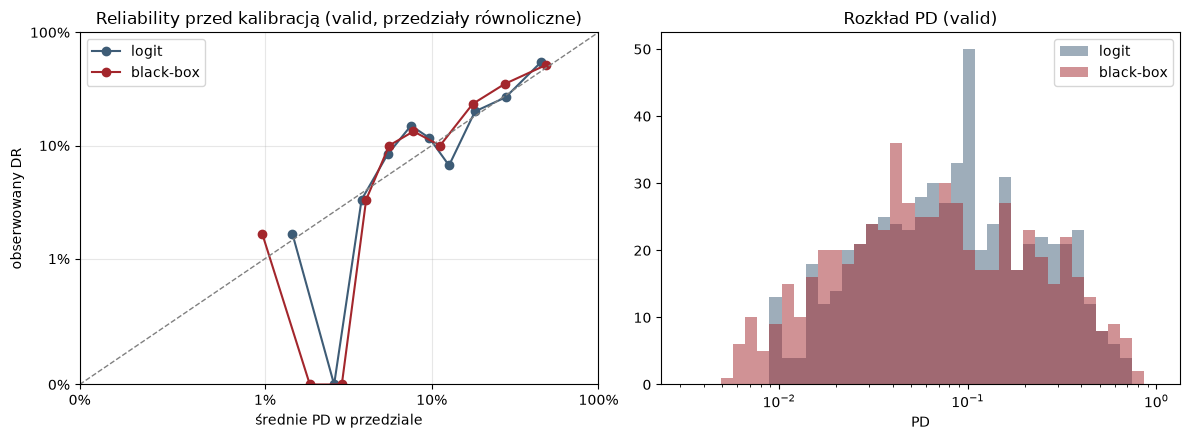

Metryki kalibracji przed dostosowaniem na valid:


,DR,średnie PD,AUC,Brier,log-loss,ECE,ACE,CITL a,slope b,rzetelność (REL),rozdzielczość (RES),niepewność (UNC)
logit,0.1483,0.1346,0.7972,0.1031,0.3402,0.0291,0.0341,0.1349,1.0578,0.0021,0.0242,0.1263
black-box,0.1483,0.1282,0.8334,0.1000,0.3240,0.0238,0.0336,0.2131,1.0440,0.0016,0.0263,0.1263


In [94]:
from sklearn.calibration import calibration_curve

def reliability(ax, y, p, label, n_bins=10, **kw):           # z Lab 3
    obs, pred = calibration_curve(y, p, n_bins=n_bins, strategy="quantile")
    ax.plot(pred, obs, "o-", label=label, **kw)

def os_kalibracji(ax):
    ax.plot([0, 1], [0, 1], "--", color="gray", lw=1)
    ax.set_xscale("symlog", linthresh=0.01); ax.set_yscale("symlog", linthresh=0.01)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xticks([0, 0.01, 0.1, 1], ["0%", "1%", "10%", "100%"])
    ax.set_yticks([0, 0.01, 0.1, 1], ["0%", "1%", "10%", "100%"])
    ax.set_xlabel("średnie PD w przedziale"); ax.set_ylabel("obserwowany DR"); ax.grid(alpha=0.3, which="both")

def murphy(y, p, n_bins=10):                                  # z Lab 2 - dekompozycja Briera
    edges = np.unique(np.quantile(p, np.linspace(0, 1, n_bins + 1)))
    idx = np.clip(np.digitize(p, edges[1:-1], right=True), 0, len(edges) - 2)
    o = y.mean(); rel = res = 0.0
    for m in range(len(edges) - 1):
        msk = idx == m
        if msk.any():
            w = msk.mean(); rel += w * (p[msk].mean() - y[msk].mean()) ** 2; res += w * (y[msk].mean() - o) ** 2
    return {"rzetelność (REL)": rel, "rozdzielczość (RES)": res, "niepewność (UNC)": o * (1 - o)}

KOL_KAL = ["DR", "średnie PD", "AUC", "Brier", "log-loss", "ECE", "ACE", "CITL a", "slope b"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for m in ["logit", "black-box"]:
    reliability(axes[0], y_va, P[m]["valid"], m, color=KOL[m])
    axes[1].hist(P[m]["valid"], bins=np.logspace(-2.5, 0, 40), alpha=0.5, label=m, color=KOL[m])
os_kalibracji(axes[0]); axes[0].set_title("Reliability przed kalibracją (valid, przedziały równoliczne)"); axes[0].legend()
axes[1].set_xscale("log"); axes[1].set_xlabel("PD"); axes[1].set_title("Rozkład PD (valid)"); axes[1].legend()
plt.tight_layout(); plt.savefig("wykresy/kalibracja_przed.png", dpi=120); plt.show()
print("Metryki kalibracji przed dostosowaniem na valid:")
display(pd.concat([pd.DataFrame({m: metryki(y_va, P[m]["valid"]) for m in ["logit", "black-box"]}).T[KOL_KAL],
                   pd.DataFrame({m: murphy(y_va, P[m]["valid"]) for m in ["logit", "black-box"]}).T], axis=1).round(4))

**Wnioski:** na valid średnie PD wynosi 13,46% dla karty i 12,82% dla black-boxa przy DR 14,83%.
Dodatni CITL (odpowiednio 0,135 i 0,213) wskazuje na zaniżenie poziomu PD względem tej próby;
nachylenia wynoszą 1,06 i 1,04. Modele uczono bez wag klas i oversamplingu, ale zgodność próby
z docelowym portfelem wymaga osobnego założenia (11.5).

### 11.2 Kształt: Platt, izotoniczna, beta - wybór walidacją krzyżową wewnątrz valid

W **5-krotnej CV wewnątrz valid** każdy kalibrator uczymy na 4/5 valid, a oceniamy na pozostałej części.
Na valid jest 89 defaultów, więc kalibracja izotoniczna może być podatna na przeuczenie. Wybieramy metodę
według log-loss; Brier pokazujemy dodatkowo.

In [95]:
from sklearn.isotonic import IsotonicRegression

def _beta_cechy(p):                                           # z Lab 3
    p = np.clip(p, EPS, 1 - EPS); return np.column_stack([np.log(p), -np.log(1 - p)])

FIT = {                                                       # z Lab 3 (4.2)
    "bez kalibracji": lambda y, p: None,
    "Platt": lambda y, p: LogisticRegression(C=1e6, max_iter=1000).fit(_z(p).reshape(-1, 1), y),
    "izotoniczna": lambda y, p: IsotonicRegression(out_of_bounds="clip", y_min=EPS, y_max=1 - EPS).fit(p, y),
    "beta": lambda y, p: LogisticRegression(C=1e6, max_iter=1000).fit(_beta_cechy(p), y),
}

def zastosuj(metoda, kal, p):                                 # z Lab 3
    if metoda == "bez kalibracji":
        return np.asarray(p)
    if metoda == "Platt":
        return kal.predict_proba(_z(p).reshape(-1, 1))[:, 1]
    if metoda == "beta":
        return kal.predict_proba(_beta_cechy(p))[:, 1]
    return kal.predict(p)

def cv_miara(metoda, y, p, k=5, miara="log-loss"):            # z Lab 3 (cv_logloss), dodany Brier
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=RNG_SEED); w = []
    for a, b in skf.split(p.reshape(-1, 1), y):
        q = np.clip(zastosuj(metoda, FIT[metoda](y[a], p[a]), p[b]), EPS, 1 - EPS)
        w.append(log_loss(y[b], q) if miara == "log-loss" else brier_score_loss(y[b], q))
    return float(np.mean(w))

wybor_kal = pd.concat({miara: pd.DataFrame({m: {met: cv_miara(met, y_va, P[m]["valid"], miara=miara) for met in FIT}
                                            for m in ["logit", "black-box"]}).T for miara in ["log-loss", "Brier"]}, axis=1)
print("Log-loss i Brier metod kalibracji w CV na valid:")
display(wybor_kal.round(5))

PROSTOTA = ["bez kalibracji", "Platt", "beta", "izotoniczna"]
METODA = {}
for m in ["logit", "black-box"]:
    ll = wybor_kal["log-loss"].loc[m]
    METODA[m] = next(met for met in PROSTOTA if ll[met] <= ll.min() + 0.001)       # najprostsza w granicy 0,001 od najlepszej
print("Wybrana metoda kształtu (najprostsza z log-loss w CV nie gorszym niż najlepszy + 0,001):", METODA)

Log-loss i Brier metod kalibracji w CV na valid:


log-loss                                        Brier  \
          bez kalibracji    Platt izotoniczna     beta bez kalibracji   
logit            0.34017  0.34441     0.40024  0.34465        0.10310   
black-box        0.32399  0.32739     0.34964  0.32803        0.09999   

                                         
             Platt izotoniczna     beta  
logit      0.10398     0.10827  0.10393  
black-box  0.10117     0.10324  0.10151

Wybrana metoda kształtu (najprostsza z log-loss w CV nie gorszym niż najlepszy + 0,001): {'logit': 'bez kalibracji', 'black-box': 'bez kalibracji'}


**Wnioski:** w CV na valid najniższy log-loss i Brier ma wariant **bez kalibracji kształtu** dla obu modeli.
Log-loss wynosi 0,340 dla karty i 0,324 dla black-boxa; dla kalibracji izotonicznej odpowiednio 0,400 i 0,350.
Wybieramy brak kalibracji kształtu. Wynik nie dowodzi jednak idealnej kalibracji modelu.

### 11.3 Walidacja po kalibracji statystycznej (test)

Porównujemy metody na teście; wybór metody wykonaliśmy wcześniej na valid.

Metryki metod kalibracji kształtu na teście:


DR  średnie PD     AUC   Brier  log-loss  \
logit     bez kalibracji  0.1486      0.1468  0.7810  0.1050    0.3499   
          Platt           0.1486      0.1621  0.7810  0.1054    0.3513   
          izotoniczna     0.1486      0.1645  0.7651  0.1072    0.3697   
          beta            0.1486      0.1622  0.7810  0.1053    0.3504   
black-box bez kalibracji  0.1486      0.1414  0.7915  0.1041    0.3471   
          Platt           0.1486      0.1632  0.7915  0.1057    0.3492   
          izotoniczna     0.1486      0.1648  0.7768  0.1070    0.3817   
          beta            0.1486      0.1625  0.7915  0.1063    0.3510   

                             ECE     ACE  CITL a  slope b  
logit     bez kalibracji  0.0153  0.0299  0.0167   0.9456  
          Platt           0.0288  0.0318 -0.1269   0.8938  
          izotoniczna     0.0423  0.0361 -0.1558   0.6696  
          beta            0.0247  0.0297 -0.1294   0.8956  
black-box bez kalibracji  0.0467  0.0402  0.0742   0.8321  
          Platt           0.0524  0.0471 -0.1472   0.7970  
          izotoniczna     0.0587  0.0565 -0.1711   0.5271  
          beta            0.0584  0.0470 -0.1384   0.7864

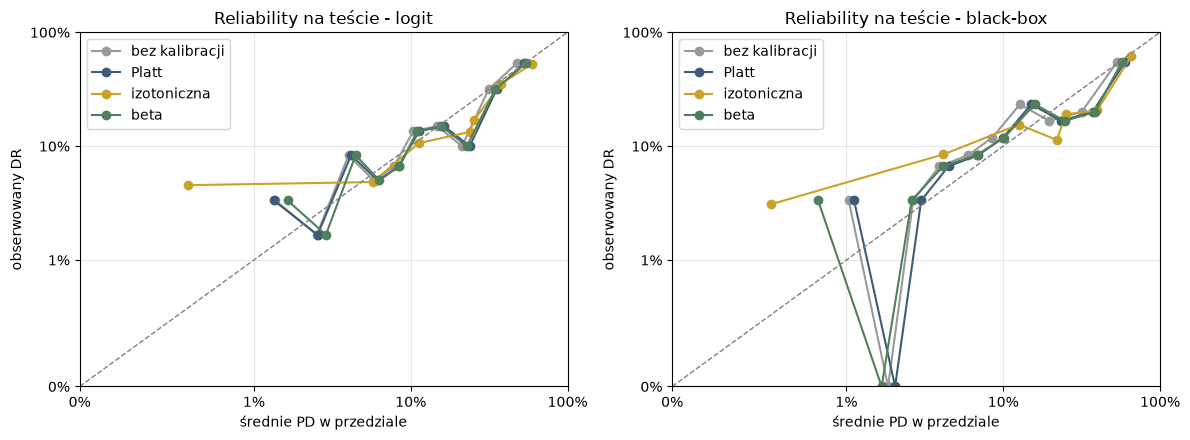

In [96]:
KAL = {m: FIT[METODA[m]](y_va, P[m]["valid"]) for m in P}
PS = {m: {s: zastosuj(METODA[m], KAL[m], P[m][s]) for s in X} for m in P}                     # po kalibracji kształtu
wiersze = {}
for m in P:
    for met in ["bez kalibracji", "Platt", "izotoniczna", "beta"]:
        kal = FIT[met](y_va, P[m]["valid"])
        wiersze[(m, met)] = metryki(y_te, zastosuj(met, kal, P[m]["test"]))
tab_kal_test = pd.DataFrame(wiersze).T[KOL_KAL]
print("Metryki metod kalibracji kształtu na teście:")
display(tab_kal_test.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, m in zip(axes, P):
    for met, kol in [("bez kalibracji", "#999999"), ("Platt", KOL["logit"]), ("izotoniczna", KOL["valid"]), ("beta", "#4F7F5C")]:
        reliability(ax, y_te, zastosuj(met, FIT[met](y_va, P[m]["valid"]), P[m]["test"]), met, color=kol)
    os_kalibracji(ax); ax.set_title(f"Reliability na teście - {m}"); ax.legend()
plt.tight_layout(); plt.savefig("wykresy/kalibracja_metody.png", dpi=120); plt.show()

**Wnioski (test):** wariant bez kalibracji kształtu ma najniższy log-loss i Brier dla obu modeli. Jego CITL wynosi
0,017 dla karty i 0,074 dla black-boxa, a nachylenie odpowiednio 0,946 i 0,832. Kalibracja izotoniczna daje
log-loss 0,370 i 0,382 oraz niższe AUC. Wyniki testu są zgodne z wyborem dokonanym na valid.

### 11.4 Dostosowanie do tendencji centralnej PD = 4%

$$\text{logit}(q) = \text{logit}(p) + \delta$$

δ wyznaczamy tak, by nieważona średnia PD na valid wyniosła 4%, i stosujemy je także na teście (Lab 3, 4.3).
4% to zewnętrzne założenie o długookresowej średniej DR docelowego portfela, a DR w naszej próbie to ok. 14,8%.
Średnia 4% na valid nie gwarantuje kalibracji PD dla rzeczywistego portfela.

In [97]:
def delta_do_sredniej(p, cel, lo=-15.0, hi=15.0, iters=100):   # z Lab 3
    z = _z(p)
    for _ in range(iters):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if expit(z + mid).mean() < cel else (lo, mid)
    return (lo + hi) / 2

DELTA = {m: delta_do_sredniej(PS[m]["valid"], TARGET_PD) for m in P}
P4 = {m: {s: expit(_z(PS[m][s]) + DELTA[m]) for s in X} for m in P}                       # po kalibracji do 4%

def pd_koncowe(Xw, m="black-box"):
    # pełny łańcuch: model -> kalibracja kształtu -> przesunięcie do 4%
    p = black_box.predict_proba(Xw)[:, 1] if m == "black-box" else baseline.predict_proba(Xw[CECHY_L])[:, 1]
    return expit(_z(zastosuj(METODA[m], KAL[m], p)) + DELTA[m])

for m in P:
    print(f"{m:9s}: kształt = {METODA[m]}, δ = {DELTA[m]:+.3f} | średnie PD na valid: {P[m]['valid'].mean():.2%} (model) -> "
          f"{PS[m]['valid'].mean():.2%} (kształt) -> {P4[m]['valid'].mean():.2%} (po δ) | DR valid {y_va.mean():.2%}")
wiersze = {}
for m in P:
    wiersze[(m, "1. model")] = metryki(y_te, P[m]["test"])
    wiersze[(m, f"2. kształt: {METODA[m]}")] = metryki(y_te, PS[m]["test"])
    wiersze[(m, "3. kształt + 4%")] = metryki(y_te, P4[m]["test"])
tab_4 = pd.DataFrame(wiersze).T[KOL_KAL + ["Gini"]]
print("Metryki na teście przed dostosowaniem i po dostosowaniu do 4%:")
display(tab_4.round(4))

logit    : kształt = bez kalibracji, δ = -1.486 | średnie PD na valid: 13.46% (model) -> 13.46% (kształt) -> 4.00% (po δ) | DR valid 14.83%
black-box: kształt = bez kalibracji, δ = -1.479 | średnie PD na valid: 12.82% (model) -> 12.82% (kształt) -> 4.00% (po δ) | DR valid 14.83%
Metryki na teście przed dostosowaniem i po dostosowaniu do 4%:


DR  średnie PD     AUC   Brier  \
logit     1. model                    0.1486      0.1468  0.7810  0.1050   
          2. kształt: bez kalibracji  0.1486      0.1468  0.7810  0.1050   
          3. kształt + 4%             0.1486      0.0444  0.7810  0.1242   
black-box 1. model                    0.1486      0.1414  0.7915  0.1041   
          2. kształt: bez kalibracji  0.1486      0.1414  0.7915  0.1041   
          3. kształt + 4%             0.1486      0.0457  0.7915  0.1212   

                                      log-loss     ECE     ACE  CITL a  \
logit     1. model                      0.3499  0.0153  0.0299  0.0167   
          2. kształt: bez kalibracji    0.3499  0.0153  0.0299  0.0167   
          3. kształt + 4%               0.4407  0.1042  0.1042  1.5029   
black-box 1. model                      0.3471  0.0467  0.0402  0.0742   
          2. kształt: bez kalibracji    0.3471  0.0467  0.0402  0.0742   
          3. kształt + 4%               0.4388  0.1029  0.1037  1.5535   

                                      slope b   Gini  
logit     1. model                     0.9456  0.562  
          2. kształt: bez kalibracji   0.9456  0.562  
          3. kształt + 4%              0.9454  0.562  
black-box 1. model                     0.8321  0.583  
          2. kształt: bez kalibracji   0.8321  0.583  
          3. kształt + 4%              0.8323  0.583

**Wnioski:**
- δ wynosi −1,486 dla karty i −1,479 dla black-boxa. Średnie PD po przesunięciu to 4,00% na valid oraz
  odpowiednio 4,44% i 4,57% na teście.
- W obecnych danych ranking się nie zmienia: Gini pozostaje na poziomie 0,562 i 0,583. Nachylenia są niemal
  niezmienione: około 0,946 i 0,832.
- Na nieważonym teście z DR 14,86% Brier rośnie z 0,105 do 0,124 dla karty i z 0,104 do 0,121 dla black-boxa.
  Porównujemy tu PD dostosowane do założonych 4% z próbą o znacznie wyższym DR.

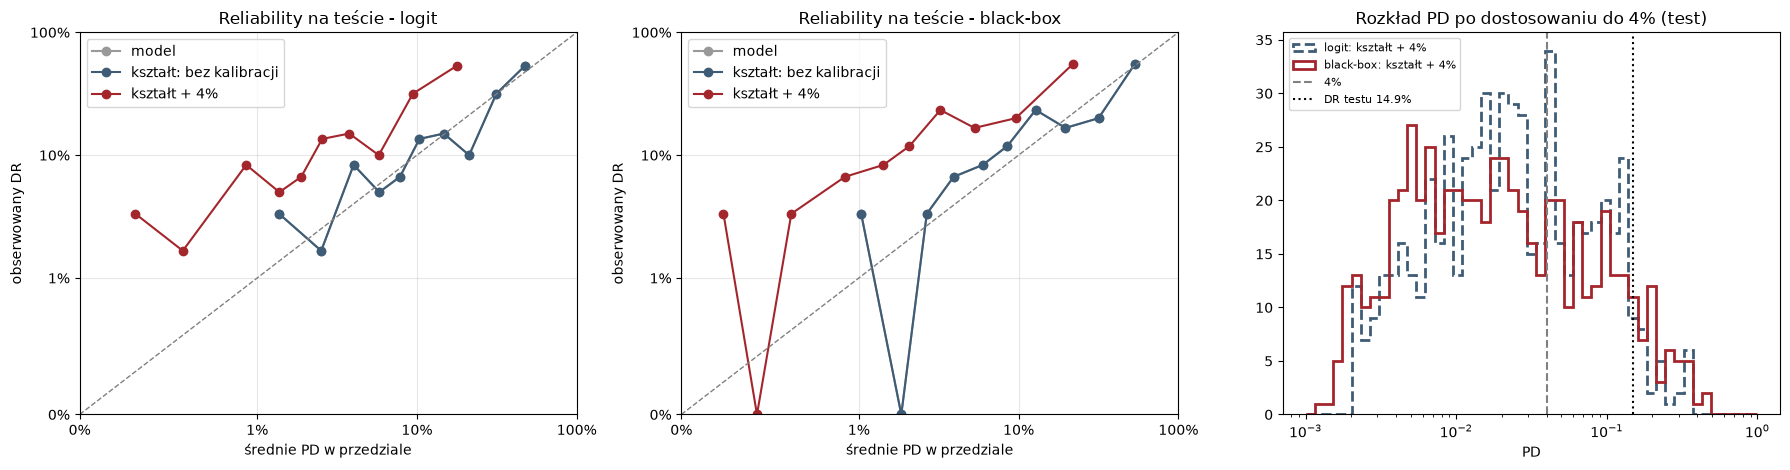

In [98]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, m in zip(axes[:2], P):
    for p, lab, col in [(P[m]["test"], "model", "#999999"), (PS[m]["test"], f"kształt: {METODA[m]}", KOL["logit"]), (P4[m]["test"], "kształt + 4%", KOL["test"])]:
        reliability(ax, y_te, p, lab, color=col)
    os_kalibracji(ax); ax.set_title(f"Reliability na teście - {m}"); ax.legend()
for m, ls in [("logit", "--"), ("black-box", "-")]:
    axes[2].hist(P4[m]["test"], bins=np.logspace(-3, 0, 50), histtype="step", lw=2, ls=ls, label=f"{m}: kształt + 4%", color=KOL[m])
axes[2].axvline(TARGET_PD, ls="--", color="gray", label="4%"); axes[2].axvline(y_te.mean(), ls=":", color="black", label=f"DR testu {y_te.mean():.1%}")
axes[2].set_xscale("log"); axes[2].set_xlabel("PD"); axes[2].set_title("Rozkład PD po dostosowaniu do 4% (test)"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.savefig("wykresy/kalibracja_4proc.png", dpi=120); plt.show()

### 11.5 Czy PD = 4% jest skalibrowane dla docelowego portfela?

δ dobrano do nieważonej średniej PD na valid, a nie według wzoru klasycznej korekty a priori. Aby sprawdzić
scenariusz portfela o DR 4%, przeważamy test według statusu firmy: waga defaultu to 0,04 / DR testu, a pozostałych
0,96 / (1 − DR testu). Ważony DR wynosi więc 4% z konstrukcji. Taki scenariusz zakłada, że rozkład cech
w każdej z dwóch klas odpowiada docelowemu portfelowi.

In [99]:
w_te = np.where(y_te == 1, TARGET_PD / y_te.mean(), (1 - TARGET_PD) / (1 - y_te.mean()))
def miary_wazone(y, p, w):
    z = _z(p)
    a = brentq(lambda d: np.average(expit(z + d), weights=w) - np.average(y, weights=w), -15, 15)
    b = LogisticRegression(C=1e6, max_iter=1000).fit(z.reshape(-1, 1), y, sample_weight=w).coef_[0, 0]
    return {"DR (ważony)": np.average(y, weights=w), "średnie PD (ważone)": np.average(p, weights=w),
            "Brier (ważony)": np.average((p - y) ** 2, weights=w), "log-loss (ważony)": log_loss(y, np.clip(p, EPS, 1 - EPS), sample_weight=w),
            "CITL a": a, "slope b": b}
print("Metryki na teście przeważonym do DR = 4%:")
display(pd.DataFrame({(m, wariant): miary_wazone(y_te, p, w_te) for m in P
                      for wariant, p in [("kształt (bez δ)", PS[m]["test"]), ("kształt + 4%", P4[m]["test"])]}).T.round(4))

Metryki na teście przeważonym do DR = 4%:


DR (ważony)  średnie PD (ważone)  Brier (ważony)  \
logit     kształt (bez δ)         0.04               0.1286          0.0498   
          kształt + 4%            0.04               0.0374          0.0357   
black-box kształt (bez δ)         0.04               0.1203          0.0499   
          kształt + 4%            0.04               0.0368          0.0353   

                           log-loss (ważony)  CITL a  slope b  
logit     kształt (bez δ)             0.1978 -1.4118   0.9711  
          kształt + 4%                0.1454  0.0744   0.9701  
black-box kształt (bez δ)             0.1915 -1.3844   0.8513  
          kształt + 4%                0.1443  0.0949   0.8538

**Wnioski:** po δ średnie PD na ważonym teście wynosi 3,74% dla karty i 3,68% dla black-boxa, przy ważonym DR 4%.
CITL wynosi odpowiednio 0,074 i 0,095, a nachylenie 0,97 i 0,85. Przed δ średnie PD wynosiło 12,86% i 12,03%.
Przeważony test jest symulacją przy przyjętym założeniu o rozkładach cech, a nie dowodem kalibracji rzeczywistego portfela.

## 12. Progi decyzyjne i mapowanie PD → rating

### 12.1 Skala główna i rozkład firm

Skala z Lab 3 ma 7 klas dla firm bez defaultu (AAA–CCC). Klasę **D** rezerwujemy dla stwierdzonego defaultu;
nie przypisujemy jej w dniu oceny. Rating wyznaczamy z PD po dostosowaniu do 4%. Dolna granica przedziału
należy do danej klasy, a górna do następnej; PD = 100% należy do CCC.

In [109]:
RATING_BINS = [0.00, 0.01, 0.02, 0.05, 0.08, 0.12, 0.20, 1.0 + 1e-9]       # z Lab 3
RATING_LABELS = ["AAA", "AA", "A", "BBB", "BB", "B", "CCC"]

def rating(p):
    return pd.Categorical(pd.cut(np.asarray(p), bins=RATING_BINS, labels=RATING_LABELS, right=False), categories=RATING_LABELS, ordered=True)

skala = pd.DataFrame({"klasa": RATING_LABELS,
                      "przedział PD": [f"{100 * RATING_BINS[k]:.0f}% ≤ PD < {100 * RATING_BINS[k + 1]:.0f}%" if k < 6 else "20% ≤ PD ≤ 100%" for k in range(7)]}).set_index("klasa")
R = {m: {s: rating(P4[m][s]) for s in X} for m in P}
HHI = {}
for m in P:
    udz = pd.Series(R[m]["test"]).value_counts(normalize=True).reindex(RATING_LABELS).fillna(0)
    skala[f"udział - {m} (test, %)"] = (100 * udz).round(1)
    HHI[m] = float((udz ** 2).sum())
print("Skala i rozkład firm w klasach na teście:")
display(skala)
for m in P:
    print(f"HHI udziałów klas ({m}, test): {HHI[m]:.3f}")

Skala i rozkład firm w klasach na teście:


,przedział PD,"udział - logit (test, %)","udział - black-box (test, %)"
klasa,,,
AAA,0% ≤ PD < 1%,27.5,37.2
AA,1% ≤ PD < 2%,20.0,17.4
A,2% ≤ PD < 5%,25.4,20.5
BBB,5% ≤ PD < 8%,8.5,7.0
BB,8% ≤ PD < 12%,9.0,7.0
B,12% ≤ PD < 20%,6.8,6.5
CCC,20% ≤ PD ≤ 100%,2.7,4.3


HHI udziałów klas (logit, test): 0.201
HHI udziałów klas (black-box, test): 0.227


**Wnioski:** do klas AAA–A trafia 73,0% firm dla karty i 75,1% dla black-boxa. Najliczniejsza jest klasa AAA:
27,5% dla karty i 37,2% dla black-boxa. Udział klasy CCC wynosi odpowiednio 2,7% i 4,3%.
HHI wynosi 0,201 i 0,227, wobec 0,143 przy równym podziale na siedem klas.

### 12.2 Backtest per klasa: monotoniczność, test Jeffreysa, światła (test)

Dla każdej klasy porównujemy średnie PD, oczekiwaną liczbę defaultów (suma PD) i faktyczny DR na nieważonym teście.
Klasy wyznaczamy według PD po δ; kolumny „przed δ” dotyczą tych samych firm w tych samych klasach.

„p Jeffreysa” to prawdopodobieństwo a posteriori, że nieznana stopa defaultu klasy nie przekracza jej średniego PD.
Światła wyznaczamy według tej wartości: zielone od 0,05, żółte od 0,01 do mniej niż 0,05, czerwone poniżej 0,01.
Osobno podajemy jednostronny wynik testu dwumianowego. Oba podejścia używają uproszczonego modelu dwumianowego
dla klasy; wyniki testów nie muszą być jednakowe.


Backtest klas (logit, test):
Czy DR rośnie między klasami: tak
Światła według Jeffreysa po δ: {'czerwone': 6, 'żółte': 1} | przed δ: {'zielone': 6, 'żółte': 1}


,n,defaulty,oczekiwane,średnie PD,DR,p Jeffreysa,p dwumianowy,światło,PD przed δ,światło przed δ
klasa,,,,,,,,,,
AAA,165,8,0.9341,0.0057,0.0485,1.749e-06,5.502e-06,czerwone,0.0245,żółte
AA,120,6,1.8107,0.0151,0.0500,0.004999,0.01003,czerwone,0.0633,zielone
A,152,20,4.9212,0.0324,0.1316,5.799e-08,1.264e-07,czerwone,0.1280,zielone
BBB,51,7,3.3189,0.0651,0.1373,0.02815,0.04622,żółte,0.2347,zielone
BB,54,18,5.3213,0.0985,0.3333,1.015e-06,2.23e-06,czerwone,0.3250,zielone
B,41,19,5.8700,0.1432,0.4634,3.916e-07,9.116e-07,czerwone,0.4236,zielone
CCC,16,11,4.4281,0.2768,0.6875,0.0003007,0.0007441,czerwone,0.6233,zielone



Backtest klas (black-box, test):
Czy DR rośnie między klasami: nie
Światła według Jeffreysa po δ: {'czerwone': 6, 'żółte': 1} | przed δ: {'zielone': 6, 'żółte': 1}


,n,defaulty,oczekiwane,średnie PD,DR,p Jeffreysa,p dwumianowy,światło,PD przed δ,światło przed δ
klasa,,,,,,,,,,
AAA,223,7,1.1436,0.0051,0.0314,6.613e-05,0.0001761,czerwone,0.0221,zielone
AA,104,8,1.5426,0.0148,0.0769,6.872e-05,0.0001706,czerwone,0.0619,zielone
A,123,23,4.0979,0.0333,0.1870,7.903e-12,2.081e-11,czerwone,0.1305,żółte
BBB,42,6,2.7411,0.0653,0.1429,0.03176,0.05377,żółte,0.2340,zielone
BB,42,10,4.1499,0.0988,0.2381,0.003767,0.006726,czerwone,0.3243,zielone
B,39,18,6.0484,0.1551,0.4615,2.743e-06,6.085e-06,czerwone,0.4437,zielone
CCC,26,17,7.6484,0.2942,0.6538,7.185e-05,0.0001572,czerwone,0.6372,zielone


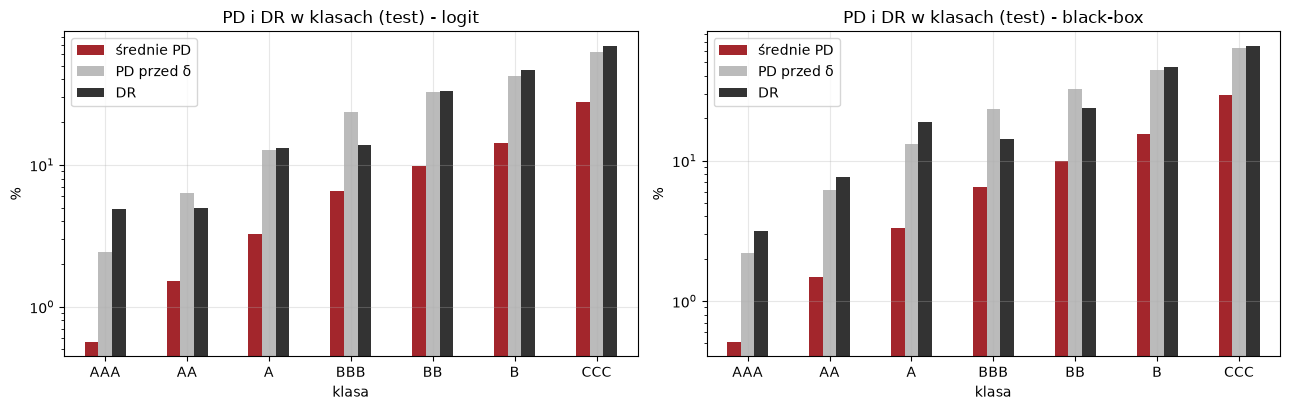

In [110]:
def swiatlo(p):                                               # z Lab 3
    return "zielone" if p >= 0.05 else ("żółte" if p >= 0.01 else "czerwone")

def backtest(y, p, r, p_kszt=None):                           # z Lab 3
    rows = []
    for lab in RATING_LABELS:
        msk = np.asarray(r == lab)
        if not msk.any():
            continue
        n_k, d_k, pd_k = int(msk.sum()), int(y[msk].sum()), float(p[msk].mean())
        pj = float(beta_dist.cdf(pd_k, d_k + 0.5, n_k - d_k + 0.5))
        w = {"klasa": lab, "n": n_k, "defaulty": d_k, "oczekiwane": n_k * pd_k, "średnie PD": pd_k, "DR": d_k / n_k,
             "p Jeffreysa": pj, "p dwumianowy": binomtest(d_k, n_k, pd_k, alternative="greater").pvalue, "światło": swiatlo(pj)}
        if p_kszt is not None:
            pk = float(p_kszt[msk].mean())
            w.update({"PD przed δ": pk, "światło przed δ": swiatlo(float(beta_dist.cdf(pk, d_k + 0.5, n_k - d_k + 0.5)))})
        rows.append(w)
    return pd.DataFrame(rows).set_index("klasa")

BT = {}
for m in P:
    BT[m] = backtest(y_te, P4[m]["test"], R[m]["test"], PS[m]["test"])
    monotoniczne = np.all(np.diff(BT[m]["DR"].to_numpy()) >= 0)
    print(f"\nBacktest klas ({m}, test):")
    print(f"Czy DR rośnie między klasami: {'tak' if monotoniczne else 'nie'}")
    print(f"Światła według Jeffreysa po δ: {BT[m]['światło'].value_counts().to_dict()} | "
          f"przed δ: {BT[m]['światło przed δ'].value_counts().to_dict()}")
    bt_wyswietl = BT[m].round(4)
    for c in ["p Jeffreysa", "p dwumianowy"]:
        bt_wyswietl[c] = BT[m][c].map(lambda p: f"{p:.4g}")
    display(bt_wyswietl)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, m in zip(axes, P):
    (100 * BT[m][["średnie PD", "PD przed δ", "DR"]]).plot.bar(ax=ax, rot=0, color=[KOL["test"], "#BBBBBB", "#333333"])
    ax.set_yscale("log"); ax.set_ylabel("%"); ax.set_title(f"PD i DR w klasach (test) - {m}"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("wykresy/backtest.png", dpi=120); plt.show()

**Wnioski:**
- DR rośnie między klasami karty: od 4,8% w AAA do 68,8% w CCC. W black-boxie A ma DR 18,7% (23/123 firm),
  a BBB 14,3% (6/42), więc występuje jedno odwrócenie. Przy niewielkich liczbach defaultów wynik jest niepewny.
- Według Jeffreysa po δ oba modele mają 6 czerwonych i jedno żółte światło (BBB). Przed δ oba mają 6 zielonych
  i jedno żółte: w AAA dla karty, w A dla black-boxa. Porównanie dotyczy tych samych klas wyznaczonych po δ.
- Testy nie zawsze wskazują ten sam poziom: dla BBB black-boxa wynik Jeffreysa to 0,0318, a dwumianowy 0,0538.
  Dostosowanie PD do 4% zmienia jego poziom względem nieważonego testu z DR 14,9%; przeważenie testu do DR 4%
  jest scenariuszem, a nie dowodem pełnej kalibracji (11.5).

### 12.3 Funkcja zysku i próg operacyjny

Brak kolumny z ekspozycją, więc przyjmujemy **jednakową ekspozycję EAD = 1** dla każdej firmy.
Ekonomia z Lab 3: przyjęty dobry klient daje zysk MARGIN = 10%, przyjęty zły - stratę LGD = 45%, odrzucenie - 0.

| | default | brak defaultu |
|---|---|---|
| **przyjęty** | FN: strata −LGD | TN: zysk +MARGIN |
| **odrzucony** | TP: 0 (uniknięta strata) | FP: 0 (utracony zysk MARGIN) |

Próg teoretyczny dla skalibrowanego PD: p* = MARGIN / (MARGIN + LGD) = 18,2%. Próg empiryczny szukamy na
**valid przeważonym do DR = 4%** (wagi jak w 11.5). To przyjęty scenariusz, a nie dowód kalibracji PD.
Dla porównania pokazujemy wariant „portfel jak próba”: PD bez δ z progiem p*. Zyski dla portfela 4% są ważone
(liczby firm to sumy wag). Każda krzywa na wykresie jest osobno podzielona przez maksymalny bezwzględny zysk,
więc wykres pokazuje kształt krzywych, ale ich wysokości nie służą do porównania zysków między scenariuszami.


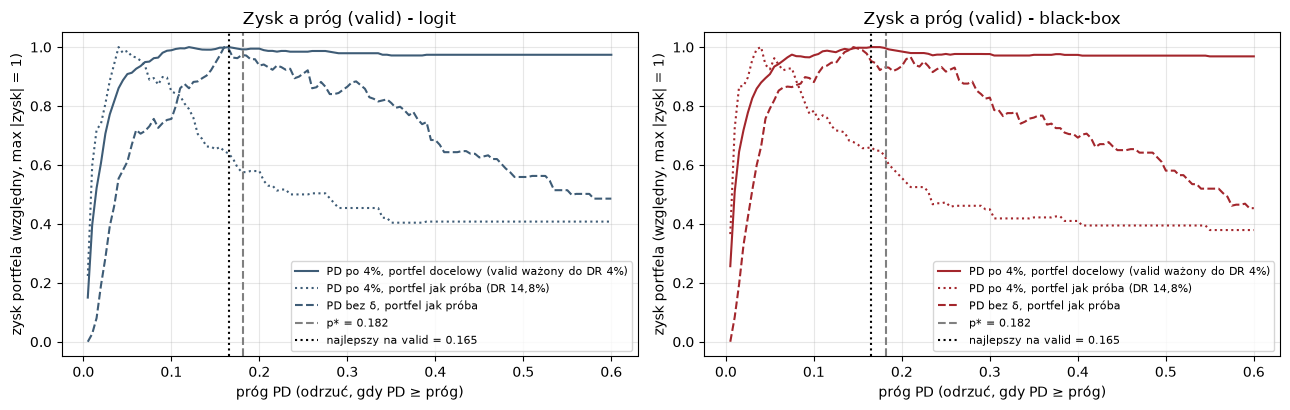

próg  stopa akceptacji  \
model     wariant                                                           
logit     portfel 4%: próg z valid (PD 4%)        0.165             0.979   
          portfel 4%: p* (PD 4%)                  0.182             0.986   
          portfel 4%: przyjmij wszystkich         1.010             1.000   
          portfel jak próba: p* (PD bez δ)        0.182             0.725   
          portfel jak próba: przyjmij wszystkich  1.010             1.000   
black-box portfel 4%: próg z valid (PD 4%)        0.165             0.965   
          portfel 4%: p* (PD 4%)                  0.182             0.968   
          portfel 4%: przyjmij wszystkich         1.010             1.000   
          portfel jak próba: p* (PD bez δ)        0.182             0.738   
          portfel jak próba: przyjmij wszystkich  1.010             1.000   

                                                  DR wśród przyjętych  \
model     wariant                                                       
logit     portfel 4%: próg z valid (PD 4%)                      0.034   
          portfel 4%: p* (PD 4%)                                0.036   
          portfel 4%: przyjmij wszystkich                       0.040   
          portfel jak próba: p* (PD bez δ)                      0.078   
          portfel jak próba: przyjmij wszystkich                0.149   
black-box portfel 4%: próg z valid (PD 4%)                      0.029   
          portfel 4%: p* (PD 4%)                                0.030   
          portfel 4%: przyjmij wszystkich                       0.040   
          portfel jak próba: p* (PD bez δ)                      0.084   
          portfel jak próba: przyjmij wszystkich                0.149   

                                                  TP (odrzucone złe)  \
model     wariant                                                      
logit     portfel 4%: próg z valid (PD 4%)                     3.769   
          portfel 4%: p* (PD 4%)                               2.961   
          portfel 4%: przyjmij wszystkich                      0.000   
          portfel jak próba: p* (PD bez δ)                    55.000   
          portfel jak próba: przyjmij wszystkich               0.000   
black-box portfel 4%: próg z valid (PD 4%)                     7.269   
          portfel 4%: p* (PD 4%)                               6.730   
          portfel 4%: przyjmij wszystkich                      0.000   
          portfel jak próba: p* (PD bez δ)                    52.000   
          portfel jak próba: przyjmij wszystkich               0.000   

                                                  FP (odrzucone dobre)  \
model     wariant                                                        
logit     portfel 4%: próg z valid (PD 4%)                       9.020   
          portfel 4%: p* (PD 4%)                                 5.638   
          portfel 4%: przyjmij wszystkich                        0.000   
          portfel jak próba: p* (PD bez δ)                     110.000   
          portfel jak próba: przyjmij wszystkich                 0.000   
black-box portfel 4%: próg z valid (PD 4%)                      13.530   
          portfel 4%: p* (PD 4%)                                12.403   
          portfel 4%: przyjmij wszystkich                        0.000   
          portfel jak próba: p* (PD bez δ)                     105.000   
          portfel jak próba: przyjmij wszystkich                 0.000   

                                                  FN (przyjęte złe)  \
model     wariant                                                     
logit     portfel 4%: próg z valid (PD 4%)                   20.191   
          portfel 4%: p* (PD 4%)                             20.999   
          portfel 4%: przyjmij wszystkich                    23.960   
          portfel jak próba: p* (PD bez δ)                   34.000   
          portfel jak próba: przyjmij wszystkich             89.000  

Progi operacyjne: {'logit': 'odrzucamy od PD ≥ 16.5%', 'black-box': 'odrzucamy od PD ≥ 16.5%'}


In [118]:
def ekonomia(y, p, prog, margin=MARGIN, lgd=LGD, w=None, przyj=None):      # z Lab 3 (5.4), EAD = 1; w - wagi portfela docelowego
    w = np.ones(len(y)) if w is None else np.asarray(w, dtype=float)
    przyj = p < prog if przyj is None else przyj
    licz = lambda m: float(np.sum(w[m]))
    tp, fp, fn, tn = licz(~przyj & (y == 1)), licz(~przyj & (y == 0)), licz(przyj & (y == 1)), licz(przyj & (y == 0))
    return {"próg": prog, "stopa akceptacji": licz(przyj) / w.sum(), "DR wśród przyjętych": fn / (fn + tn) if przyj.any() else np.nan,
            "TP (odrzucone złe)": tp, "FP (odrzucone dobre)": fp, "FN (przyjęte złe)": fn, "TN (przyjęte dobre)": tn,
            "EL przyjętych (oczekiwana)": float(np.sum(w[przyj] * p[przyj] * lgd)), "strata zrealizowana": lgd * fn,
            "zysk": margin * tn - lgd * fn}

def wagi_4(y):                                                # portfel docelowy: DR = 4% (jak w 11.5)
    return np.where(y == 1, TARGET_PD / y.mean(), (1 - TARGET_PD) / (1 - y.mean()))

progi = np.linspace(0.005, 0.6, 120)
PROG = {}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, m in zip(axes, P):
    for p_s, w_s, lab, ls in [(P4[m]["valid"], wagi_4(y_va), "PD po 4%, portfel docelowy (valid ważony do DR 4%)", "-"),
                              (P4[m]["valid"], None, "PD po 4%, portfel jak próba (DR 14,8%)", ":"),
                              (PS[m]["valid"], None, "PD bez δ, portfel jak próba", "--")]:
        z = np.array([ekonomia(y_va, p_s, t, w=w_s)["zysk"] for t in progi])
        ax.plot(progi, z / np.abs(z).max(), ls, color=KOL[m], label=lab)
        if ls == "-":
            PROG[m] = float(progi[int(np.argmax(z))])
    ax.axvline(p_star, ls="--", color="gray", label=f"p* = {p_star:.3f}"); ax.axvline(PROG[m], ls=":", color="black", label=f"najlepszy na valid = {PROG[m]:.3f}")
    ax.set_xlabel("próg PD (odrzuć, gdy PD ≥ próg)"); ax.set_ylabel("zysk portfela (względny, max |zysk| = 1)"); ax.set_title(f"Zysk a próg (valid) - {m}"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("wykresy/prog_zysk.png", dpi=120); plt.show()

W_TE4 = wagi_4(y_te)
tab_prog = pd.DataFrame([{"model": m, "wariant": w, **ekonomia(y_te, p, t, w=ww)} for m in P for w, p, t, ww in [
    ("portfel 4%: próg z valid (PD 4%)", P4[m]["test"], PROG[m], W_TE4), ("portfel 4%: p* (PD 4%)", P4[m]["test"], p_star, W_TE4),
    ("portfel 4%: przyjmij wszystkich", P4[m]["test"], 1.01, W_TE4),
    ("portfel jak próba: p* (PD bez δ)", PS[m]["test"], p_star, None), ("portfel jak próba: przyjmij wszystkich", PS[m]["test"], 1.01, None)]]
                        ).set_index(["model", "wariant"])
display(tab_prog.round(3))
print("Progi operacyjne:", {m: f"odrzucamy od PD ≥ {PROG[m]:.1%}" for m in P})

**Wnioski:**
- Najlepszy próg z ważonego valid to **16,5% dla obu modeli**, blisko teoretycznego p* = 18,2%.
  Sama bliskość progów nie potwierdza kalibracji PD.
- Na teście ważonym do DR 4% próg z valid daje akceptację 97,9% dla karty i 96,5% dla black-boxa.
  DR przyjętych wynosi odpowiednio 3,4% i 2,9%, a zysk 47,52 i 48,64 wobec 46,72 przy przyjęciu wszystkich
  (suma wag = 599). Przy p* zyski wynoszą 47,49 i 48,51 - niewiele mniej.
- Dla portfela jak próba (test: DR 14,9%; PD bez δ i próg p*) akceptacja wynosi 72,5% i 73,8%, DR przyjętych
  7,8% i 8,4%, a zysk 24,70 i 23,85 wobec 10,95 przy przyjęciu wszystkich.
- Ocena progu zależy od założonego portfela. Wyniki dla testu ważonego do DR 4% są symulacją, nie gwarancją
  wyniku w rzeczywistym portfelu. W 12.4 sprawdzamy próg 16,5% również na nieważonym teście.


#### 12.3.1 Firma graniczna dla progu operacyjnego: SHAP modelu końcowego (wykład 4)

Studia przypadków (9) wyjaśniają model w skali próby. Decyzję podejmujemy jednak na PD po przesunięciu do 4% i progu z 12.3,
więc firmę graniczną wybieramy właśnie tam: PD modelu końcowego najbliżej progu. Kalibracji kształtu nie stosujemy (11.2), a δ
jest stałym przesunięciem logitu, więc **SHAP modelu końcowego = te same wkłady φ, wartość bazowa φ₀ + δ** (wykład 4).

Firma graniczna: wiersz testu 54, PD końcowe 16.66% (próg 16.5%), rating B, default = 1
Kontrola: φ₀ + δ + Σφ = -1.610 | logit PD końcowego = -1.610


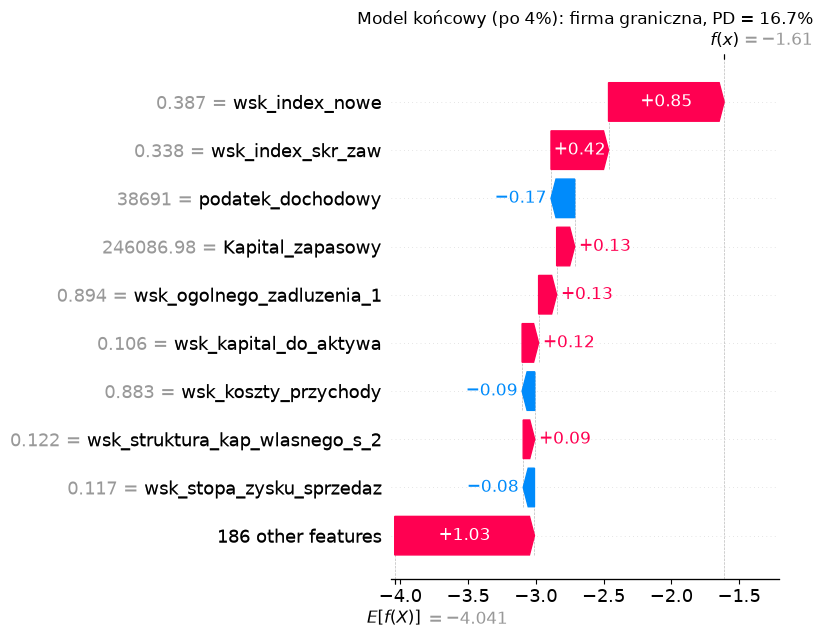

,wartość,SHAP,mnożnik szans e^φ,kierunek
wsk_index_nowe,0.387364,0.853,2.35,podnosi ryzyko
wsk_index_skr_zaw,0.338095,0.424,1.53,podnosi ryzyko
podatek_dochodowy,38691.000000,-0.175,0.84,obniża ryzyko
Kapital_zapasowy,246086.980000,0.133,1.14,podnosi ryzyko
wsk_ogolnego_zadluzenia_1,0.894092,0.133,1.14,podnosi ryzyko
wsk_kapital_do_aktywa,0.105908,0.122,1.13,podnosi ryzyko


In [119]:
pd_kon_te = P4["black-box"]["test"]
I_GRAN = int(np.argmin(np.abs(pd_kon_te - PROG["black-box"])))
phi0_kon = BAZA_BB + DELTA["black-box"]
print(f"Firma graniczna: wiersz testu {I_GRAN}, PD końcowe {pd_kon_te[I_GRAN]:.2%} (próg {PROG['black-box']:.1%}), "
      f"rating {R['black-box']['test'][I_GRAN]}, default = {y_te[I_GRAN]}")
print(f"Kontrola: φ₀ + δ + Σφ = {phi0_kon + PHI_BB[I_GRAN].sum():+.3f} | logit PD końcowego = {_z(pd_kon_te[I_GRAN:I_GRAN + 1])[0]:+.3f}")
shap.plots.waterfall(shap.Explanation(values=PHI_BB[I_GRAN], base_values=phi0_kon, data=XS.iloc[I_GRAN].to_numpy(dtype=object),
                                      feature_names=FEATURES), max_display=10, show=False)
plt.title(f"Model końcowy (po 4%): firma graniczna, PD = {pd_kon_te[I_GRAN]:.1%}"); plt.tight_layout()
plt.savefig("wykresy/waterfall_graniczna_4proc.png", dpi=110, bbox_inches="tight"); plt.show()
display(powody(I_GRAN, 6))

**Wnioski:** firma graniczna (wiersz 54 testu) ma PD końcowe 16,66% przy progu 16,5%, rating B i zostaje
odrzucona; później wystąpił default. Kontrola addytywności daje −1,610 log-szans. Największe wkłady podnoszące
wynik pochodzą od `wsk_index_nowe` (+0,853; mnożnik szans 2,35) i `wsk_index_skr_zaw` (+0,424; mnożnik 1,53);
`podatek_dochodowy` ma wkład −0,175.

Przesunięcie δ nie zmienia wkładów SHAP w log-szansach, ale zmienia wartość bazową i PD, a więc może zmienić decyzję.
Wkłady opisują działanie modelu względem przyjętego tła, nie dowodzą związku przyczynowego.


### 12.4 Tabela decyzyjna: wpływ progu na wyniki biznesowe (black-box, test)

In [120]:
tab_dec = pd.DataFrame([ekonomia(y_te, P4["black-box"]["test"], t) for t in [0.03, 0.05, 0.08, PROG["black-box"], 0.12, 0.20, 1.01]]).set_index("próg").sort_index()
display(tab_dec.round(3))

,stopa akceptacji,DR wśród przyjętych,TP (odrzucone złe),FP (odrzucone dobre),FN (przyjęte złe),TN (przyjęte dobre),EL przyjętych (oczekiwana),strata zrealizowana,zysk
próg,,,,,,,,,
0.030,0.639,0.073,61.0,155.0,28.0,355.0,1.829,12.60,22.90
0.050,0.751,0.084,51.0,98.0,38.0,412.0,3.053,17.10,24.10
0.080,0.821,0.089,45.0,62.0,44.0,448.0,4.286,19.80,25.00
0.120,0.891,0.101,35.0,30.0,54.0,480.0,6.154,24.30,23.70
0.165,0.935,0.111,27.0,12.0,62.0,498.0,7.794,27.90,21.90
0.200,0.957,0.126,17.0,9.0,72.0,501.0,8.876,32.40,17.70
1.010,1.000,0.149,0.0,0.0,89.0,510.0,12.317,40.05,10.95


**Wnioski:** tabela dotyczy nieważonego testu (DR 14,9%) i PD po δ. Obniżenie progu z 20% do 3% zmniejsza
akceptację z 95,7% do 63,9% i DR przyjętych z 12,6% do 7,3%. Spośród pokazanych progów najwyższy zysk daje 8%:
25,00; przy progu z valid 16,5% zysk wynosi 21,90.

Między progami 8% i 3% odrzucamy dodatkowo 16 złych i 93 dobre firmy, więc zysk spada z 25,00 do 22,90.
To porównanie na teście pokazuje wpływ progu w próbie; nie wybieramy na tej podstawie nowego progu operacyjnego.


### 12.5 Porównanie decyzji: karta a black-box (test)

In [121]:
dec = {m: np.where(P4[m]["test"] < PROG[m], "przyjęty", "odrzucony") for m in P}
display(pd.crosstab(pd.Series(dec["logit"], name="karta"), pd.Series(dec["black-box"], name="black-box"), margins=True))
krz = pd.crosstab(pd.Series(R["logit"]["test"], name="rating karty"), pd.Series(R["black-box"]["test"], name="rating black-boxa"))
display(krz)
kod_l, kod_b = np.asarray(R["logit"]["test"].codes), np.asarray(R["black-box"]["test"].codes)
niezg = dec["logit"] != dec["black-box"]
print(f"Zgodność decyzji: {np.mean(~niezg):.1%} | ten sam rating: {np.mean(kod_l == kod_b):.1%} | różnica ≤ 1 klasa: {np.mean(np.abs(kod_l - kod_b) <= 1):.1%}")
tylko_l, tylko_b = (dec["logit"] == "odrzucony") & (dec["black-box"] == "przyjęty"), (dec["logit"] == "przyjęty") & (dec["black-box"] == "odrzucony")
print(f"Firmy z różną decyzją: {niezg.sum()} | odrzucone tylko przez kartę: {tylko_l.sum()} (DR {y_te[tylko_l].mean() if tylko_l.any() else np.nan:.1%}), "
      f"tylko przez black-box: {tylko_b.sum()}")

black-box,odrzucony,przyjęty,All
karta,,,
odrzucony,19,3,22
przyjęty,20,557,577
All,39,560,599


rating black-boxa,AAA,AA,A,BBB,BB,B,CCC
rating karty,,,,,,,
AAA,144,18,2,1,0,0,0
AA,54,42,21,2,1,0,0
A,25,39,69,12,6,1,0
BBB,0,3,15,13,12,7,1
BB,0,2,9,10,13,16,4
B,0,0,6,4,10,14,7
CCC,0,0,1,0,0,1,14


Zgodność decyzji: 96.2% | ten sam rating: 51.6% | różnica ≤ 1 klasa: 87.5%
Firmy z różną decyzją: 23 | odrzucone tylko przez kartę: 3 (DR 66.7%), tylko przez black-box: 20


Oba progi z valid wynoszą 16,5%, ale black-box odrzuca więcej firm (39 vs 22).
Porównujemy też modele **przy tej samej liczbie przyjętych firm**: osobno dla liczby wynikającej z progu
black-boxa i karty. Firmy szeregujemy według PD; remisy rozstrzygamy według kolejności wierszy testu,
bez użycia informacji o defaultach. Przy remisie na granicy wynik może zależeć od tego wyboru, a decyzji
nie da się odtworzyć samym progiem PD. To porównanie rankingów na teście, nie wybór progu operacyjnego.


In [122]:
wiersze = []
for liczba in [np.sum(P4["black-box"]["test"] < PROG["black-box"]), np.sum(P4["logit"]["test"] < PROG["logit"])]:
    d_ = {}
    for m in P:
        p = P4[m]["test"]
        kolejnosc = np.argsort(p, kind="stable")
        d_[m] = np.zeros(len(p), dtype=bool)
        d_[m][kolejnosc[:liczba]] = True
        wynik = ekonomia(y_te, p, None, przyj=d_[m])
        wynik["stopa akceptacji"] = round(wynik["stopa akceptacji"], 3)
        wiersze.append({"model": m, **{k: v for k, v in wynik.items() if k != "próg"}})
    wiersze[-1]["zgodność decyzji"] = wiersze[-2]["zgodność decyzji"] = np.mean(d_["logit"] == d_["black-box"])
display(pd.DataFrame(wiersze).set_index(["stopa akceptacji", "model"]).round(3))


DR wśród przyjętych  TP (odrzucone złe)  \
stopa akceptacji model                                                
0.935            logit                    0.121                21.0   
                 black-box                0.111                27.0   
0.963            logit                    0.130                14.0   
                 black-box                0.132                13.0   

                            FP (odrzucone dobre)  FN (przyjęte złe)  \
stopa akceptacji model                                                
0.935            logit                      18.0               68.0   
                 black-box                  12.0               62.0   
0.963            logit                       8.0               75.0   
                 black-box                   9.0               76.0   

                            TN (przyjęte dobre)  EL przyjętych (oczekiwana)  \
stopa akceptacji model                                                        
0.935            logit                    492.0                       8.391   
                 black-box                498.0                       7.794   
0.963            logit                    502.0                       9.504   
                 black-box                501.0                       9.250   

                            strata zrealizowana   zysk  zgodność decyzji  
stopa akceptacji model                                                    
0.935            logit                    30.60  18.60             0.947  
                 black-box                27.90  21.90             0.947  
0.963            logit                    33.75  16.45             0.980  
                 black-box                34.20  15.90             0.980

**Wnioski:**
- Przy progach z valid decyzje są zgodne dla 96,2% firm. Z 23 różnych decyzji 20 to firmy odrzucone tylko
  przez black-box, a 3 - tylko przez kartę.
- Przy akceptacji 560 z 599 firm (93,5%) zgodność wynosi 94,7%. Black-box odrzuca 27 złych i 12 dobrych,
  karta 21 złych i 18 dobrych; zysk wynosi odpowiednio 21,90 i 18,60. Wynik karty zależy tu od rozstrzygnięcia
  remisu na granicy.
- Przy akceptacji 577 firm (96,3%) zgodność wynosi 98,0%; karta odrzuca 14 złych, black-box 13,
  a zyski wynoszą 16,45 i 15,90. Oba porównania zysku dotyczą nieważonego testu.
- Ten sam rating otrzymuje 51,6% firm, a różnica wynosi najwyżej jedną klasę dla 87,5%.


### 12.6 Global surrogate: płytkie drzewo naśladujące black-box (Lab 6)

Drzewo regresyjne uczymy na **log-szansach black-boxa** w train, a nie na faktycznych defaultach.
Na teście mierzymy R² log-szans, zgodność decyzji przy progu z 12.3, odsetek firm odrzuconych przez
black-box, które odrzuca też drzewo, oraz zgodność klas ratingowych. PD surogatu przechodzi ten sam
łańcuch kalibracji i przesunięcia co PD black-boxa.

PD liścia jest przekształconą średnią log-szans black-boxa w liściu, a nie dokładnym PD każdej firmy.
Reguły pomijają wyuczony kierunek obsługi braków danych. Surogat służy do opisu modelu, nie do decyzji.


In [123]:
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import r2_score

Z_tr_s, Z_te_s = pre_bb.transform(X_tr), pre_bb.transform(X_te)
f_tr_s, f_te_s = _z(P["black-box"]["train"]), _z(P["black-box"]["test"])      # log-szanse black-boxa
NAZWY_S = [n.split("__", 1)[1] for n in nazwy_bb]
pd_z_logit = lambda g: expit(_z(zastosuj(METODA["black-box"], KAL["black-box"], expit(g))) + DELTA["black-box"])
odrz_bb = P4["black-box"]["test"] >= PROG["black-box"]
klasy_bb = np.asarray(R["black-box"]["test"]).astype(str)

def surogat(glebokosc):                                       # z Lab 6 (4); min. liść 50 firm (train ma 1 800 firm)
    return DecisionTreeRegressor(max_depth=glebokosc, min_samples_leaf=50, random_state=RNG_SEED).fit(Z_tr_s, f_tr_s)

wiersze = []
for d in [2, 3, 4, 5, 6, 8]:
    s = surogat(d); g_te = s.predict(Z_te_s); pd_s = pd_z_logit(g_te)
    wiersze.append({"głębokość": d, "liczba liści": s.get_n_leaves(), "wierność R² (test)": r2_score(f_te_s, g_te),
                    "zgodność decyzji": np.mean((pd_s >= PROG["black-box"]) == odrz_bb),
                    "odrzuceni przez black-box - odrzuceni też przez surogat": np.mean(pd_s[odrz_bb] >= PROG["black-box"]) if odrz_bb.any() else np.nan,
                    "zgodność klas ratingowych": np.mean(np.asarray(rating(pd_s)).astype(str) == klasy_bb),
                    "Gini surogatu (test)": 2 * roc_auc_score(y_te, g_te) - 1})
TAB_SUR = pd.DataFrame(wiersze).set_index("głębokość")
display(TAB_SUR.round(3))
print(f"Firm odrzuconych przez black-box na teście: {odrz_bb.sum()} | Gini (test): black-box {2 * roc_auc_score(y_te, f_te_s) - 1:.3f}, "
      f"karta {2 * roc_auc_score(y_te, P['logit']['test']) - 1:.3f}")

,liczba liści,wierność R² (test),zgodność decyzji,odrzuceni przez black-box - odrzuceni też przez surogat,zgodność klas ratingowych,Gini surogatu (test)
głębokość,,,,,,
2,4,0.525,0.935,0.000,0.407,0.350
3,8,0.631,0.950,0.359,0.454,0.426
4,16,0.700,0.947,0.205,0.504,0.489
5,22,0.733,0.947,0.205,0.487,0.493
6,28,0.737,0.947,0.205,0.508,0.473
8,28,0.737,0.947,0.205,0.508,0.473


Firm odrzuconych przez black-box na teście: 39 | Gini (test): black-box 0.583, karta 0.562


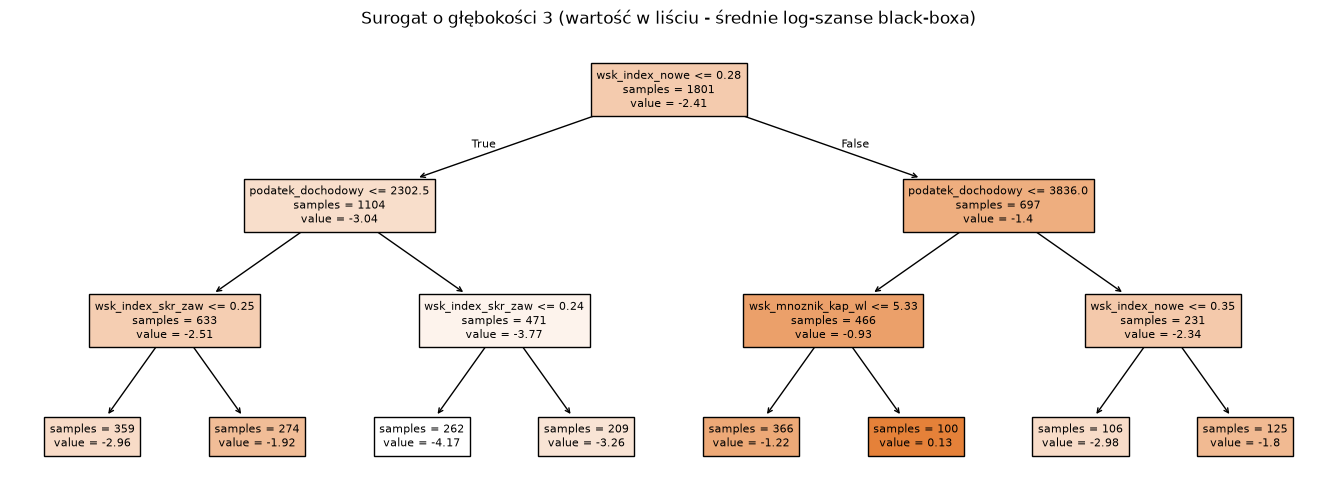

,reguła,udział firm (train),PD surogatu
0,wsk_index_nowe ≤ 0.282 i podatek_dochodowy > 2.3e+03 i wsk_index_skr_zaw ≤ 0.24,0.145,0.004
1,wsk_index_nowe ≤ 0.282 i podatek_dochodowy > 2.3e+03 i wsk_index_skr_zaw > 0.24,0.116,0.009
2,wsk_index_nowe > 0.282 i podatek_dochodowy > 3.84e+03 i wsk_index_nowe ≤ 0.352,0.059,0.011
3,wsk_index_nowe ≤ 0.282 i podatek_dochodowy ≤ 2.3e+03 i wsk_index_skr_zaw ≤ 0.252,0.199,0.012
4,wsk_index_nowe ≤ 0.282 i podatek_dochodowy ≤ 2.3e+03 i wsk_index_skr_zaw > 0.252,0.152,0.032
5,wsk_index_nowe > 0.282 i podatek_dochodowy > 3.84e+03 i wsk_index_nowe > 0.352,0.069,0.036
6,wsk_index_nowe > 0.282 i podatek_dochodowy ≤ 3.84e+03 i wsk_mnoznik_kap_wl ≤ 5.33,0.203,0.063
7,wsk_index_nowe > 0.282 i podatek_dochodowy ≤ 3.84e+03 i wsk_mnoznik_kap_wl > 5.33,0.056,0.207


In [124]:
def reguly(drzewo, nazwy):                                    # z Lab 6 (4)
    # liście drzewa jako reguły „jeżeli ... to PD” (braki danych: kierunek wyuczony przez drzewo, pomijany w opisie)
    t, wyn = drzewo.tree_, []
    def idz(w, war):
        if t.children_left[w] == -1:
            wyn.append({"reguła": " i ".join(war), "udział firm (train)": t.n_node_samples[w] / t.n_node_samples[0],
                        "PD surogatu": float(pd_z_logit(np.array([t.value[w][0][0]]))[0])})
            return
        c, prog = nazwy[t.feature[w]], t.threshold[w]
        idz(t.children_left[w], war + [f"{c} ≤ {prog:.3g}"]); idz(t.children_right[w], war + [f"{c} > {prog:.3g}"])
    idz(0, [])
    return pd.DataFrame(wyn).sort_values("PD surogatu").reset_index(drop=True)

sur3 = surogat(3)
fig, ax = plt.subplots(figsize=(17, 6))
plot_tree(sur3, feature_names=NAZWY_S, filled=True, impurity=False, precision=2, fontsize=8, ax=ax)
ax.set_title("Surogat o głębokości 3 (wartość w liściu - średnie log-szanse black-boxa)")
plt.savefig("wykresy/surogat.png", dpi=110, bbox_inches="tight"); plt.show()
with pd.option_context("display.max_colwidth", 140):
    display(reguly(sur3, NAZWY_S).round(3))

**Wnioski:**
- Wierność R² na teście rośnie od 0,525 dla głębokości 2 do 0,737 dla 6 i 8; dla głębokości 3 wynosi 0,631.
- Black-box odrzuca 39 z 599 firm. Surogat o głębokości 3 odrzuca 14 z nich (35,9%), choć zgodność
  decyzji ogółem wynosi 95,0%. Dla głębokości 2 odtwarza 0% odrzuceń, a dla 4-8 - 20,5%.
  Sama zgodność ogółem jest więc myląca przy dużym udziale akceptacji.
- W drzewie głębokości 3 pierwszy podział dotyczy `wsk_index_nowe` (około 0,282), kolejne m.in. podatku
  dochodowego i `wsk_index_skr_zaw`. Najwyższe PD surogatu, 20,7%, dotyczy liścia z wysokim
  `wsk_index_nowe`, podatkiem dochodowym do około 3,84 tys. i `wsk_mnoznik_kap_wl` powyżej 5,33;
  trafia tam 5,6% firm train. Progi w tabeli są zaokrąglone.
- Gini surogatu wynosi 0,426 dla głębokości 3 i maksymalnie 0,493 dla badanych głębokości, mniej niż
  0,562 dla karty i 0,583 dla black-boxa. Surogat jest uproszczonym opisem, nie zamiennikiem modeli.


## 13. Analiza kontrfaktyczna

**Pytanie:** jakie z badanych zmian sytuacji finansowej poprawiają rating firmy z BB do BBB lub wyżej?

Black-box używa ponad 190 cech, z których wiele jest skorelowanych. Zmieniamy więc **dźwignie**: grupy cech
o |ρ| ≥ 0,7 z wybraną cechą karty (korelacje Spearmana z train, jak w 7.3). Przesuwamy wartości cech
w kierunku niższego ryzyka o zadaną liczbę punktów percentylowych ich rozkładów z train.
Kategorie i wskaźniki branżowe pozostają bez zmian; do aktualnych grup nie należy wiek firmy.

Badamy pojedyncze dźwignie od 5 do 80 pp oraz pary z równym przesunięciem od 5 do 40 pp dla każdej dźwigni.
Pary o wspólnych cechach pomijamy, aby nie przesuwać tej samej cechy dwukrotnie. Koszt to suma zadanych
przesunięć w pp, a nie rzeczywisty koszt ekonomiczny. Najtańszy wynik oznacza minimum wśród zbadanych zmian,
nie wśród wszystkich możliwych kontrfaktów.


In [130]:
from scipy.stats import rankdata
R_TR = {c: np.sort(X_tr[c].dropna().to_numpy()) for c in num_cols}

def przesun(x, c, delta_pct, kier):
    # przesunięcie wartości cechy c o delta_pct percentyli w kierunku kier (+1 w górę, -1 w dół) rozkładu z train
    if pd.isna(x):
        return x
    r = np.searchsorted(R_TR[c], x, side="right") / len(R_TR[c])
    return float(np.quantile(R_TR[c], np.clip(r + kier * delta_pct, 0, 1)))

KIER_RYZYKA = {c: OCZEKIWANY[c] for c in CECHY_L}            # +1: wyższa wartość = wyższe ryzyko
DZWIGNIE = {}
for c in [c for c in CECHY_L if c not in WSK_INDEX]:         # wskaźniki branżowe - firma nie ma na nie wpływu
    czl = [f for f in num_cols if abs(kor_tr.loc[c, f]) >= 0.7 and f not in WSK_INDEX]
    DZWIGNIE[c] = {f: -KIER_RYZYKA[c] * int(np.sign(kor_tr.loc[c, f])) for f in czl}    # kierunek zmiany obniżający ryzyko
display(pd.DataFrame({"liczba cech w dźwigni": {c: len(v) for c, v in DZWIGNIE.items()},
                      "kierunek zmiany cechy wiodącej": {c: "w górę" if v[c] > 0 else "w dół" for c, v in DZWIGNIE.items()}}))

def jako_df(x):
    return x.to_frame().T.astype(X_te.dtypes.to_dict())

def zastosuj_dzwignie(x, zmiany):
    x = x.copy()
    for d, delta in zmiany.items():
        for f, kier in DZWIGNIE[d].items():
            x[f] = przesun(x[f], f, delta, kier)
    return x

oba_bb = (np.asarray(R["black-box"]["test"]).astype(str) == "BB") & (np.asarray(R["logit"]["test"]).astype(str) == "BB")
kandydaci_bb = np.where(oba_bb)[0] if oba_bb.any() else np.where(np.asarray(R["black-box"]["test"]).astype(str) == "BB")[0]   # BB w obu modelach
i_cf = int(kandydaci_bb[np.argmin(np.abs(P4["black-box"]["test"][kandydaci_bb] - 0.10))])            # BB, PD w środku klasy
print(f"Firm z ratingiem BB w obu modelach: {oba_bb.sum()}")
x_cf = X_te.iloc[i_cf]
print(f"Firma: wiersz testu {i_cf}, PD po 4% = {P4['black-box']['test'][i_cf]:.2%}, rating {R['black-box']['test'][i_cf]}, "
      f"karta: PD = {P4['logit']['test'][i_cf]:.2%}, rating {R['logit']['test'][i_cf]}, default = {y_te[i_cf]}")
display(x_cf[CECHY_L].to_frame("wartość").T)

,liczba cech w dźwigni,kierunek zmiany cechy wiodącej
podatek_dochodowy,2,w górę
Kapital_wlasny,8,w górę
wsk_ogolnego_zadluzenia_1,18,w dół
wsk_zysk_zobowiazania,31,w górę
wsk_stopa_zysku_sprzedaz,2,w górę
wsk_sytuacji_fin,1,w górę
pozostale_przychody_oper,4,w górę


Firm z ratingiem BB w obu modelach: 13
Firma: wiersz testu 19, PD po 4% = 10.07%, rating BB, karta: PD = 9.40%, rating BB, default = 1


,wsk_index_nowe,podatek_dochodowy,Kapital_wlasny,wsk_ogolnego_zadluzenia_1,wsk_zysk_zobowiazania,wsk_stopa_zysku_sprzedaz,wsk_sytuacji_fin,pozostale_przychody_oper
wartość,0.284008,0.0,1517.77,0.555918,-0.5,-9.5,0.351639,0.0


In [131]:
KROKI = np.round(np.arange(0.05, 0.81, 0.05), 2)
wyniki_cf = []
for d in DZWIGNIE:
    for delta in KROKI:
        p = pd_koncowe(zastosuj_dzwignie(x_cf, {d: delta}).pipe(jako_df))[0]
        krok = round(100 * delta)
        wyniki_cf.append({"dźwignie": d, "przesunięcie (pp percentyla)": str(krok), "koszt (pp percentyla)": krok,
                          "PD": p, "rating": rating([p])[0]})
pary = list(itertools.combinations(DZWIGNIE, 2))
pary_rozlaczne = [(d1, d2) for d1, d2 in pary if not (DZWIGNIE[d1].keys() & DZWIGNIE[d2].keys())]
for d1, d2 in pary_rozlaczne:
    for delta in KROKI[:8]:
        p = pd_koncowe(zastosuj_dzwignie(x_cf, {d1: delta, d2: delta}).pipe(jako_df))[0]
        krok = round(100 * delta)
        wyniki_cf.append({"dźwignie": f"{d1} + {d2}", "przesunięcie (pp percentyla)": f"{krok} + {krok}",
                          "koszt (pp percentyla)": 2 * krok, "PD": p, "rating": rating([p])[0]})
cf = pd.DataFrame(wyniki_cf)
cel = cf[cf["rating"].astype(str).isin(["BBB", "A", "AA", "AAA"])]
najtansze = cel.sort_values("koszt (pp percentyla)", kind="stable").groupby("dźwignie").head(1).sort_values("koszt (pp percentyla)", kind="stable").head(8)
print(f"Pominięto {len(pary) - len(pary_rozlaczne)} par dźwigni o wspólnych cechach.")
print("Do 8 najtańszych znalezionych zmian (po jednej dla każdej dźwigni lub pary):")
with pd.option_context("display.max_colwidth", None):
    display(najtansze.round(4))


Pominięto 3 par dźwigni o wspólnych cechach.
Do 8 najtańszych znalezionych zmian (po jednej dla każdej dźwigni lub pary):


,dźwignie,przesunięcie (pp percentyla),koszt (pp percentyla),PD,rating
32,wsk_ogolnego_zadluzenia_1,5,5,0.0769,BBB
120,podatek_dochodowy + wsk_ogolnego_zadluzenia_1,5 + 5,10,0.0754,BBB
176,wsk_ogolnego_zadluzenia_1 + wsk_zysk_zobowiazania,5 + 5,10,0.0683,BBB
184,wsk_ogolnego_zadluzenia_1 + wsk_stopa_zysku_sprzedaz,5 + 5,10,0.0767,BBB
192,wsk_ogolnego_zadluzenia_1 + wsk_sytuacji_fin,5 + 5,10,0.0796,BBB
200,wsk_ogolnego_zadluzenia_1 + pozostale_przychody_oper,5 + 5,10,0.0791,BBB
23,Kapital_wlasny,40,40,0.0775,BBB
131,podatek_dochodowy + wsk_stopa_zysku_sprzedaz,20 + 20,40,0.0789,BBB


**Wnioski:** na teście jest 13 firm z ratingiem BB w obu modelach. Wybrana firma (wiersz 19) ma PD
10,07% w black-boxie i 9,40% w karcie; później wystąpił default.

Najtańsza z badanych zmian to dźwignia **zadłużenia ogólnego**: przesunięcie o 5 pp percentyla daje PD
7,69% i rating BBB. Kilka rozłącznych par osiąga cel przy koszcie 10 pp (po 5 pp na dźwignię).
Pojedyncza dźwignia kapitału własnego osiąga cel przy 40 pp. Pominięto trzy pary o wspólnych cechach.


### 13.1 Wiarygodność kontrfaktu i porównanie z SHAP / LIME

Porównujemy odległość kontrfaktu do najbliższej firmy z train z odległościami firm testowych. Odległość
liczymy w przestrzeni rang percentylowych 20 najważniejszych cech liczbowych black-boxa. Jest to pomocnicza
miara podobieństwa, nie test spójności księgowej ani wykonalności zmiany.

SHAP podajemy w log-szansach, a LIME w skali PD. LIME wybiera tylko 10 cech: w tabeli pokazujemy ich
liczbę w każdej dźwigni i sumę ich wag. Brak wybranych cech oznaczamy jako NaN, nie jako zerowy wpływ.
NaN w koszcie oznacza brak skutecznej pojedynczej zmiany w badanym zakresie.


In [132]:
from sklearn.neighbors import NearestNeighbors
TOP20 = [c for c in TOP_BB if c in num_cols][:20] + [c for c in waz_shap_bb.index if c in num_cols and c not in TOP_BB][:max(0, 20 - len([c for c in TOP_BB if c in num_cols]))]
def rangi_pct(Xw):
    return np.column_stack([np.searchsorted(R_TR[c], Xw[c].fillna(np.nanmedian(R_TR[c])).to_numpy(), side="right") / len(R_TR[c]) for c in TOP20])
nn = NearestNeighbors(n_neighbors=1).fit(rangi_pct(X_tr))
odl_typowe = nn.kneighbors(rangi_pct(X_te))[0].ravel()
najl_cf = najtansze.iloc[0]
zm = {d.strip(): float(v) / 100 for d, v in zip(najl_cf["dźwignie"].split("+"), najl_cf["przesunięcie (pp percentyla)"].split("+"))}
x_nowe = zastosuj_dzwignie(x_cf, zm)
odl_cf = nn.kneighbors(rangi_pct(x_nowe.pipe(jako_df)))[0][0, 0]
print(f"Najtańszy kontrfakt: {najl_cf['dźwignie']} o {najl_cf['przesunięcie (pp percentyla)']} pp percentyla -> PD {najl_cf['PD']:.2%}, rating {najl_cf['rating']}")
print(f"Odległość do najbliższej firmy z train: kontrfakt {odl_cf:.3f} | firmy testowe: mediana {np.median(odl_typowe):.3f}, 90. percentyl {np.percentile(odl_typowe, 90):.3f}")
display(pd.DataFrame({"przed": x_cf[[c for c in DZWIGNIE[list(zm)[0]]][:8]], "po": x_nowe[[c for c in DZWIGNIE[list(zm)[0]]][:8]]}).round(3))

s_shap = pd.Series(PHI_BB[i_cf], index=FEATURES)
e_cf = lime_wyjasnij(i_cf)
s_lime = pd.Series({FEATURES[j]: w for j, w in e_cf.local_exp[1]})
dz_shap = pd.Series({d: s_shap[list(DZWIGNIE[d])].sum() for d in DZWIGNIE})
dz_lime = pd.Series({d: s_lime.reindex(list(DZWIGNIE[d])).sum(min_count=1) for d in DZWIGNIE})
liczba_lime = pd.Series({d: s_lime.index.isin(DZWIGNIE[d]).sum() for d in DZWIGNIE})
print(f"LIME dla tej firmy: R² lokalne = {e_cf.score:.3f} | uwzględnionych cech: {len(s_lime)}")
display(pd.DataFrame({"suma SHAP cech dźwigni (log-szanse)": dz_shap,
                      "liczba cech dźwigni wybranych przez LIME": liczba_lime,
                      "suma wag wybranych cech LIME (PD)": dz_lime,
                      "najtańszy pojedynczy kontrfakt (pp percentyla)": cel.groupby("dźwignie")["koszt (pp percentyla)"].min().reindex(list(DZWIGNIE))}).round(3))


Najtańszy kontrfakt: wsk_ogolnego_zadluzenia_1 o 5 pp percentyla -> PD 7.69%, rating BBB
Odległość do najbliższej firmy z train: kontrfakt 0.389 | firmy testowe: mediana 0.555, 90. percentyl 0.717


,przed,po
Zobowiazania_rezerwy,1900.0,353.5
wsk_kapital_do_aktywa,0.444082,0.500265
wsk_mnoznik_kap_wl,2.251837,1.995431
wsk_udzial_kap_wlasnego_aktywa_1,0.444082,0.501135
wsk_udzial_kap_wlasnego_aktywa_2,0.722041,0.795926
wsk_ogolnego_zadluzenia_1,0.555918,0.498025
wsk_ogolnego_zadluzenia_2,0.555918,0.498854
wsk_zadluzenie_kap_wlasnego,1.251837,0.992135


LIME dla tej firmy: R² lokalne = 0.243 | uwzględnionych cech: 10


,suma SHAP cech dźwigni (log-szanse),liczba cech dźwigni wybranych przez LIME,suma wag wybranych cech LIME (PD),najtańszy pojedynczy kontrfakt (pp percentyla)
podatek_dochodowy,0.134,1,-0.017,50.0
Kapital_wlasny,0.369,1,-0.019,40.0
wsk_ogolnego_zadluzenia_1,0.186,1,0.006,5.0
wsk_zysk_zobowiazania,0.088,3,-0.031,NaN
wsk_stopa_zysku_sprzedaz,0.177,0,NaN,65.0
wsk_sytuacji_fin,0.030,0,NaN,NaN
pozostale_przychody_oper,-0.009,0,NaN,NaN


**Wnioski:**
- Dla najtańszego kontrfaktu `wsk_ogolnego_zadluzenia_1` zmienia się z 0,556 na 0,498; zmieniane są
  też inne cechy dźwigni. Odległość do najbliższej firmy z train wynosi 0,389, wobec mediany 0,555
  i 90. percentyla 0,717 dla firm testowych. Mniejsza odległość nie dowodzi wykonalności: osobne
  przesunięcia skorelowanych cech nie gwarantują spójności sprawozdania.
- Suma SHAP wynosi +0,369 dla dźwigni kapitału własnego i +0,186 dla zadłużenia. SHAP opisuje wkłady
  względem tła, natomiast koszt kontrfaktu dotyczy badanych zmian potrzebnych do przekroczenia granicy;
  nie są to te same rankingi.
- LIME wybrał jedną cechę dźwigni zadłużenia i nie wybrał żadnej dla trzech dźwigni. Jego lokalne R²
  dla tej firmy wynosi 0,243. Wagi LIME i SHAP mają różne skale, a brak cechy w LIME nie oznacza,
  że jej wpływ na model jest zerowy.
- Kontrfakt opisuje odpowiedź modelu, nie związek przyczynowy. Nie uwzględnia rzeczywistego kosztu,
  wykonalności zmian ani wszystkich zależności między pozycjami sprawozdania.


### 13.2 Kontrfakt w karcie scoringowej

W karcie liczymy zmianę punktów potrzebną do ratingu BBB oraz skutki przejść między przedziałami cech.
Granica BBB to PD < 8%; dla obliczeń przyjmujemy cel 7,99%, nieco poniżej granicy. Punkty obliczamy
dokładnie z modelu, ale pojedyncze przejścia nie uwzględniają zmian innych powiązanych cech ani
wykonalności ekonomicznej.


In [133]:
pd_lim = RATING_BINS[RATING_LABELS.index("BB")]                 # granica BBB / BB
p_l = P4["logit"]["test"][i_cf]
pd_docelowe = pd_lim - 1e-4
z0 = baseline.decision_function(X_te.iloc[[i_cf]][CECHY_L])[0]
pd_z_modelu = lambda t: expit(_z(zastosuj(METODA["logit"], KAL["logit"], np.array([expit(z0 + t)]))) + DELTA["logit"])[0] - pd_docelowe
dz = brentq(pd_z_modelu, -10, 0) if p_l >= pd_lim else 0.0    # wymagana zmiana logitu karty (łańcuch kalibracji uwzględniony)
potrzebne_pkt = -factor * dz
wiersze = []
kody_cf = woe_l.codes(X_te.iloc[[i_cf]][CECHY_L]).iloc[0]
for c in [c for c in CECHY_L if c not in WSK_INDEX]:
    tab = woe_l.tables_[c]; k = int(kody_cf[c])
    for k2 in range(len(tab)):
        if k2 == k or tab["przedział"].iloc[k2] == "BRAK":
            continue
        d_pkt = factor * (-betas[c]) * (tab["WoE"].iloc[k2] - tab["WoE"].iloc[k])
        if d_pkt > 0:
            wiersze.append({"cecha": c, "z przedziału": tab["przedział"].iloc[k], "do przedziału": tab["przedział"].iloc[k2],
                            "skok przedziałów": abs(k2 - k), "zmiana punktów": d_pkt, "wystarczy sama": d_pkt >= potrzebne_pkt})
ruchy = pd.DataFrame(wiersze).sort_values(["skok przedziałów", "zmiana punktów"], ascending=[True, False])
print(f"Karta: PD po 4% = {p_l:.2%} ({R['logit']['test'][i_cf]}) | do ratingu BBB potrzeba PD < {pd_lim:.0%}")
if p_l >= pd_lim:
    print(f"Dla celu PD = {pd_docelowe:.2%} potrzeba {potrzebne_pkt:.1f} pkt więcej "
          f"(wynik {wynik_model[i_cf]:.0f} -> {wynik_model[i_cf] + potrzebne_pkt:.0f} pkt)")
else:
    print("Firma ma już rating BBB lub lepszy; nie potrzeba dodatkowych punktów.")
display(ruchy.head(8).round(1))

Karta: PD po 4% = 9.40% (BB) | do ratingu BBB potrzeba PD < 8%
Dla celu PD = 7.99% potrzeba 5.1 pkt więcej (wynik 510 -> 515 pkt)


,cecha,z przedziału,do przedziału,skok przedziałów,zmiana punktów,wystarczy sama
16,wsk_sytuacji_fin,[0.1079; 2.81),[2.81; inf),1,3.3,False
12,wsk_stopa_zysku_sprzedaz,[-inf; -8.79),[-8.79; -0.4397),1,2.8,False
4,Kapital_wlasny,[-inf; 2e+04),[2e+04; 5.613e+04),1,2.6,False
0,podatek_dochodowy,[-inf; 112),[112; 2384),1,1.7,False
8,wsk_zysk_zobowiazania,[-inf; -0.4605),[-0.4605; 0),1,0.8,False
17,pozostale_przychody_oper,[-inf; 19),[19; 2009),1,0.6,False
1,podatek_dochodowy,[-inf; 112),[2384; 2.152e+04),2,16.5,True
5,Kapital_wlasny,[-inf; 2e+04),[5.613e+04; 1.176e+05),2,7.4,True


**Wnioski:** karta daje firmie PD 9,40% (BB). Do przyjętego celu 7,99% potrzeba około 5,1 pkt
więcej (około 510 → 515 pkt). Żadne z pokazanych przejść o jeden przedział nie wystarcza: największe
daje +3,3 pkt dla `wsk_sytuacji_fin`.

Przykłady przejść o dwa przedziały, które wystarczają osobno: podatek dochodowy do przedziału
[2,384 tys.; 21,52 tys.) daje +16,5 pkt, a kapitał własny do [56,13 tys.; 117,6 tys.) daje +7,4 pkt.
To wyniki modelowe dla zmian pojedynczych cech, nie gwarancja, że takie zmiany są możliwe w praktyce.


## 14. Audyt podgrup, monitoring i podsumowanie

### 14.1 Szybki audyt podgrup (test)

Audyt dotyczy segmentów firm: wielkości jednostki, sekcji PKD i formy własności; nie bada cech osobowych.
Porównujemy obserwowany DR ze średnim PD po kalibracji kształtu, **przed przesunięciem δ**, na nieważonym
teście. AUC liczony jest z pierwotnego wyniku modelu i tylko w grupach z co najmniej 10 defaultami
i 10 firmami bez defaultu. Pozostałe wartości AUC oznaczono jako NaN.

Tabela ma charakter opisowy. Małe grupy i wiele porównań zwiększają niepewność; nie wykonujemy tu testu
istotności różnic ani pełnego audytu równego traktowania.


In [137]:
def audyt(kol, maks_grup=6):
    g_te = X_te[kol].where(X_te[kol].isin(X_te[kol].value_counts().index[:maks_grup]), "INNE")
    rows = []
    for g in g_te.unique():
        msk = (g_te == g).to_numpy()
        w = {"segment": f"{kol} = {g}", "n": int(msk.sum()), "defaulty": int(y_te[msk].sum()), "DR": y_te[msk].mean()}
        for m in P:
            w[f"śr. PD bez δ ({m})"] = PS[m]["test"][msk].mean()
            w[f"DR / PD bez δ ({m})"] = y_te[msk].mean() / PS[m]["test"][msk].mean()
            w[f"Brier ({m})"] = brier_score_loss(y_te[msk], PS[m]["test"][msk])
            w[f"AUC ({m})"] = roc_auc_score(y_te[msk], P[m]["test"][msk]) if y_te[msk].sum() >= 10 and (1 - y_te[msk]).sum() >= 10 else np.nan
        rows.append(w)
    return pd.DataFrame(rows).set_index("segment").sort_values("n", ascending=False)

tab_audyt = pd.concat([audyt(k) for k in ["wielkosc", "sekcja_pkd", "forma_wlasnosci"]])
display(tab_audyt.round(3))

,n,defaulty,DR,śr. PD bez δ (logit),DR / PD bez δ (logit),Brier (logit),AUC (logit),śr. PD bez δ (black-box),DR / PD bez δ (black-box),Brier (black-box),AUC (black-box)
segment,,,,,,,,,,,
wielkosc = pozostałe,325,52,0.160,0.137,1.166,0.115,0.781,0.140,1.140,0.113,0.778
wielkosc = mikro,174,23,0.132,0.175,0.757,0.083,0.859,0.166,0.797,0.083,0.870
wielkosc = mała,100,14,0.140,0.130,1.080,0.111,0.725,0.102,1.366,0.112,0.775
sekcja_pkd = INNE,149,23,0.154,0.156,0.991,0.110,0.815,0.153,1.007,0.111,0.815
sekcja_pkd = G,124,15,0.121,0.119,1.012,0.095,0.771,0.122,0.995,0.097,0.764
sekcja_pkd = M,94,12,0.128,0.165,0.773,0.078,0.920,0.155,0.825,0.067,0.914
sekcja_pkd = C,82,14,0.171,0.101,1.693,0.139,0.636,0.092,1.847,0.135,0.699
sekcja_pkd = F,50,9,0.180,0.186,0.968,0.116,NaN,0.153,1.176,0.123,NaN
sekcja_pkd = J,50,10,0.200,0.181,1.105,0.119,0.768,0.181,1.108,0.111,0.812


**Wnioski:**
- Firmy mikro: DR 13,2% przy średnim PD 17,5% dla karty i 16,6% dla black-boxa (23 defaulty).
  Dla małych firm DR wynosi 14,0%, a PD 13,0% i 10,2% (14 defaultów).
- Sekcja C: DR 17,1%, PD 10,1% i 9,2%; AUC 0,636 i 0,699. Grupa liczy 82 firmy, w tym 14 defaultów.
- Forma F216: DR 22,4%, PD 12,2% i 11,3%; AUC 0,682 i 0,675. Grupa liczy 58 firm, w tym 13 defaultów.
- To sygnały do dalszej analizy, nie dowód trwałego błędu ani podstawa do automatycznej korekty segmentowej.
  Potrzebne są większa, niezależna próba i ocena niepewności.


### 14.2 Stabilność populacji (PSI) i plan monitoringu

Porównujemy rozkłady train z valid i test: PD po δ, cechy karty, top-10 cech SHAP black-boxa oraz
cechy kategoryczne. Dla cech liczbowych przedziały wyznaczamy na train, a braki traktujemy jako
osobną grupę. Dla kategorii uwzględniamy także nowe wartości. Przy stałej wartości referencyjnej
osobno liczymy wartości mniejsze, równe, większe i braki.

Zerowe udziały zastępujemy małą wartością 10⁻⁶ i ponownie normalizujemy rozkłady. Progi 0,10 i 0,25
to orientacyjne sygnały do dalszej analizy, a nie testy istotności statystycznej.


In [138]:
def psi(ref, cur, n_bins=10):                                 # z Lab 3
    ref, cur = pd.Series(ref), pd.Series(cur)
    if ref.empty or cur.empty:
        raise ValueError("PSI wymaga niepustej próby referencyjnej i bieżącej")
    if n_bins < 1:
        raise ValueError("Liczba przedziałów PSI musi być dodatnia")
    if pd.api.types.is_numeric_dtype(ref):
        if not pd.api.types.is_numeric_dtype(cur):
            raise TypeError("Dla liczbowej próby referencyjnej próba bieżąca też musi być liczbowa")
        r, c = ref.dropna().to_numpy(dtype=float), cur.dropna().to_numpy(dtype=float)
        if not np.isfinite(r).all() or not np.isfinite(c).all():
            raise ValueError("PSI nie obsługuje nieskończonych wartości")
        if len(r) == 0:
            e, a = [0, ref.isna().sum()], [len(c), cur.isna().sum()]
        elif np.min(r) == np.max(r):
            v = r[0]
            e = [0, len(r), 0, ref.isna().sum()]
            a = [(c < v).sum(), (c == v).sum(), (c > v).sum(), cur.isna().sum()]
        else:
            edges = np.unique(np.quantile(r, np.linspace(0, 1, n_bins + 1)))
            edges[0], edges[-1] = -np.inf, np.inf
            e = [*np.histogram(r, edges)[0], ref.isna().sum()]
            a = [*np.histogram(c, edges)[0], cur.isna().sum()]
        e, a = np.asarray(e, dtype=float) / len(ref), np.asarray(a, dtype=float) / len(cur)
    else:
        brak = object()
        r = ref.astype(object).where(ref.notna(), brak)
        c = cur.astype(object).where(cur.notna(), brak)
        kat = pd.Index(pd.concat([r, c], ignore_index=True).unique(), dtype=object)
        e = r.value_counts().reindex(kat, fill_value=0).to_numpy(dtype=float) / len(ref)
        a = c.value_counts().reindex(kat, fill_value=0).to_numpy(dtype=float) / len(cur)
    e, a = np.clip(e, 1e-6, None), np.clip(a, 1e-6, None)
    e, a = e / e.sum(), a / a.sum()
    return float(np.sum((a - e) * np.log(a / e)))

wiersze = [{"zmienna": f"PD ({m})", "PSI valid": psi(P4[m]["train"], P4[m]["valid"]), "PSI test": psi(P4[m]["train"], P4[m]["test"])} for m in P]
monitorowane = list(dict.fromkeys(CECHY_L + TOP_BB[:10] + cat_cols))
for c in monitorowane:
    wiersze.append({"zmienna": c, "PSI valid": psi(X_tr[c], X_va[c]), "PSI test": psi(X_tr[c], X_te[c])})
tab_psi = pd.DataFrame(wiersze).set_index("zmienna")
tab_psi["ocena (test)"] = pd.cut(tab_psi["PSI test"], [-np.inf, 0.10, 0.25, np.inf], labels=["stabilnie", "obserwuj", "istotna zmiana"])
display(tab_psi.round(4))


,PSI valid,PSI test,ocena (test)
zmienna,,,
PD (logit),0.0160,0.0094,stabilnie
PD (black-box),0.0289,0.0206,stabilnie
wsk_index_nowe,0.0181,0.0101,stabilnie
podatek_dochodowy,0.0110,0.0187,stabilnie
Kapital_wlasny,0.0108,0.0078,stabilnie
wsk_ogolnego_zadluzenia_1,0.0161,0.0109,stabilnie
wsk_zysk_zobowiazania,0.0105,0.0212,stabilnie
wsk_stopa_zysku_sprzedaz,0.0242,0.0293,stabilnie
wsk_sytuacji_fin,0.0067,0.0191,stabilnie


**Wnioski:** PSI testu dla badanych wyników i cech jest poniżej 0,05; najwyższe wynosi 0,0402 dla
sekcji PKD. Na valid najwyższe jest również dla sekcji PKD: 0,0422. Badane rozkłady są zbliżone,
ale nie dowodzi to identyczności całych zbiorów ani stabilności po wdrożeniu.

Na nowych danych PSI może sygnalizować zmianę struktury portfela, braków lub nowych kategorii.
Wskaźniki branżowe wymagają dodatkowo kontroli aktualności dla ocenianego okresu.


| Obszar | Miara | Częstotliwość | Próg alarmowy |
|---|---|---|---|
| populacja | PSI wyniku i cech karty / top-10 SHAP | kwartalnie | > 0,10 obserwuj, > 0,25 przegląd modelu |
| dyskryminacja | Gini, KS dla obserwacji z dojrzałym wynikiem | rocznie (po 12 mies.) | spadek Gini > 0,10 względem walidacji |
| kalibracja | średnie PD vs obserwowany DR, Brier, ECE, test Jeffreysa per klasa | rocznie (po 12 mies.) | czerwone światło w ≥ 2 klasach; uwzględnić liczebności i niepewność |
| wyjaśnienia | średnie \|SHAP\| grup tematycznych (7.3), kontrola wersji i znaków β karty | kwartalnie | względna zmiana ważności grupy > 30% albo nieoczekiwana zmiana parametrów |
| dane branżowe | aktualność i PSI `wsk_index_*` | przy każdym nowym okresie | brak aktualizacji na bieżący okres albo PSI > 0,25 |
| decyzje | stopa akceptacji; DR wśród przyjętych po dojrzeniu obserwacji | miesięcznie; DR po 12 mies. | odchylenie > 5 pp od planu |

Wyjaśnienia monitorujemy również na poziomie grup: między foldami CV średni Jaccard top-5 cech black-boxa
wynosi 0,58 (min 0,43), a top-3 grup tematycznych 0,70 (min 0,50; 10.4). Parametry β wdrożonej karty
pozostają stałe, dopóki model nie zostanie zmieniony; zmianę znaków można oceniać po ponownym dopasowaniu.
Powyższe progi są propozycją operacyjną, wymagającą dostosowania do liczebności i danych portfela.

### 14.3 Podsumowanie porównania modeli

Miary dyskryminacji i kalibracji kształtu dotyczą nieważonego testu przed δ; średnie PD i zysk dotyczą
PD po δ. Zysk jest liczony na nieważonym teście przy progu z valid, nie dla scenariusza ważonego do DR 4%.
Podane przedziały 95% dotyczą AUC, nie Gini. Tabela rozróżnia cechy wejściowe od cech użytych w modelu.


In [139]:
podsum = pd.DataFrame.from_dict({
    m: {"Gini test": 2 * roc_auc_score(y_te, P[m]["test"]) - 1, "AUC test 95% CI": bootstrap_ci(y_te, P[m]["test"])["AUC 95% CI"],
        "Gini CV (średnia ± odch.)": f"{(cv_logit if m == 'logit' else cv_bb)['Gini'].mean():.3f} ± {(cv_logit if m == 'logit' else cv_bb)['Gini'].std():.3f}",
        "KS test": ks(y_te, P[m]["test"]), "PR-AUC test": average_precision_score(y_te, P[m]["test"]),
        "log-loss test (po kształcie)": log_loss(y_te, PS[m]["test"]), "Brier test (po kształcie)": brier_score_loss(y_te, PS[m]["test"]),
        "metoda kalibracji kształtu": METODA[m], "δ do 4%": DELTA[m], "średnie PD test po 4%": P4[m]["test"].mean(),
        "liczba cech wejściowych": len(CECHY_L) if m == "logit" else len(FEATURES),
        "liczba cech użytych w modelu": len(CECHY_L) if m == "logit" else len(cechy_uzyte),
        "zysk na nieważonym teście (próg z valid)": ekonomia(y_te, P4[m]["test"], PROG[m])["zysk"],
        "stabilność rankingu ważności (Jaccard top-k)": f"{zgodnosc_rankingow(rank_lg, 3)[0]:.2f} (top-3)" if m == "logit" else f"{zgodnosc_rankingow(rank_bb, 5)[0]:.2f} (top-5)",
        "wyjaśnienie lokalne": "dokładne (punkty karty)" if m == "logit" else "SHAP dokładny addytywnie; LIME - niska wierność"} for m in P}, orient="index")
display(podsum.round(3).T)
podsum.to_csv("wyniki/podsumowanie_modeli.csv")
pd.DataFrame({"logit": P4["logit"]["test"], "black-box": P4["black-box"]["test"], "y": y_te}).to_csv("wyniki/pd_test.csv", index=False)

,logit,black-box
Gini test,0.562,0.583
AUC test 95% CI,[0.724; 0.833],[0.737; 0.842]
Gini CV (średnia ± odch.),0.546 ± 0.105,0.581 ± 0.083
KS test,0.44,0.457
PR-AUC test,0.43,0.458
log-loss test (po kształcie),0.35,0.347
Brier test (po kształcie),0.105,0.104
metoda kalibracji kształtu,bez kalibracji,bez kalibracji
δ do 4%,-1.486,-1.479
średnie PD test po 4%,0.044,0.046


## 15. Wnioski końcowe

| Kryterium | Karta scoringowa (WoE + logit) | Black-box (XGBoost) |
|---|---|---|
| Dyskryminacja na teście | Gini 0,562, KS 0,440 | Gini 0,583, KS 0,457 |
| Gini w 5-krotnej CV na train | 0,546 ± 0,105 | 0,581 ± 0,083 |
| Złożoność | 8 cech, 9 parametrów, 37 przedziałów | 195 cech wejściowych, 170 użytych, 800 drzew, 7 583 liście |
| Wyjaśnienie modelu | bezpośrednie: suma punktów daje wynik karty | SHAP, PDP / ALE, LIME i surogat; drzewo głębokości 3 ma R² 0,631 i odtwarza 35,9% odrzuceń |
| Najważniejsze cechy według SHAP | `wsk_index_nowe`: ok. 36% sumy średnich \|SHAP\| | `wsk_index_nowe` i `wsk_index_skr_zaw`: dwa pierwsze miejsca |
| Wierność i stabilność wyjaśnień | suma punktów dokładnie odtwarza wynik; Jaccard top-3 = 0,60 | SHAP dokładny addytywnie; mediana R² LIME = 0,47, błąd w punkcie 8,56 pp; Jaccard top-5 = 0,58 |
| PD po dostosowaniu do 4% | δ = −1,486; średnie PD testu 4,44% | δ = −1,479; średnie PD testu 4,57% |
| Decyzje w symulacji portfela 4% | próg 16,5%, akceptacja 97,9%, zysk 47,52 | próg 16,5%, akceptacja 96,5%, zysk 48,64 |

**Jakość modeli.** Black-box osiągnął na teście Gini wyższy o 0,021. Sparowany przedział bootstrap 95% dla
tej różnicy wynosi [−0,048; +0,089] i obejmuje zero, więc przewaga na teście jest niepewna. Na valid różnica
wyniosła +0,072, a przedział [+0,019; +0,120] nie obejmował zera. Przedziały dotyczą oceny już wyuczonych modeli,
bez ponownego uczenia w próbkach bootstrap.

**Interpretowalność.** Karta pozwala bezpośrednio odtworzyć wynik z punktów i obliczyć wpływ zmiany przedziału
cechy. W black-boxie SHAP odtwarza wynik addytywnie w log-szansach, ale wyjaśnienia opisują działanie modelu,
a nie związki przyczynowe. W badaniu LIME błąd w punkcie firmy był często duży. Miary Jaccarda w tabeli dotyczą
różnych liczebności top-k, więc nie porównujemy ich bezpośrednio. Dla czterech wybranych par cech black-boxa
H wynosiło 0,043–0,063; wynik ten nie opisuje wszystkich interakcji w modelu.

**Kalibracja i decyzje.** Wybór metody nie wskazał potrzeby korekty kształtu PD. Przesunięcie δ dopasowuje
średnie PD na valid do 4%, ale nie potwierdza kalibracji dla rzeczywistego portfela. W backteście klas na
nieważonym teście po δ oba modele miały 6 czerwonych i 1 żółte światło; DR testu wynosi 14,9% (12.2).
Zyski i stopy akceptacji w tabeli dotyczą symulacji testu przeważonego do DR 4%, przy jednakowej ekspozycji
EAD = 1 i sumie wag 599, a nie rzeczywistego portfela. Przy progach z valid decyzje modeli były zgodne dla
96,2% firm na nieważonym teście; zgodność jest wysoka także dlatego, że większość firm jest przyjmowana.

**Rekomendacja.** W tej analizie rekomendujemy kartę scoringową jako prostszy model podstawowy, a XGBoost jako
model kontrolny (*challenger*). Jego wskazania mogą pomagać w identyfikacji firm wymagających dodatkowej analizy.
Przykład z sekcji 9 pokazuje firmę, której modele przypisały różne PD i u której wystąpił default, ale sam nie
rozstrzyga o przewadze żadnego z modeli. Przed zastosowaniem potrzebna jest walidacja kalibracji i decyzji na
danych rzeczywistego portfela oraz monitoring opisany w 14.2.

**Założenia i zakres stosowania:**
- dane nie zawierają daty oceny ani identyfikatora firmy. Zastosowaliśmy podział grupowy oparty na heurystyce;
  stabilność w czasie wymaga sprawdzenia na danych z kolejnego okresu (1.4);
- ranking i selekcję cech karty wyznaczono na całym train przed CV, a liczbę cech i parametry modeli wybrano
  z użyciem CV. Wyniki CV mogą być optymistyczne; ocena na teście jest prezentowana osobno (4.2, 6.2);
- wskaźniki branżowe wymagają aktualizacji dla ocenianego okresu i nie są bezpośrednio kontrolowane przez firmę;
- symulacja portfela 4% zakłada określone rozkłady cech oraz jednakową ekspozycję. Jej wyniki wymagają
  weryfikacji na danych docelowego portfela (11.5, 12.3);
- w valid i teście jest po 89 defaultów, dlatego wyniki w małych podgrupach należy interpretować ostrożnie (14.1).